# 채용 플랫폼 사용자 행동 분석

### 최종 지표
1. 대량성: 연속 7일 최대 지원 14건 이상
2. 집중성: 5회 이상 지원자 중 5분 이내 연속지원 비율 P90 이상
3. 다양성: 고유직무 3개 이상 OR (고유직무 2개 & 최소 직무변경간격 < 222분 OR 스위칭 4회 이상)
4. 공고 탐색성: 지원 전 마지막 상세조회→지원 시간의 유저 평균이 하위 35% 이하
5. 북마크 탐색성: 탐색부족형 OR 반복행동형

# 지표 점수 출력 함수 생성

In [25]:
# 지표별 유저수 점수화 : 요약표 & 시각화 차트 출력 함수 생성

def summarize_score(df, score_col, score_name):
    # 1. 요약표 생성
    summary = (
        df[score_col].value_counts()
        .sort_index()
        .rename_axis('score')
        .reset_index(name='user_count')
    )

    # 비율 계산
    summary['ratio'] = (summary['user_count'] / summary['user_count'].sum() * 100).round(1)

    # 보기 좋은 라벨 추가
    summary['label'] = summary['score'].map({
        0: '0점(해당없음)',
        1: '1점(해당)'
    })

    # 컬럼 순서 정리
    summary = summary[['score', 'label', 'user_count', 'ratio']]

    # 2. 요약표 출력
    display(summary)

    # 3. 차트
    fig, ax = plt.subplots(figsize=(6, 4))

    bars = ax.bar(summary['label'], summary['ratio'])

    # 유저수 + 비율 표시
    for bar, count, ratio in zip(
        bars,
        summary['user_count'],
        summary['ratio']
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.5,
            f'{count:,}명 ({ratio:.1f}%)',
            ha='center',
            va='bottom',
            fontsize=11
        )

    ax.set_title(f'{score_name} 신호 분포')
    ax.set_xlabel('행동 신호')
    ax.set_ylabel('사용자 비율 (%)')

    # y축 여유 공간
    ax.set_ylim(0, max(summary['ratio']) * 1.15)

    plt.tight_layout()
    plt.show()

    return summary


# 4. 지표 1- 대량성

### 분석 목적
대량성은 사용자가 **일정 기간 동안 얼마나 많은 공고에 지원했는지**를 나타내는 행동 지표다.

전체 누적 지원 횟수만으로는 장기간 꾸준히 지원한 사용자와 단기간에 지원을 집중한 사용자를 구분하기 어렵다. 따라서 사용자별 일정 기간 내 최대 지원 횟수를 계산하고, 지원량이 상대적으로 극단적인 사용자를 식별하고자 한다.

1. 관찰 기간 후보 선정

    - **7·14·21·30·45·60일**을 후보 기간으로 설정하여 단기부터 중장기까지 지원량의 변화를 비교한다.
    - 7·14일은 주 단위의 단기 집중 지원을, 21·30일은 수 주에서 월 단위의 지원 행동을, 45·60일은 장기간 누적되는 지원 행동을 살펴보기 위한 비교 구간이다.
    - 기간별 사용자 최대 지원 횟수와 지원 간격 분포를 함께 확인하여, 대량 지원 행동을 포착하기에 적절한 관찰 기간을 선정한다.

2. 대량 지원 기준 설정 방법

    - 지원 횟수가 많다는 이유만으로 비정상적인 행동이라고 판단할 수 없으므로, 실제 사용자 분포를 바탕으로 기준을 설정한다.

**IQR(사분위범위) 기반 극단값 탐지**

- Q1: 하위 25%에 해당하는 지원 횟수
- Q3: 하위 75%에 해당하는 지원 횟수
- IQR = Q3 - Q1
- 일반적인 이상치 기준: Q3 + 1.5×IQR
- 극단값 기준: Q3 + 3×IQR

이번 분석에서는 일반적인 다수 지원자보다 **지원 규모가 극단적으로 큰 사용자**를 식별하는 것이 목적이므로, 3×IQR을 우선 후보로 검토한다.

다만 3×IQR을 처음부터 확정하지 않고, 1.5×IQR 기준과 비교하여 사용자 수와 비율이 얼마나 달라지는지 확인한다.

### 분석 방향

1. 기간별 최대 지원 횟수 분포 비교
2. 지원 간격 분포를 활용한 관찰 기간 선정
3. IQR 기반 대량 지원 기준 도출
4. 임계값 민감도 분석 및 연도별 재현성 검증
5. 최종 대량성 점수 부여 및 사용자 수 검증

**유의사항:** 대량성은 지원 행동의 규모를 측정하는 지표이며, 해당 사용자가 실제 허수지원자인지를 직접 판별하는 기준은 아니다.

---


### 4-1. 기간별 지원 횟수 비교

**분석 목적**

사용자의 전체 누적 지원 횟수만으로는 단기간에 지원을 집중한 사용자와 장기간 꾸준히 지원한 사용자를 구분하기 어렵다. 따라서 관찰 기간에 따른 지원량 분포를 비교하여 대량 지원 행동을 식별하기에 적절한 기간을 검토한다.

**분석 방법**
- 관찰 기간: **7·14·21·30·45·60일**
- 각 지원 시점을 기준으로 직전 N일 동안의 지원 횟수를 계산한다.
- 사용자별 해당 기간의 **최대 지원 횟수**를 대표값으로 사용한다.
- 기간별 최대 지원 횟수의 95백분위(P95)를 비교하여 상위 지원자의 행동 규모를 확인한다.
- 지원 간격 분포도 함께 살펴 단기 집중 지원과 장기 누적 지원의 차이를 검토한다.

**분석 시 고려사항**
- 관찰 기간이 길어질수록 지원 횟수가 누적되므로 기간별 지원량을 단순 비교하는 데 주의가 필요하다.
- P95는 기간별 상위 지원량을 비교하기 위한 참고 기준이며, 최종 대량성 임계값을 의미하지 않는다.
- 최종 관찰 기간은 지원량 분포와 지원 간격을 종합적으로 고려하여 선정한다.


In [26]:
# 후보 관찰 기간별 사용자 최대 지원 횟수 비교 (기존 전처리 app_df 사용)
volume_period_app = app_df[['user_uuid', 'cdate_kst']].copy()
volume_period_app['cdate_kst'] = pd.to_datetime(volume_period_app['cdate_kst'], errors='coerce')
volume_period_app = (volume_period_app.dropna(subset=['user_uuid', 'cdate_kst'])
                     .sort_values(['user_uuid', 'cdate_kst']).reset_index(drop=True))
volume_period_app['one'] = 1
volume_period_rows = []

for days in [7, 14, 21, 30, 45, 60]:
    rolling_counts = (
        volume_period_app.groupby('user_uuid')
        .rolling(f'{days}D', on='cdate_kst')['one']
        .sum()
        .to_numpy()
    )
    volume_period_app[f'count_{days}d'] = rolling_counts
    user_max = volume_period_app.groupby('user_uuid')[f'count_{days}d'].max()
    q1, q3 = user_max.quantile([0.25, 0.75])
    iqr = q3 - q1
    extreme_cutoff = int(q3 + 3 * iqr) + 1
    volume_period_rows.append({
        '기간(일)': days, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        '3×IQR 기준(회 이상)': extreme_cutoff,
        '해당 사용자 수': int((user_max >= extreme_cutoff).sum()),
        '해당 비율(%)': round((user_max >= extreme_cutoff).mean() * 100, 2)
    })

volume_period_summary = pd.DataFrame(volume_period_rows)
display(volume_period_summary)

,기간(일),Q1,Q3,IQR,3×IQR 기준(회 이상),해당 사용자 수,해당 비율(%)
0,7,1.0,4.0,3.0,14,545,5.30
1,14,1.0,5.0,4.0,18,452,4.39
2,21,1.0,6.0,5.0,22,365,3.55
3,30,1.0,6.0,5.0,22,427,4.15
4,45,1.0,7.0,6.0,26,357,3.47
5,60,1.0,7.0,6.0,26,399,3.88



#### 결과 해석

- 관찰 기간이 7일에서 60일로 길어질수록 Q3는 4회에서 7회, IQR은 3회에서 6회로 증가했다. 이에 따라 3×IQR 기준도 14회에서 26회로 높아졌다.
- 7일 기준에서는 14회 이상 지원한 사용자 545명(5.30%)이 식별되었으며, 14일 기준에서는 18회 이상 지원한 사용자 452명(4.39%)이 식별되었다.
- 관찰 기간이 길어질수록 지원 횟수가 누적되지만, 극단값 기준도 함께 변하므로 해당 사용자 비율은 일정한 증가·감소 추세를 보이지 않았다.
- 이번 분석은 장기간의 누적 지원량보다 **단기간에 지원이 집중되는 행동**을 식별하는 것이 목적이므로, 7일을 우선 관찰 기간으로 선정한다.
- 다만 기간별 분포 비교만으로 7일의 적절성이 충분히 검증되는 것은 아니므로, 지원 간격 분포를 추가로 확인한다.



### 4-2. 지원 날짜 간격 분석

**분석 목적**

기간별 최대 지원 횟수 비교에서 7일을 우선 관찰 기간으로 검토했다. 이번에는 실제 사용자들의 지원 날짜 간격을 확인하여, 주 단위 관찰 기간을 선정할 추가 근거를 살펴본다.

**분석 방법**
- 사용자별 지원 시각을 날짜 단위로 변환한다.
- 동일 사용자가 하루에 여러 번 지원했더라도 해당 날짜는 한 번만 집계한다.
- 사용자별 서로 다른 지원 날짜를 시간순으로 정렬하고, 직전 지원일과의 간격을 계산한다.
- 지원일 간격의 중앙값과 7·14·30일 이내 누적 비율을 비교한다.

**분석 시 고려사항**
- 지원 횟수는 원본 지원 이벤트를 기준으로 계산하지만, 지원 날짜 간격은 중복 날짜를 제거한 후 계산한다.
- 최초 지원일은 이전 지원일이 없으므로 간격 계산에서 제외한다.
- 지원 날짜 간격은 관찰 기간 선정의 참고 근거이며, 최적 기간을 직접 증명하는 것은 아니다.


In [27]:
# 사용자별 서로 다른 지원 날짜 간격 계산
active = app_df[['user_uuid', 'cdate_kst']].copy()

# KST 날짜 기준으로 변환
active['cdate_kst'] = pd.to_datetime(
    active['cdate_kst'],
    errors='coerce'
)

active = active.dropna(subset=['user_uuid', 'cdate_kst'])

active['apply_day'] = active['cdate_kst'].dt.floor('D')

# 동일 사용자·동일 날짜 중복 제거
active = active[['user_uuid', 'apply_day']].drop_duplicates()

# 사용자별 날짜순 정렬
active = active.sort_values(['user_uuid', 'apply_day'])

# 서로 다른 지원일 사이의 간격
active['gap_days'] = (
    active.groupby('user_uuid')['apply_day']
    .diff()
    .dt.days
)

gaps = active['gap_days'].dropna()

print('서로 다른 지원일 사이의 간격 중앙값:', gaps.median(), '일')

for days in [7, 14, 30]:
    print(
        days, '일 이내 다음 지원일 비율:',
        round((gaps <= days).mean() * 100, 1), '%'
    )

print('정확히 7일 간격:', (gaps == 7).sum(), '건')

서로 다른 지원일 사이의 간격 중앙값: 6.0 일
7 일 이내 다음 지원일 비율: 63.1 %
14 일 이내 다음 지원일 비율: 78.5 %
30 일 이내 다음 지원일 비율: 87.1 %
정확히 7일 간격: 3332 건


#### 시각화 - 지원 날짜 간격 누적분포

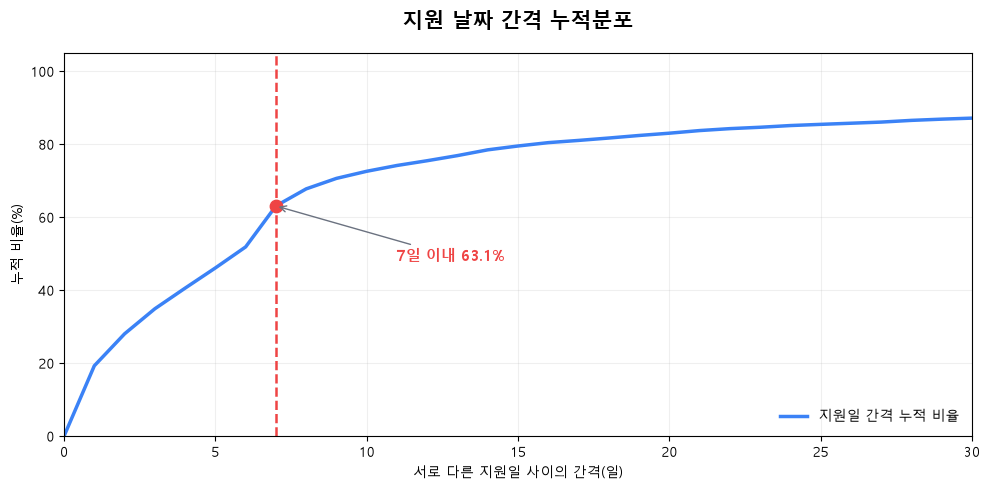

In [28]:
# 누적분포 계산
sorted_gaps = np.sort(gaps.to_numpy())

x = np.arange(0, 31)
y = np.searchsorted(
    sorted_gaps, x, side='right'
) / len(sorted_gaps) * 100

ratio_7d = (gaps <= 7).mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))

# 누적분포
ax.plot(
    x, y,
    color='#3B82F6',
    linewidth=2.5,
    label='지원일 간격 누적 비율'
)

# 7일 기준 강조
ax.axvline(
    7, color='#EF4444',
    linestyle='--', linewidth=1.8
)

ax.scatter(
    7, ratio_7d,
    color='#EF4444', s=80, zorder=3
)

ax.annotate(
    f'7일 이내 {ratio_7d:.1f}%',
    xy=(7, ratio_7d),
    xytext=(11, 48),
    fontsize=11,
    fontweight='bold',
    color='#EF4444',
    arrowprops=dict(
        arrowstyle='->',
        color='#6B7280'
    )
)

ax.set_title(
    '지원 날짜 간격 누적분포',
    fontsize=15, fontweight='bold', pad=18
)
ax.set_xlabel('서로 다른 지원일 사이의 간격(일)')
ax.set_ylabel('누적 비율(%)')

ax.set_xlim(0, 30)
ax.set_ylim(0, 105)
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.show()


#### 결과해석

- 서로 다른 지원 날짜 사이의 간격을 분석한 결과, 중앙값은 **6일**로 나타났다.
- 다음 지원일이 7일 이내인 간격은 **63.1%**, 14일 이내는 **78.5%**, 30일 이내는 **87.1%**로 확인되었다.
- 정확히 7일 간격으로 지원한 사례도 3,332건으로 나타나, 주 단위의 지원 활동이 존재함을 확인했다.
- 7일은 전체 지원일 간격의 과반을 포함하면서도 장기간 누적 지원보다 단기 지원 행동에 초점을 맞출 수 있는 관찰 기간이다.

**관찰 기간 선정**

- 기간별 지원량 분포와 지원일 간격 분석을 종합하여 **7일을 최종 관찰 기간으로 선정**한다.
- 다만 이는 단기간 대량 지원 행동을 식별하려는 분석 목적에 따른 선택이며, 허수지원 탐지의 최적 기간임을 의미하지는 않는다.



### 4-3. 대량 지원 임계값 도출: 3×IQR

**분석 목적**

7일을 최종 관찰 기간으로 선정했으므로, 사용자별 7일 최대 지원 횟수 분포를 바탕으로 대량 지원 기준을 도출한다.

**분석 방법**
- 사용자별 직전 7일 최대 지원 횟수를 계산한다.
- 지원 횟수 분포의 Q1, Q3 및 IQR을 확인한다.
- 극단값 경계인 **Q3 + 3×IQR**을 계산한다.
- 경계를 초과하는 첫 번째 정수를 대량 지원 임계값 후보로 설정한다.
- 해당 기준을 충족하는 사용자 수와 비율을 확인한다.

**기준 선정 방향**

이번 분석은 단순히 지원 횟수가 많은 사용자가 아니라, 일반적인 지원량 분포에서 상대적으로 극단적인 사용자를 식별하는 것이 목적이다. 따라서 3×IQR을 우선 검토하고, 이후 1.5×IQR과 비교하여 기준의 민감도를 확인한다.


In [29]:
# 사용자별 7일 최대 지원 횟수
volume_7d = (
    volume_period_app.groupby('user_uuid')['count_7d']
    .max()
    .rename('max_apply_7d')
)

# IQR 계산
q1 = volume_7d.quantile(0.25)
q3 = volume_7d.quantile(0.75)
iqr = q3 - q1

# 3×IQR 극단값 기준
upper_bound = q3 + 3 * iqr
cutoff = int(upper_bound) + 1

# 해당 사용자 수와 비율
target_users = (volume_7d >= cutoff).sum()
target_ratio = target_users / len(volume_7d) * 100

print(f'Q1: {q1:.1f}회')
print(f'Q3: {q3:.1f}회')
print(f'IQR: {iqr:.1f}회')
print(f'극단값 경계: {upper_bound:.1f}회')
print(f'최종 임계값 후보: {cutoff}회 이상')
print(f'해당 사용자 수: {target_users:,}명')
print(f'해당 비율: {target_ratio:.2f}%')

Q1: 1.0회
Q3: 4.0회
IQR: 3.0회
극단값 경계: 13.0회
최종 임계값 후보: 14회 이상
해당 사용자 수: 545명
해당 비율: 5.30%


#### 시각화 - 7일 최대 지원 횟수 분포

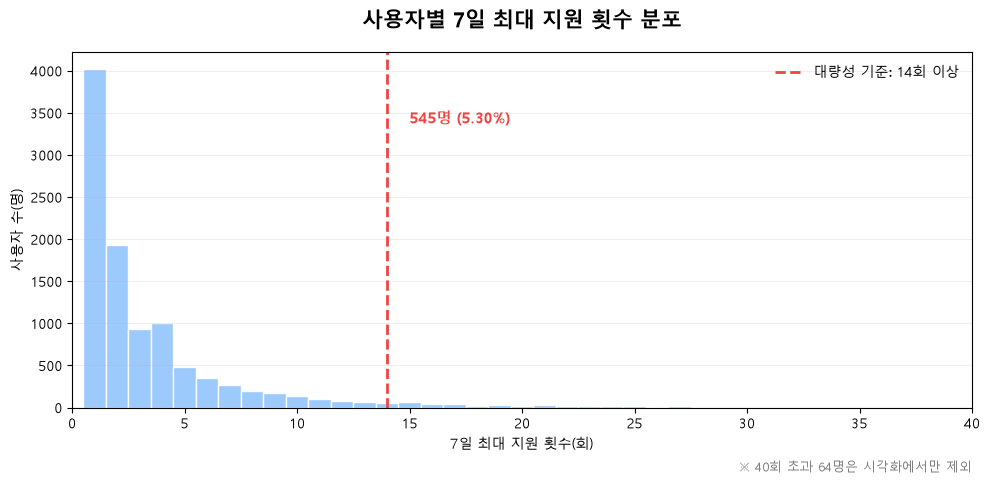

In [30]:
# 7일 최대 지원 횟수 분포
plot_data = volume_7d[volume_7d <= 40]
excluded_users = (volume_7d > 40).sum()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    plot_data,
    bins=np.arange(0.5, 41.5, 1),
    color='#93C5FD',
    edgecolor='white',
    alpha=0.9
)

# 대량성 임계값
ax.axvline(
    cutoff,
    color='#EF4444',
    linestyle='--',
    linewidth=2,
    label=f'대량성 기준: {cutoff}회 이상'
)

ax.text(
    cutoff + 1,
    ax.get_ylim()[1] * 0.8,
    f'{target_users:,}명 ({target_ratio:.2f}%)',
    color='#EF4444',
    fontsize=11,
    fontweight='bold'
)

ax.set_title(
    '사용자별 7일 최대 지원 횟수 분포',
    fontsize=15,
    fontweight='bold',
    pad=18
)
ax.set_xlabel('7일 최대 지원 횟수(회)')
ax.set_ylabel('사용자 수(명)')
ax.set_xlim(0, 40)
ax.grid(axis='y', alpha=0.2)
ax.legend(frameon=False)

ax.text(
    1, -0.18,
    f'※ 40회 초과 {excluded_users:,}명은 시각화에서만 제외',
    transform=ax.transAxes,
    ha='right',
    fontsize=9,
    color='gray'
)

plt.tight_layout()
plt.show()


#### 결과해석
- 사용자별 7일 최대 지원 횟수는 낮은 구간에 집중되어 있으며, 지원 횟수가 증가할수록 사용자 수가 감소하는 오른쪽 꼬리가 긴 분포를 보인다.
- 3×IQR 기준으로 도출한 **14회 이상**은 전체 분포의 오른쪽 꼬리에 위치하며, 해당 사용자는 545명(5.30%)이다.
- 이를 통해 14회 기준이 일반적인 지원량보다 상대적으로 극단적인 지원 행동을 구분하는 기준임을 시각적으로 확인했다.
- 다만 극단적인 지원량이 곧 허수지원이라는 의미는 아니므로, 다른 행동 지표와 결합하여 해석할 필요가 있다.




### 4-4. 임계값 민감도 분석

**분석 목적**

3×IQR 기준의 적절성을 검토하기 위해 일반적인 이상치 탐지 기준인 1.5×IQR과 비교한다.

**분석 방법**
- 동일한 7일 최대 지원 횟수 분포에 1.5×IQR과 3×IQR을 각각 적용한다.
- 기준별 임계값, 해당 사용자 수, 전체 대비 비율을 비교한다.
- 임계값 변화에 따라 분류되는 사용자 규모가 얼마나 달라지는지 확인한다.

**분석 시 고려사항**
- 1.5×IQR은 상대적으로 완화된 기준으로 더 많은 사용자를 포함한다.
- 3×IQR은 보다 극단적인 지원량을 보이는 사용자에 초점을 맞춘다.
- 이번 분석에서는 일반적인 다수 지원자보다 **단기간 지원량이 극단적으로 많은 사용자**를 식별하는 것이 목적이므로, 두 기준의 차이를 확인한 후 최종 기준을 선정한다.


In [31]:
# IQR 배수별 임계값 민감도 분석
sensitivity_rows = []

for multiplier in [1.5, 3.0]:
    boundary = q3 + multiplier * iqr
    threshold = int(boundary) + 1

    users = (volume_7d >= threshold).sum()
    ratio = users / len(volume_7d) * 100

    sensitivity_rows.append({
        'IQR 기준': f'{multiplier}×IQR',
        '극단값 경계': boundary,
        '지원 횟수 기준(회 이상)': threshold,
        '해당 사용자 수': users,
        '해당 비율(%)': round(ratio, 2)
    })

volume_sensitivity = pd.DataFrame(sensitivity_rows)

display(volume_sensitivity)

,IQR 기준,극단값 경계,지원 횟수 기준(회 이상),해당 사용자 수,해당 비율(%)
0,1.5×IQR,8.5,9,1107,10.76
1,3.0×IQR,13.0,14,545,5.30



#### 결과해석

- 1.5×IQR 기준에서는 7일 최대 지원 횟수 **9회 이상인 1,107명(10.76%)** 이 분류되었다.
- 3×IQR 기준에서는 **14회 이상인 545명(5.30%)** 이 분류되어, 1.5×IQR 대비 대상자가 562명(50.8%) 감소했다.
- 완화된 기준은 더 많은 사용자를 포함하지만, 일반적인 적극적 구직 활동까지 대량성 신호로 분류할 가능성이 있다.
- 이번 분석은 단기간 지원량이 극단적으로 많은 사용자를 식별하는 것이 목적이므로, 보다 엄격한 **3×IQR 기준을 최종 후보로 선정**했다.
- 다만 실제 허수지원 여부에 대한 정답 데이터가 없으므로, 3×IQR이 탐지 정확도 측면에서 우수하다고 단정할 수는 없다.


#### 시각화 - IQR 기준별 사용자수 비교

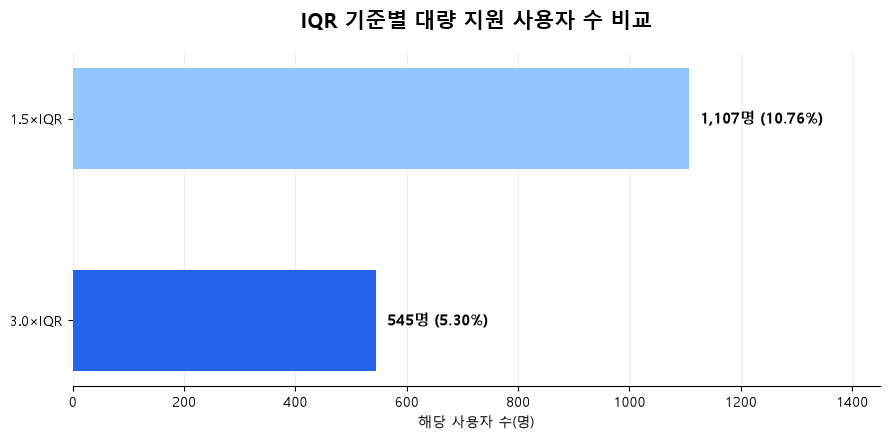

In [32]:
plot_df = volume_sensitivity.copy()

fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ['#93C5FD', '#2563EB']

bars = ax.barh(
    plot_df['IQR 기준'],
    plot_df['해당 사용자 수'],
    color=colors,
    height=0.5
)

# 엄격한 기준을 위쪽에 배치
ax.invert_yaxis()

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    width = bar.get_width()

    ax.text(
        width + 20,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["해당 사용자 수"]):,}명 '
        f'({row["해당 비율(%)"]:.2f}%)',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

ax.set_title(
    'IQR 기준별 대량 지원 사용자 수 비교',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('해당 사용자 수(명)')
ax.set_xlim(0, 1450)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

# 불필요한 테두리 제거
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


### 4-5. 연도별 기준 적용 시 결과 비교

**분석 목적**

앞서 선정한 7일·14회 기준이 특정 연도의 지원 행동에만 영향을 받은 결과인지 확인하기 위해, 2022년과 2023년을 구분하여 동일한 분석을 수행한다.

**분석 방법**
- Application 데이터를 2022년과 2023년으로 분리한다.
- 각 연도 내에서 사용자별 직전 7일 최대 지원 횟수를 다시 계산한다.
- 연도별 Q1, Q3, IQR 및 3×IQR 극단값 기준을 비교한다.
- 각 연도에서 도출된 기준을 충족하는 사용자 수와 비율을 확인한다.

**분석 시 고려사항**
- 연도별 지원량은 각 연도 데이터 내에서 독립적으로 계산한다.
- 2023년 1월의 지원량 계산에 2022년 12월 지원 이력이 포함되지 않도록 한다.
- 연도별 임계값의 일관성은 기준의 안정성을 검토하기 위한 것으로, 허수지원 탐지 정확도를 의미하지 않는다.


In [33]:
# 연도별 7일 최대 지원 횟수 및 3×IQR 기준 검증
yearly_rows = []

for year in [2022, 2023]:
    year_df = volume_period_app.loc[
        volume_period_app['cdate_kst'].dt.year == year,
        ['user_uuid', 'cdate_kst', 'one']
    ].copy()

    year_df = year_df.sort_values(
        ['user_uuid', 'cdate_kst']
    ).reset_index(drop=True)

    # 연도별 7일 이동 지원 횟수
    year_df['count_7d'] = (
        year_df.groupby('user_uuid')
        .rolling('7D', on='cdate_kst')['one']
        .sum()
        .to_numpy()
    )

    # 사용자별 연도 내 최대 지원 횟수
    year_max = (
        year_df.groupby('user_uuid')['count_7d']
        .max()
    )

    # IQR 기반 기준
    year_q1 = year_max.quantile(0.25)
    year_q3 = year_max.quantile(0.75)
    year_iqr = year_q3 - year_q1
    year_cutoff = int(year_q3 + 3 * year_iqr) + 1

    target = (year_max >= year_cutoff)

    yearly_rows.append({
        '연도': year,
        '사용자 수': len(year_max),
        'Q1': year_q1,
        'Q3': year_q3,
        'IQR': year_iqr,
        '3×IQR 기준(회 이상)': year_cutoff,
        '해당 사용자 수': target.sum(),
        '해당 비율(%)': round(target.mean() * 100, 2)
    })

volume_yearly_summary = pd.DataFrame(yearly_rows)

display(volume_yearly_summary)

,연도,사용자 수,Q1,Q3,IQR,3×IQR 기준(회 이상),해당 사용자 수,해당 비율(%)
0,2022,5846,1.0,4.0,3.0,14,302,5.17
1,2023,5725,1.0,4.0,3.0,14,293,5.12


#### 시각화 - 연도별 사용자비율

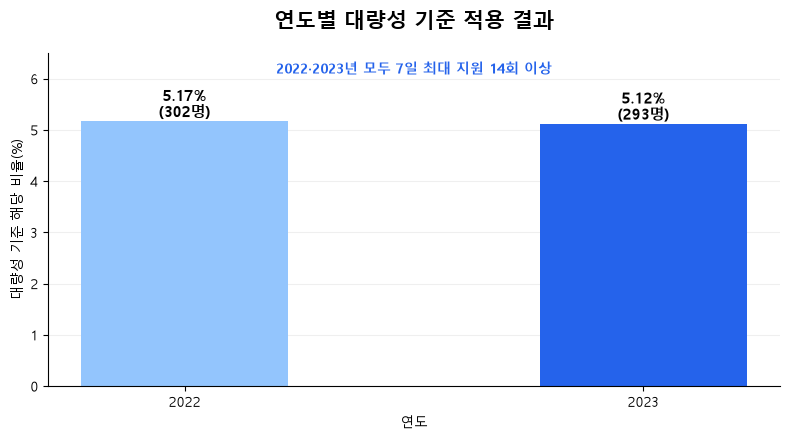

In [34]:
plot_df = volume_yearly_summary.copy()

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    plot_df['연도'].astype(str),
    plot_df['해당 비율(%)'],
    color=['#93C5FD', '#2563EB'],
    width=0.45
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f'{row["해당 비율(%)"]:.2f}%\n'
        f'({int(row["해당 사용자 수"]):,}명)',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

ax.set_title(
    '연도별 대량성 기준 적용 결과',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('연도')
ax.set_ylabel('대량성 기준 해당 비율(%)')
ax.set_ylim(0, 6.5)

ax.text(
    0.5, 6.1,
    '2022·2023년 모두 7일 최대 지원 14회 이상',
    ha='center',
    fontsize=10,
    color='#2563EB',
    fontweight='bold'
)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


#### 결과해석

- 2022년과 2023년 모두 사용자별 7일 최대 지원 횟수의 Q1은 1회, Q3는 4회, IQR은 3회로 동일하게 나타났다.
- 동일한 3×IQR 규칙을 적용한 결과, 두 연도 모두 **14회 이상**이라는 임계값이 도출되었다.
- 해당 사용자 비율은 2022년 5.17%, 2023년 5.12%로, 연도 간 차이는 **0.05%p**에 불과했다.
- 이를 통해 7일·14회 기준이 특정 연도의 분포에만 의존하지 않고 일관되게 나타남을 확인했다.
- 따라서 **7일 최대 지원 횟수 14회 이상**을 최종 대량성 기준으로 채택한다.

**해석 시 유의사항**

연도별 임계값의 일관성은 기준의 재현성을 뒷받침하지만, 실제 허수지원 탐지의 정확도를 검증한 것은 아니다.



## 4-6. 최종 대량성 점수 생성

**분석 목적**

앞서 도출한 대량성 기준을 전체 사용자에게 적용하여, 사용자별 대량 지원 행동 여부를 나타내는 이진 점수(`volume_score`)를 생성한다.

**점수 부여 기준**
- **0점:** 직전 7일 최대 지원 횟수 14회 미만
- **1점:** 직전 7일 최대 지원 횟수 14회 이상

**분석 방법**
- 사용자별 전체 분석 기간의 7일 최대 지원 횟수를 산출한다.
- 14회 이상 여부에 따라 0점 또는 1점을 부여한다.
- 전체 사용자 마스터 테이블과 결합하여 사용자별 1행으로 구성한다.
- 최종 점수별 사용자 수와 비율을 확인한다.

**해석 시 유의사항**

대량성 점수는 단기간 지원 규모가 상대적으로 극단적인지를 나타내는 행동 신호이며, 실제 허수지원 여부를 직접 판별하는 점수는 아니다.


,score,label,user_count,ratio
0,0,0점(해당없음),9742,94.7
1,1,1점(해당),545,5.3


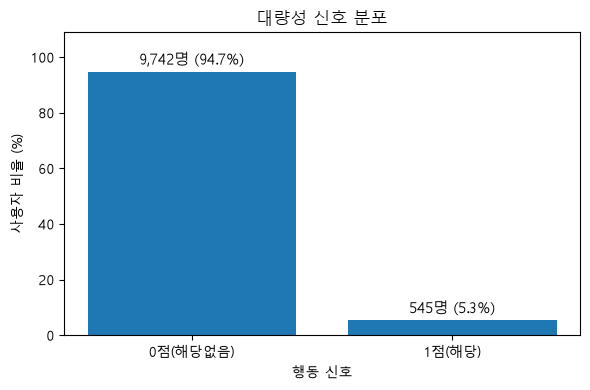

In [35]:
# 지원 이력에서 대량성 계산에 필요한 컬럼만 추출
applications = app_df[
    ['user_uuid', 'application_uuid', 'cdate_kst']
].copy()

# 지원 시각을 datetime 형식으로 변환
applications['cdate_kst'] = pd.to_datetime(
    applications['cdate_kst'],
    errors='coerce'
)

# 결측치 제거
applications = applications.dropna(
    subset=['user_uuid', 'application_uuid', 'cdate_kst']
).copy()

# 사용자별 시간순 정렬
applications = applications.sort_values(
    ['user_uuid', 'cdate_kst']
).reset_index(drop=True)

# 각 지원 건을 1회로 계산하기 위한 변수 생성
applications['application_count'] = 1


# 사용자별 각 지원 시점을 기준으로 직전 7일간 지원 횟수 계산
applications['applications_in_7d'] = (
    applications.groupby('user_uuid')
    .rolling(
        '7D',
        on='cdate_kst',
        closed='right'
    )['application_count']
    .sum()
    .to_numpy()
)


# 사용자별 연속 7일 내 최대 지원 횟수 및 전체 지원 횟수 집계
volume_metrics = (
    applications.groupby('user_uuid')
    .agg(
        max_7d=('applications_in_7d', 'max'),
        total_applications=('application_uuid', 'size')
    )
    .reset_index()
)

# 최대 지원 횟수를 정수형으로 변환
volume_metrics['max_7d'] = volume_metrics['max_7d'].astype(int)


# 대량성 점수 부여
# 연속 7일 내 최대 지원 횟수 14회 이상 → 1점
volume_metrics['volume_score'] = (
    volume_metrics['max_7d'] >= 14
).astype(int)


# 대량성 신호별 사용자 수 및 비율 요약 + 시각화
volume_summary = summarize_score(
    volume_metrics,
    'volume_score',
    '대량성'
)

In [36]:
# 대량성 점수 생성 결과 검증
print('전체 사용자 수:', f'{len(volume_metrics):,}명')
print('사용자 중복:', volume_metrics['user_uuid'].duplicated().sum(), '건')
print('점수 결측치:', volume_metrics['volume_score'].isna().sum(), '건')

# 점수 부여 기준 검증
assert volume_metrics['user_uuid'].is_unique
assert volume_metrics['volume_score'].isin([0, 1]).all()

assert (
    volume_metrics['volume_score']
    == (volume_metrics['max_7d'] >= 14).astype(int)
).all()

# 점수별 사용자 수 및 비율
volume_score_summary = (
    volume_metrics['volume_score']
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis('volume_score')
    .reset_index(name='사용자 수')
)

volume_score_summary['비율(%)'] = (
    volume_score_summary['사용자 수']
    / len(volume_metrics) * 100
).round(2)

display(volume_score_summary)

전체 사용자 수: 10,287명
사용자 중복: 0 건
점수 결측치: 0 건


,volume_score,사용자 수,비율(%)
0,0,9742,94.7
1,1,545,5.3



#### 결과 해석

- `volume_score = 1`은 **연속 7일 동안 최대 지원 횟수가 14회 이상**인 사용자로, 전체 10,287명 중 **545명(5.30%)**이 해당합니다.
- 지원 횟수가 많다는 사실만으로 허수지원 여부를 판단할 수 없으므로, 이후 집중성·다양성·탐색성 지표와 결합하여 복합적인 행동 특성을 분석합니다.
- 따라서 대량성 지표는 허수지원자를 직접 판별하는 기준이 아니라, **단기간에 상대적으로 극단적인 지원량을 보이는 사용자를 식별하기 위한 행동 피처(feature)**로 활용합니다.

---


# 5. 지표2 - 집중성

**분석 목적**

집중성은 사용자가 **짧은 시간 안에 연속적으로 지원하는 행동이 얼마나 반복되는지**를 나타내는 지표다.

단순히 지원 횟수가 많다는 이유만으로 집중성이 높다고 판단하기는 어렵다. 같은 10회 지원이라도 며칠에 걸쳐 지원한 사용자와 몇 분 간격으로 연속 지원한 사용자는 서로 다른 행동 특성을 보이기 때문이다.

따라서 사용자별 연속 지원 간격을 계산하고, 전체 지원 과정에서 짧은 간격의 지원이 차지하는 비율을 활용하여 집중적인 지원 행동을 식별하고자 한다.

1. 짧은 지원 간격 기준 검토

- 사용자별 지원 이력을 시간순으로 정렬하고, 직전 지원과의 간격을 분 단위로 계산한다.
- **3·5·10분**을 후보 기준으로 설정하여 짧은 간격의 연속 지원이 얼마나 발생하는지 비교한다.
- 지원 간격의 분포와 누적 비율을 확인하여 집중적인 지원 행동을 구분하기에 적절한 기준을 검토한다.

2. 최소 지원 횟수 조건 검토

- 지원 횟수가 적은 사용자는 짧은 지원 간격이 한두 번만 발생해도 집중성 비율이 높게 나타날 수 있다.
- 이러한 영향을 고려하여 최소 지원 횟수를 **2·3·5·10·20회**로 변경하며 분포의 변화를 비교한다.
- 최소 지원 횟수에 따른 집중성 비율의 안정성을 검토하여 분석 대상을 선정한다.
3. 집중성 비율 임계값 검토

- 사용자별 전체 연속 지원 간격 중 **5분 이내 간격이 차지하는 비율**을 집중성 지표로 활용한다.
- 집중성 비율의 상위 10% 수준인 P90을 확인하고, **50·65·80%** 등의 후보 기준을 비교한다.
- 기준 변화에 따른 사용자 수와 비율을 확인하여 최종 임계값을 선정한다.

**분석 방향**

1. 연속 지원 간격 분포 분석
2. 3·5·10분 기준 비교
3. 최소 지원 횟수별 민감도 분석
4. 집중성 비율 임계값 검토
5. 최종 집중성 점수 생성 및 검증

**유의사항:** 집중성은 짧은 간격의 반복 지원 행동을 나타내는 지표이며, 지원 속도가 빠르다는 사실만으로 허수지원 여부를 판단하지 않는다.



## 5-1. 연속 지원 간격 분포 분석

**분석 목적**

사용자별 연속 지원 간격의 분포를 확인하여, 짧은 시간 내 반복 지원 행동이 어느 정도 발생하는지 파악하고 집중성 지표의 시간 기준을 검토한다.

**분석 방법**
- 사용자별 지원 이력을 시간순으로 정렬한다.
- 동일 사용자의 직전 지원 시각과 현재 지원 시각의 차이를 분 단위로 계산한다.
- 지원 간격의 평균·중앙값·분위수를 확인한다.
- 3·5·10분 이내 연속 지원 간격의 누적 비율을 비교한다.

**분석 시 고려사항**
- 사용자별 최초 지원은 이전 지원 이력이 없으므로 간격 계산에서 제외한다.
- 지원 간격은 사용자 단위가 아닌 연속 지원 이벤트 단위로 집계한다.
- 짧은 지원 간격이 많다는 사실만으로 허수지원 여부를 판단하지 않는다.


In [37]:
# 집중성 분석용 지원 이력 생성
concentration_app = app_df[
    ['user_uuid', 'application_uuid', 'cdate_kst']
].copy()

concentration_app['cdate_kst'] = pd.to_datetime(
    concentration_app['cdate_kst'],
    errors='coerce'
)

# 필수 컬럼 결측치 제거
concentration_app = concentration_app.dropna(
    subset=['user_uuid', 'application_uuid', 'cdate_kst']
)

# 사용자별 지원 시각 정렬
concentration_app = (
    concentration_app
    .sort_values(['user_uuid', 'cdate_kst', 'application_uuid'])
    .reset_index(drop=True)
)

# 직전 지원 시각
concentration_app['prev_apply_at'] = (
    concentration_app.groupby('user_uuid')['cdate_kst']
    .shift(1)
)

# 연속 지원 간격(분)
concentration_app['interval_min'] = (
    (
        concentration_app['cdate_kst']
        - concentration_app['prev_apply_at']
    ).dt.total_seconds() / 60
)

# 최초 지원 제외
concentration_intervals = (
    concentration_app['interval_min']
    .dropna()
)

# 지원 간격 요약 통계
display(
    concentration_intervals.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    ).to_frame('지원 간격(분)')
)

# 시간 기준별 누적 비율
interval_ratio_summary = pd.DataFrame({
    '시간 기준(분)': [3, 5, 10],
    '누적 비율(%)': [
        round((concentration_intervals <= minutes).mean() * 100, 2)
        for minutes in [3, 5, 10]
    ]
})

display(interval_ratio_summary)

,지원 간격(분)
count,82239.000000
mean,11841.312739
std,55337.263326
min,0.000000
25%,2.350000
50%,15.633333
75%,4198.225000
90%,14791.530000
95%,39917.270000
max,986099.600000


,시간 기준(분),누적 비율(%)
0,3,29.28
1,5,37.46
2,10,46.02


#### 시각화 - 시간 기준별 누적 비율

3·5·10분 기준에 따라 얼마나 많은 연속 지원 간격이 포함되는지 비교

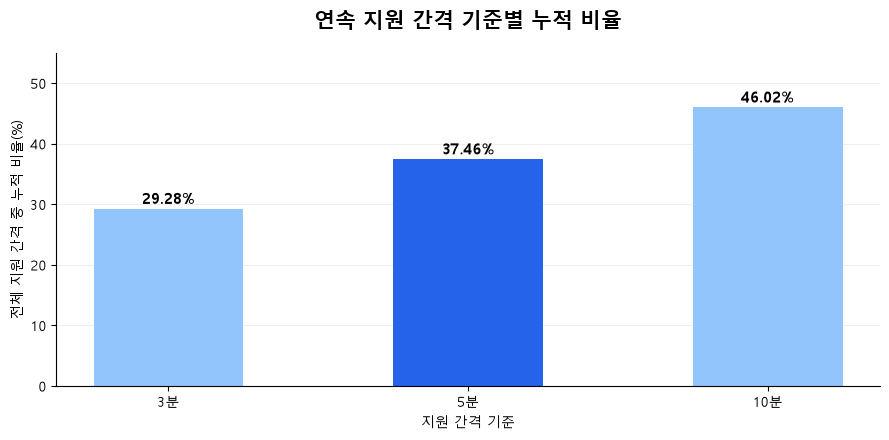

In [38]:
plot_df = interval_ratio_summary.copy()

fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ['#93C5FD', '#2563EB', '#93C5FD']

bars = ax.bar(
    plot_df['시간 기준(분)'].astype(str) + '분',
    plot_df['누적 비율(%)'],
    color=colors,
    width=0.5
)

for bar, ratio in zip(bars, plot_df['누적 비율(%)']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f'{ratio:.2f}%',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

ax.set_title(
    '연속 지원 간격 기준별 누적 비율',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('지원 간격 기준')
ax.set_ylabel('전체 지원 간격 중 누적 비율(%)')
ax.set_ylim(0, 55)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


#### 결과해석

- 전체 **82,239건**의 연속 지원 간격을 분석한 결과, 중앙값은 **15.63분**, 평균은 약 **8.22일**로 나타났다.
- 3분 이내 지원 간격은 **29.28%**, 5분 이내는 **37.46%**, 10분 이내는 **46.02%** 로 확인되었다.
- 5분 기준은 매우 짧은 간격에 집중하는 3분과 상대적으로 넓은 범위를 포함하는 10분 사이의 중간 기준이다.
- 따라서 **5분을 집중성 시간 기준 후보로 선정**하고, 이후 사용자별 반복 지원 비율을 비교하여 적절성을 검토한다.



## 5-2. 시간 기준별 사용자 집중성 비율 비교

**분석 목적**

전체 지원 간격 분포를 통해 3·5·10분 기준의 차이를 확인했다. 이번에는 각 기준을 사용자 단위로 적용하여, 짧은 간격의 지원 행동이 사용자별로 얼마나 반복되는지 비교한다.

**분석 방법**
- 사용자별 전체 연속 지원 간격 수를 계산한다.
- 3·5·10분 이내에 발생한 연속 지원 간격의 비율을 각각 산출한다.
- 기준별 사용자 집중성 비율의 중앙값, P75, P90을 비교한다.
- 시간 기준 변화에 따른 분포 차이를 확인하여 최종 시간 기준을 검토한다.

**분석 시 고려사항**
- 최초 지원은 직전 지원 이력이 없으므로 간격 비율 계산에서 제외한다.
- 사용자별 지원 횟수에 따라 집중성 비율의 안정성이 달라질 수 있으므로, 이번 단계에서는 분포를 먼저 비교하고 이후 최소 지원 횟수 조건을 검토한다.
- 집중성 비율은 지원 속도의 반복성을 나타내며, 허수지원 여부를 직접 의미하지 않는다.


In [39]:
# 사용자별 연속 지원 간격 수
valid_intervals = concentration_app.dropna(
    subset=['interval_min']
).copy()

concentration_user = (
    valid_intervals.groupby('user_uuid')
    .agg(
        interval_count=('interval_min', 'size')
    )
)

# 시간 기준별 사용자 집중성 비율
for minutes in [3, 5, 10]:
    concentration_user[f'ratio_{minutes}m'] = (
        valid_intervals['interval_min'].le(minutes)
        .groupby(valid_intervals['user_uuid'])
        .mean()
    )

# 시간 기준별 분포 요약
concentration_time_summary = pd.DataFrame([
    {
        '시간 기준': f'{minutes}분',
        '사용자 수': len(concentration_user),
        '중앙값(%)': round(
            concentration_user[f'ratio_{minutes}m'].median() * 100, 2
        ),
        'P75(%)': round(
            concentration_user[f'ratio_{minutes}m'].quantile(0.75) * 100, 2
        ),
        'P90(%)': round(
            concentration_user[f'ratio_{minutes}m'].quantile(0.90) * 100, 2
        )
    }
    for minutes in [3, 5, 10]
])

display(concentration_time_summary)

,시간 기준,사용자 수,중앙값(%),P75(%),P90(%)
0,3분,6973,0.0,27.27,50.00
1,5분,6973,12.5,38.89,63.98
2,10분,6973,25.0,50.00,78.26


#### 시각화 - 시간 기준별 집중성 비율 분포
중앙값·P75·P90을 비교를 통해 5분 기준이 각 분위수에서 어디에 위치하는지 확인

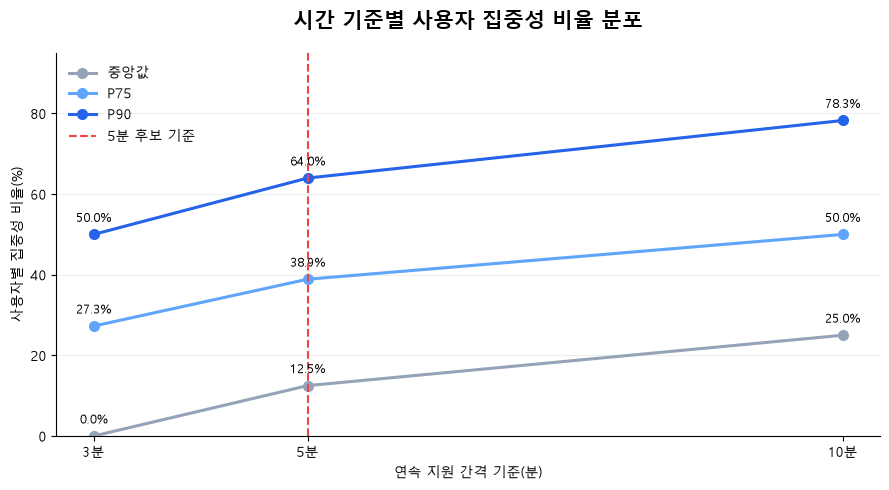

In [40]:
plot_df = concentration_time_summary.copy()
x = [3, 5, 10]

fig, ax = plt.subplots(figsize=(9, 5))

for col, color, label in [
    ('중앙값(%)', '#94A3B8', '중앙값'),
    ('P75(%)', '#60A5FA', 'P75'),
    ('P90(%)', '#2563EB', 'P90')
]:
    ax.plot(
        x, plot_df[col],
        marker='o',
        markersize=7,
        linewidth=2.2,
        color=color,
        label=label
    )

    for xi, yi in zip(x, plot_df[col]):
        ax.annotate(
            f'{yi:.1f}%',
            (xi, yi),
            xytext=(0, 9),
            textcoords='offset points',
            ha='center',
            fontsize=9
        )

ax.axvline(
    5,
    color='#EF4444',
    linestyle='--',
    linewidth=1.5,
    label='5분 후보 기준'
)

ax.set_title(
    '시간 기준별 사용자 집중성 비율 분포',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('연속 지원 간격 기준(분)')
ax.set_ylabel('사용자별 집중성 비율(%)')
ax.set_xticks(x)
ax.set_xticklabels(['3분', '5분', '10분'])
ax.set_ylim(0, 95)
ax.grid(axis='y', alpha=0.2)
ax.legend(frameon=False)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

#### 결과해석

- 연속 지원 간격이 존재하는 **6,973명**을 대상으로 3·5·10분 기준의 사용자별 집중성 비율을 비교했다.
- 시간 기준이 길어질수록 집중성 비율이 증가했으며, P90은 각각 **50.00%·63.98%·78.26%** 로 나타났다.
- **5분 기준**은 3분보다 짧은 간격의 반복 지원을 폭넓게 포착하면서도, 10분보다 엄격하게 구분할 수 있는 중간 기준이다.
- 따라서 **5분을 집중성 시간 기준 후보로 선정**하고, 이후 최소 지원 횟수별 민감도 분석을 통해 적절성을 추가 검토한다.



## 5-3. 최소 지원 횟수별 민감도 분석

**분석 목적**

지원 횟수가 적은 사용자는 짧은 간격의 지원이 한두 번만 발생해도 집중성 비율이 높게 나타날 수 있다. 따라서 최소 지원 횟수 조건을 변경하면서 사용자별 집중성 비율의 분포가 얼마나 달라지는지 확인한다.

**분석 방법**
- 최소 지원 횟수를 **2·3·5·10·20회**로 설정한다.
- 각 조건을 충족하는 사용자의 5분 이내 연속 지원 비율을 계산한다.
- 조건별 사용자 수, 중앙값, P75, P90을 비교한다.
- 최소 지원 횟수가 증가할 때 집중성 비율의 분포가 안정적으로 유지되는지 검토한다.

**분석 시 고려사항**
- 사용자별 집중성 비율의 분모는 전체 연속 지원 간격 수(지원 횟수 - 1)로 계산한다.
- 최소 지원 횟수 조건이 높아질수록 분석 대상 사용자 수가 감소할 수 있다.
- 특정 최소 지원 횟수가 통계적으로 최적이라는 의미보다는, 비율의 변동성과 분석 대상 규모를 함께 고려하여 기준을 선정한다.


In [41]:
# 사용자별 전체 지원 횟수 추가
concentration_user['total_applications'] = (
    concentration_app.groupby('user_uuid')['application_uuid']
    .size()
)

# 최소 지원 횟수별 집중성 비율 분포
min_apply_rows = []

for min_count in [2, 3, 5, 10, 20]:
    target = concentration_user.loc[
        concentration_user['total_applications'] >= min_count,
        'ratio_5m'
    ]

    min_apply_rows.append({
        '최소 지원 횟수': min_count,
        '사용자 수': len(target),
        '중앙값(%)': round(target.median() * 100, 2),
        'P75(%)': round(target.quantile(0.75) * 100, 2),
        'P90(%)': round(target.quantile(0.90) * 100, 2)
    })

concentration_min_summary = pd.DataFrame(min_apply_rows)

display(concentration_min_summary)

,최소 지원 횟수,사용자 수,중앙값(%),P75(%),P90(%)
0,2,6973,12.5,38.89,63.98
1,3,5576,20.0,41.67,60.00
2,5,4016,25.0,42.86,61.11
3,10,2214,30.0,47.37,64.71
4,20,877,37.5,55.41,69.42


#### 시각화 - 최소 지원 횟수별 P90 및 사용자수
최소 지원 횟수를 높이면 대상 규모가 얼마나 줄어드는지, P90은 어떻게 변하는지 확인

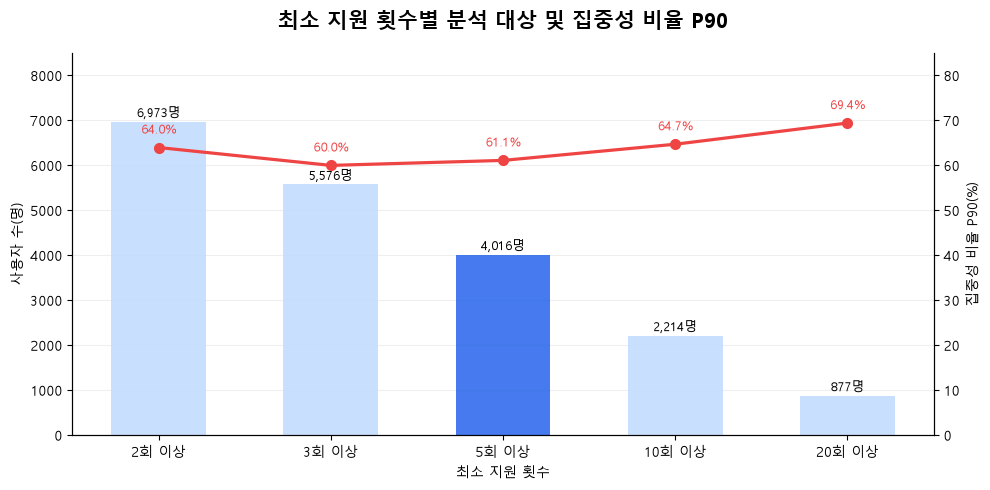

In [42]:
plot_df = concentration_min_summary.copy()

fig, ax1 = plt.subplots(figsize=(10, 5))

x = range(len(plot_df))

# 사용자 수
bars = ax1.bar(
    x,
    plot_df['사용자 수'],
    color=['#BFDBFE', '#BFDBFE', '#2563EB', '#BFDBFE', '#BFDBFE'],
    width=0.55,
    alpha=0.85,
    label='사용자 수'
)

for bar, value in zip(bars, plot_df['사용자 수']):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f'{value:,}명',
        ha='center',
        fontsize=9
    )

ax1.set_ylabel('사용자 수(명)')
ax1.set_ylim(0, 8500)

# P90
ax2 = ax1.twinx()

ax2.plot(
    x,
    plot_df['P90(%)'],
    color='#EF4444',
    marker='o',
    linewidth=2.3,
    markersize=7,
    label='집중성 비율 P90'
)

for xi, value in zip(x, plot_df['P90(%)']):
    ax2.annotate(
        f'{value:.1f}%',
        (xi, value),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        color='#EF4444'
    )

ax2.set_ylabel('집중성 비율 P90(%)')
ax2.set_ylim(0, 85)

ax1.set_xticks(list(x))
ax1.set_xticklabels(
    [f'{n}회 이상' for n in plot_df['최소 지원 횟수']]
)

ax1.set_title(
    '최소 지원 횟수별 분석 대상 및 집중성 비율 P90',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax1.set_xlabel('최소 지원 횟수')
ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

for ax in [ax1, ax2]:
    ax.spines['top'].set_visible(False)

plt.tight_layout()
plt.show()


#### 결과해석

- 최소 지원 횟수가 증가할수록 분석 대상은 감소하고, 집중성 비율의 중앙값은 증가했다.
- 최소 2~10회 조건에서 P90은 약 60~65%로 비교적 유사하게 나타났다.
- 지원 횟수가 적으면 일부 짧은 간격만으로도 집중성 비율이 높아질 수 있으므로, 최소 지원 횟수 조건이 필요하다.
- 따라서 **분석 대상 규모와 비율의 안정성을 고려하여 5회 이상(4,016명)을 우선 기준으로 선정**했다.



## 5-4. 집중성 비율 임계값 검토

**분석 목적**

최소 5회 이상 지원자를 대상으로 집중성 비율의 임계값을 비교하여, 짧은 간격의 반복 지원이 두드러지는 사용자를 식별할 기준을 검토한다.

**분석 방법**
- 사용자별 5분 이내 연속 지원 비율을 계산한다.
- 집중성 비율의 P90을 참고하여 **50%·65%·80%**를 후보 기준으로 설정한다.
- 기준별 해당 사용자 수와 비율을 비교하여 임계값 변화에 따른 민감도를 확인한다.

**분석 시 고려사항**
- 집중성 비율이 높다는 것은 짧은 간격의 지원이 반복되는 정도가 높다는 의미다.
- 최종 기준은 분포와 분류 규모를 함께 고려하여 선정하며, 허수지원 탐지 정확도를 의미하지 않는다.


In [43]:
# 최소 5회 이상 지원자
concentration_target = concentration_user.loc[
    concentration_user['total_applications'] >= 5
].copy()

# 집중성 비율 분포 확인
print('분석 대상:', f'{len(concentration_target):,}명')
print(
    '집중성 비율 P90:',
    f'{concentration_target["ratio_5m"].quantile(0.90) * 100:.2f}%'
)

# 임계값별 민감도 분석
threshold_rows = []

for threshold in [0.50, 0.65, 0.80]:
    target = concentration_target['ratio_5m'] >= threshold

    threshold_rows.append({
        '집중성 비율 기준(%)': int(threshold * 100),
        '해당 사용자 수': int(target.sum()),
        '해당 비율(%)': round(target.mean() * 100, 2)
    })

concentration_threshold_summary = pd.DataFrame(threshold_rows)

display(concentration_threshold_summary)

분석 대상: 4,016명
집중성 비율 P90: 61.11%


,집중성 비율 기준(%),해당 사용자 수,해당 비율(%)
0,50,834,20.77
1,65,333,8.29
2,80,129,3.21


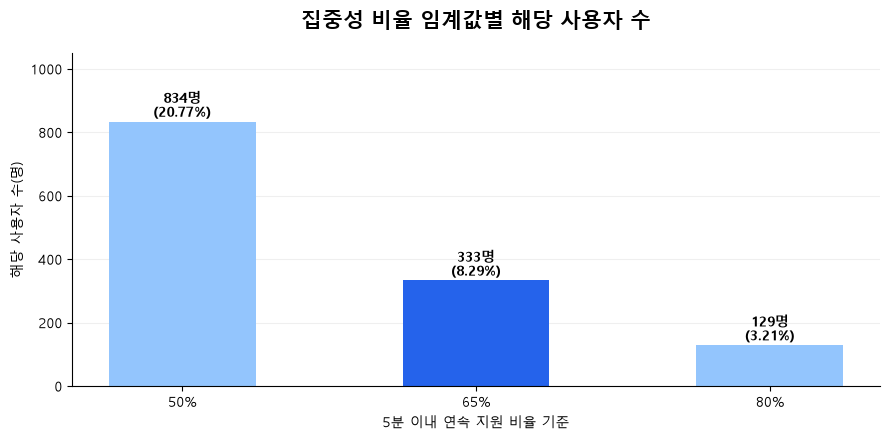

In [44]:
# 집중성 비율 임계값별 사용자 수 시각화
plot_df = concentration_threshold_summary.copy()

fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ['#93C5FD', '#2563EB', '#93C5FD']

bars = ax.bar(
    plot_df['집중성 비율 기준(%)'].astype(str) + '%',
    plot_df['해당 사용자 수'],
    color=colors,
    width=0.5
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f'{int(row["해당 사용자 수"]):,}명\n'
        f'({row["해당 비율(%)"]:.2f}%)',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    '집중성 비율 임계값별 해당 사용자 수',
    fontsize=15,
    fontweight='bold',
    pad=18
)
ax.set_xlabel('5분 이내 연속 지원 비율 기준')
ax.set_ylabel('해당 사용자 수(명)')
ax.set_ylim(0, 1050)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


#### 결과해석

- 집중성 비율 기준이 높아질수록 해당 사용자는 **834명(20.77%)에서 129명(3.21%)** 으로 감소했다.
- 65% 기준에서는 **333명(8.29%)** 이 분류되어, P90(61.11%)보다 엄격하면서도 80% 기준보다 많은 사용자를 포착했다.
- 따라서 **5분 이내 연속 지원 비율 65% 이상**을 최종 집중성 임계값 후보로 선정했다.



## 5-5. 최종 집중성 점수 생성

**분석 목적**

앞서 검토한 집중성 지표를 사용자별 점수로 변환하여, 짧은 시간 내 반복 지원 행동이 두드러지는 사용자를 식별한다.

**최종 점수 기준**
- **1점:** 최소 5회 이상 지원하고, 5분 이내 연속 지원 비율이 평가 대상의 **P90(상위 10% 기준값) 이상**인 사용자
- **0점:** 위 조건을 충족하지 않는 사용자

**기준 선정 근거**
- 5분: 짧은 간격의 반복 지원을 포착하기 위한 시간 기준
- 5회 이상: 최소 4개의 연속 지원 간격 확보
- P90: 집중성 비율이 높은 상위 집단을 구분하기 위한 분포 기반 임계값

※ P90은 실제 데이터에서 산출하며, 동점자에 따라 1점 사용자 비율은 정확히 10%가 아닐 수 있다.


[집중성 기준] 5회 이상 지원 & 5분 이내 연속 지원 비율 P90 이상 (0.6111, 61.1%)
집중성 평가 대상: 4,016명


,score,label,user_count,ratio
0,0,0점(해당없음),9882,96.1
1,1,1점(해당),405,3.9


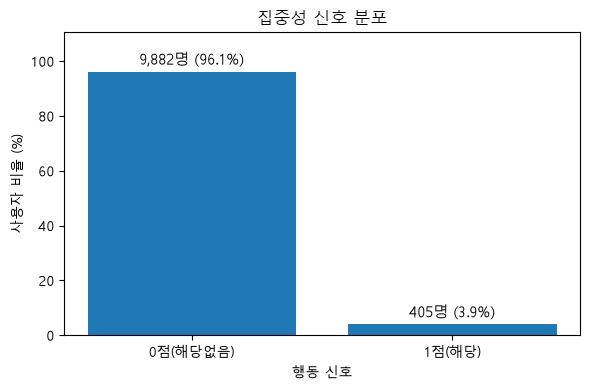

In [45]:
# 집중성 계산에 필요한 컬럼 추출
app_focus = app_df[
    ['user_uuid', 'application_uuid', 'cdate_kst']
].copy()

# 지원 시각을 datetime 형식으로 변환
app_focus['cdate_kst'] = pd.to_datetime(
    app_focus['cdate_kst'],
    errors='coerce'
)

# 결측치 제거
app_focus = app_focus.dropna(
    subset=['user_uuid', 'application_uuid', 'cdate_kst']
).copy()

# 사용자별 지원 기록을 시간순으로 정렬
app_focus = app_focus.sort_values(
    ['user_uuid', 'cdate_kst', 'application_uuid']
).reset_index(drop=True)


# 1. 사용자별 지원 간격 계산
# 동일 사용자의 직전 지원과 현재 지원 사이의 시간 차이(분)
app_focus['interval_minutes'] = (
    app_focus.groupby('user_uuid')['cdate_kst']
    .diff()
    .dt.total_seconds() / 60
)


# 2. 5분 이내 연속 지원 여부 생성
# 첫 번째 지원은 비교 대상이 아니므로 NaN 유지
app_focus['within_5min'] = np.where(
    app_focus['interval_minutes'].notna(),
    app_focus['interval_minutes'].le(5).astype(float),
    np.nan
)


# 3. 사용자별 집중성 비율 계산
concentration_metrics = (
    app_focus.groupby('user_uuid')
    .agg(
        total_apps=('application_uuid', 'size'),
        concentration_ratio=('within_5min', 'mean')
    )
    .reset_index()
)


# 4. 집중성 점수 부여
# 최소 5회 이상 지원한 사용자만 평가
concentration_target = concentration_metrics[
    concentration_metrics['total_apps'] >= 5
].copy()

# 평가 대상의 집중성 비율 P90 산출
p90_threshold = concentration_target[
    'concentration_ratio'
].quantile(0.90)

# 5회 이상 지원 & 집중성 비율 P90 이상 → 1점
concentration_metrics['concentration_score'] = (
    (concentration_metrics['total_apps'] >= 5) &
    (concentration_metrics['concentration_ratio'] >= p90_threshold)
).astype(int)


# 5. 결과 확인
print(
    f'[집중성 기준] 5회 이상 지원 & '
    f'5분 이내 연속 지원 비율 P90 이상 '
    f'({p90_threshold:.4f}, {p90_threshold * 100:.1f}%)'
)

print(f'집중성 평가 대상: {len(concentration_target):,}명')


# 6. 집중성 점수 요약표 및 시각화
concentration_summary = summarize_score(
    concentration_metrics,
    'concentration_score',
    '집중성'
)


#### 결과해석

- 최소 5회 이상 지원한 **4,016명**의 5분 이내 연속 지원 비율을 분석한 결과, P90은 **61.11%** 로 나타났다.
- 최종적으로 전체 사용자 10,287명 중 **405명(3.9%)** 이 집중성 1점, **9,882명(96.1%)* *이 0점으로 분류되었다.
- `concentration_score = 1`은 짧은 시간 내 반복 지원 비율이 상대적으로 높은 사용자를 의미하며, 허수지원 여부를 단독으로 판단하지 않는다.
- 해당 신호는 이후 대량성·다양성·탐색성 지표와 결합하여 복합 행동 패턴을 분석하는 데 활용한다.


# 6. 지표 3 — 다양성 

- 지원 직무 고유수가 3개 이상이면 1점
- 지원 직무 고유수가 2개인 지원자 중 서로 다른 직무 스위칭 최소 간격이 222분 미만이거나 직무 스위칭 횟수가 4번 이상이면 1점

In [46]:
diversity_df = app_job_df.dropna(subset=['job_field']).copy()

print(f"정제 후 분석 가능한 데이터 수: {len(diversity_df):,}건")

정제 후 분석 가능한 데이터 수: 91,406건


In [47]:
diversity_df.isna().sum()

cdate                     0
company_uuid_app          0
job_uuid                  0
user_uuid                 0
application_uuid          0
cdate_kst_app             0
cdate_kst_job             0
mdate_kst                 0
job_field                 0
career_type_string        0
end_date              18898
allow_remote              0
can_show_salary           0
company_uuid_job          0
dtype: int64

end_date의 결측치는 '상시 채용'이거나 '마감일이 따로 없는 공고'로 보고 그대로 둠.

## 6-1. 다양성 기본 피처 생성

In [48]:
# 사용자별 지원 시각 datetime 변환
diversity_df['cdate_kst_app'] = pd.to_datetime(
    diversity_df['cdate_kst_app'],
    errors='coerce'
)

# 지원 시각 및 사용자 식별자가 없는 행 제외
diversity_df = diversity_df.dropna(
    subset=['user_uuid', 'cdate_kst_app']
).copy()

# 사용자별 지원 시간순 정렬
diversity_df = diversity_df.sort_values(
    ['user_uuid', 'cdate_kst_app']
).reset_index(drop=True)


# --------------------
# 1-1. 사용자별 지원직무 고유수

# 사용자가 지원한 서로 다른 직무의 개수
diversity_df['지원직무고유수'] = (
    diversity_df.groupby('user_uuid')['job_field']
    .transform('nunique')
)


# -------------------------------------
# 1-2. 직전 지원과의 시간 간격 및 직무 변경 여부

# 직전 지원 시간
diversity_df['prev_time'] = (
    diversity_df.groupby('user_uuid')['cdate_kst_app']
    .shift(1)
)

# 직전 지원과 현재 지원 사이의 시간 간격(초)
diversity_df['time_diff_seconds'] = (
    diversity_df['cdate_kst_app'] - diversity_df['prev_time']
).dt.total_seconds()

# 직전 지원의 직무
diversity_df['prev_job'] = (
    diversity_df.groupby('user_uuid')['job_field']
    .shift(1)
)

# 직전 지원과 다른 직무로 변경했는지 여부
# 직무 정보가 모두 존재하는 경우에만 변경 여부 판단
diversity_df['job_changed'] = (
    diversity_df['job_field'].notna() &
    diversity_df['prev_job'].notna() &
    (diversity_df['job_field'] != diversity_df['prev_job'])
)


# ----------------------
# 1-3. 사용자별 직무스위칭횟수

user_switching_count = (
    diversity_df.groupby('user_uuid')['job_changed']
    .sum()
    .reset_index(name='직무스위칭횟수')
)

# 기존 실행으로 생성된 컬럼이 있다면 제거해 중복 병합 방지
diversity_df = diversity_df.drop(
    columns=['직무스위칭횟수'],
    errors='ignore'
)

# 지원 건 단위 데이터에 사용자별 스위칭 횟수 결합
diversity_df = diversity_df.merge(
    user_switching_count,
    on='user_uuid',
    how='left',
    validate='many_to_one'
)

# 결과 확인
display(
    diversity_df[
        [
            'user_uuid',
            'cdate_kst_app',
            'job_field',
            '지원직무고유수',
            'time_diff_seconds',
            'job_changed',
            '직무스위칭횟수'
        ]
    ].head(10)
)

,user_uuid,cdate_kst_app,job_field,지원직무고유수,time_diff_seconds,job_changed,직무스위칭횟수
0,0002535c-eacb-456b-a620-92c917332ba3,2022-07-23 13:08:40+09:00,디자인,1,NaN,False,0
1,0002535c-eacb-456b-a620-92c917332ba3,2022-10-19 10:35:41+09:00,디자인,1,7594021.0,False,0
2,000b55ad-5c86-438b-a5b0-9ea3a2917789,2023-07-06 20:12:17+09:00,기획/PM,2,NaN,False,1
3,000b55ad-5c86-438b-a5b0-9ea3a2917789,2023-07-07 18:21:12+09:00,마케팅,2,79735.0,True,1
4,000b55ad-5c86-438b-a5b0-9ea3a2917789,2023-07-12 16:11:34+09:00,마케팅,2,424222.0,False,1
5,0017a738-4fcc-441e-983b-a6033890a9db,2022-04-19 17:19:40+09:00,SW 개발,1,NaN,False,0
6,003a83bd-6cb7-4f99-ab3a-66904df762e2,2022-08-17 17:33:35+09:00,SW 개발,1,NaN,False,0
7,00495153-f908-4523-9d0d-5b93a57196a4,2022-01-14 17:34:45+09:00,마케팅,1,NaN,False,0
8,00495153-f908-4523-9d0d-5b93a57196a4,2022-01-17 17:02:23+09:00,마케팅,1,257258.0,False,0
9,00495153-f908-4523-9d0d-5b93a57196a4,2022-02-25 18:22:10+09:00,마케팅,1,3374387.0,False,0


## 6-2. 지원 직무 고유수별 분포 확인

- 대부분의 사용자가 하나의 직무에만 지원할까?

In [49]:
# 사용자 단위 테이블 생성
user_diversity = (
    diversity_df[['user_uuid', '지원직무고유수', '직무스위칭횟수']]
    .drop_duplicates(subset=['user_uuid'])
    .copy()
)

# 지원직무 고유수별 사용자 수
job_count_summary = (
    user_diversity['지원직무고유수'].value_counts()
    .sort_index()
    .rename_axis('지원직무고유수')
    .reset_index(name='유저수')
)

# 비율 계산
job_count_summary['비율(%)'] = (job_count_summary['유저수'] / job_count_summary['유저수'].sum()* 100).round(2)
job_count_summary

,지원직무고유수,유저수,비율(%)
0,1,8559,83.77
1,2,1046,10.24
2,3,361,3.53
3,4,139,1.36
4,5,70,0.69
5,6,23,0.23
6,7,10,0.10
7,8,3,0.03
8,9,3,0.03
9,10,3,0.03


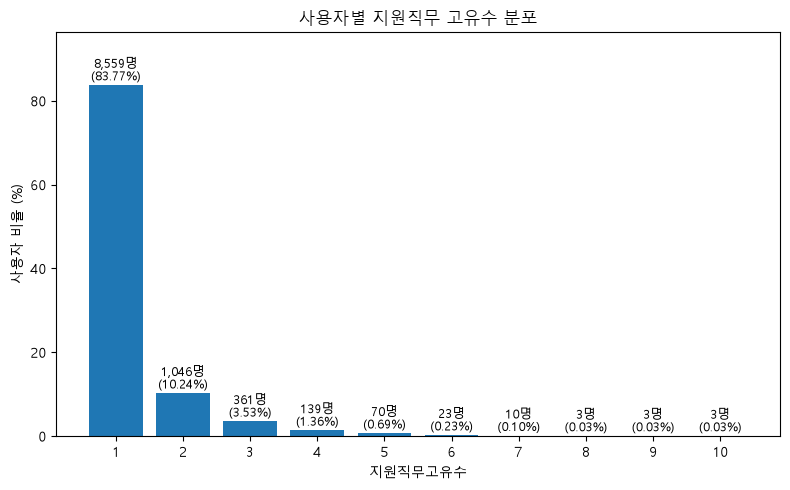

In [50]:
# 분포 시각화
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    job_count_summary['지원직무고유수'].astype(str),
    job_count_summary['비율(%)']
)

# 유저수 + 비율 표시
for bar, count, ratio in zip(
    bars,
    job_count_summary['유저수'],
    job_count_summary['비율(%)']
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{count:,}명\n({ratio:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax.set_title('사용자별 지원직무 고유수 분포')
ax.set_xlabel('지원직무고유수')
ax.set_ylabel('사용자 비율 (%)')

ax.set_ylim(
    0,
    job_count_summary['비율(%)'].max() * 1.15
)

plt.tight_layout()
plt.show()

전체 사용자의 약 84%가 1개의 직무에만 지원하며, 복수 직무에 지원하는 사용자는 상대적으로 적게 나타났다.

그렇다면 복수 직무 지원자들의 행동에는 어떤 특징이 있을까?

## 6-3. 복수 직무 지원자 행동 특징

### 6-3-1. 지원 직무 고유수별 최소 지원 간격
각 사용자의 전체 지원 중 가장 짧은 지원의 간격 계산

- 지원한 직무의 수가 많아질수록 지원 속도도 비정상적으로 빨라지는가?

In [51]:
# 사용자별 전체 지원 중 최소 지원 간격(분)
user_min_diff = (
    diversity_df.groupby('user_uuid')['time_diff_seconds'].min().div(60)
    .reset_index(name='min_time_diff')
)

# 사용자별 지원직무고유수 결합
diversity_span = user_diversity[['user_uuid', '지원직무고유수']].merge(
    user_min_diff,
    on='user_uuid',
    how='left'
)

# 복수 직무 지원자만 분석
summary_by_job_count = (
    diversity_span[diversity_span['지원직무고유수'] >= 2]
    .groupby('지원직무고유수')['min_time_diff']
    .describe()
)

pretty_summary = summary_by_job_count[['count', 'mean', 'min', '50%', 'max']].copy()
pretty_summary.columns = [
    '유저 수',
    '평균 간격',
    '최소 간격',
    '중앙값(50%)',
    '최대 간격'
]
pretty_summary.round(1)

,유저 수,평균 간격,최소 간격,중앙값(50%),최대 간격
지원직무고유수,,,,,
2,1046.0,11258.9,0.0,4.8,696601.3
3,361.0,1497.2,0.0,2.1,76323.1
4,139.0,469.2,0.0,1.6,11456.6
5,70.0,129.7,0.0,1.1,4265.4
6,23.0,1.0,0.0,0.6,4.7
7,10.0,0.5,0.0,0.5,1.5
8,3.0,0.3,0.0,0.2,0.6
9,3.0,0.2,0.0,0.2,0.4
10,3.0,0.1,0.0,0.0,0.3


평균 > 중앙값, 오른쪽으로 꼬리가 긴 분포

### 6-3-2. 60초 미만 초고속 지원 사용자 확인

In [52]:
# 한 번이라도 60초 미만으로 다음 지원을 한 사용자
rapid_users = diversity_df.loc[
    diversity_df['time_diff_seconds'] < 60,
    'user_uuid'
].unique()

# 사용자별 60초 미만 지원 경험 여부
user_diversity['is_rapid'] = user_diversity['user_uuid'].isin(rapid_users)

# 고유직무수 2개 이상 사용자만 비교
rapid_summary = user_diversity[user_diversity['지원직무고유수'] >= 2].groupby('지원직무고유수').agg(
    전체유저수=('user_uuid', 'nunique'),
    초고속지원유저수=('is_rapid', 'sum')
).reset_index()

rapid_summary['초고속지원비율(%)'] = (rapid_summary['초고속지원유저수'] / rapid_summary['전체유저수']* 100).round(1)
rapid_summary

,지원직무고유수,전체유저수,초고속지원유저수,초고속지원비율(%)
0,2,1046,215,20.6
1,3,361,108,29.9
2,4,139,50,36.0
3,5,70,31,44.3
4,6,23,15,65.2
5,7,10,9,90.0
6,8,3,3,100.0
7,9,3,3,100.0
8,10,3,3,100.0


지원 직무가 많아질수록 매우 짧은 간격의 연속 지원 행동도 함께 증가한다.

### 6-3-3. 60초 미만 초고속 지원자 제외
일반적인 복수 직무 지원자의 행동을 보기 위해,  
지원직무고유수 2~7개 사용자 중 60초 미만 지원 경험이 있는 사용자를 제외하고 잔여 사용자를 대상으로 세부 분석 진행.  
(8~10개 지원자는 100% 초고속 지원자이므로 제외)

In [53]:
# 60초 미만 초고속 지원자 제외

# 고유직무수 2~7개 사용자만 분석 대상으로 설정
analysis_users = user_diversity[user_diversity['지원직무고유수'].between(2, 7)].copy()

# 60초 미만 지원 경험이 없는 사용자만 남김
non_rapid_users = analysis_users[~analysis_users['is_rapid']].copy()

# 고유직무수별 잔여 사용자 수 확인
non_rapid_summary = non_rapid_users.groupby('지원직무고유수').agg(
    전체유저수=('user_uuid', 'nunique')
).reset_index()

non_rapid_summary

,지원직무고유수,전체유저수
0,2,831
1,3,253
2,4,89
3,5,39
4,6,8
5,7,1


지원직무고유수가 증가할수록 60초 미만 초고속 지원경험 비율이 증가했으며, 8개 이상에서는 모든 사용자가 60초미만지원 행동을 보였다.  

이에 극단적인 지원 속도가 이후 직무 변경 간격 및 스위칭 패턴의 임계값 설정에 미치는 영향을 줄이기 위해,  
고유직무수 2~7개 사용자 중 60초 미만 지원 경험자를 분리하고 잔여 사용자를 대상으로 세부 분석을 진행하였다.

### 6-3-3. 직무 전환 간격 계산

- 일반적인 복수 직무 지원자들은 최소 얼마나 빠르게 직무를 바꿔 지원하는가?

In [54]:
# 직무 전환 간격 분석

# 직전 지원과 다른 직무로 변경된 지원만 추출
job_switch_events = diversity_df[diversity_df['job_changed']].copy()

# 직무 변경 간격을 분 단위로 변환
job_switch_events['switch_interval_minutes'] = job_switch_events['time_diff_seconds'] / 60

# 사용자별 가장 짧은 직무 변경 간격 계산
user_min_switch_interval = (
    job_switch_events
    .groupby('user_uuid')['switch_interval_minutes']
    .min()
    .reset_index(name='min_switch_interval')
)

# 60초 미만 초고속 지원자를 제외한 사용자와 결합
switch_analysis_base = (
    non_rapid_users[['user_uuid', '지원직무고유수']]
    .merge(
        user_min_switch_interval,
        on='user_uuid',
        how='left'
    )
)

switch_analysis_base.head()

,user_uuid,지원직무고유수,min_switch_interval
0,000b55ad-5c86-438b-a5b0-9ea3a2917789,2,1328.916667
1,004fe85d-328f-408e-b64c-566227ecd8e8,2,10018.533333
2,00778343-487a-44c0-a1f2-895b993d148a,2,1225.933333
3,007eb414-33ba-4254-97d2-89c913d27794,6,1.866667
4,008314c3-4837-40fc-be5a-b38d1072db30,2,11739.400000


In [55]:
# 얼마나 짧은 간격으로 지원하는지 분석

# 직무 전환 간격 구간 설정
# 짧은 간격을 보기 위해 10분 미만으로 설정
bins = [0, 2, 3, 4, 5, 10]

labels = [
    '2분 미만',
    '2~3분',
    '3~4분',
    '4~5분',
    '5~10분'
]

switch_analysis_base['시간구간'] = pd.cut(
    switch_analysis_base['min_switch_interval'],
    bins=bins,
    labels=labels,
    right=False
)

# 지원직무고유수별 각 시간 구간 사용자 수
interval_summary = (
    switch_analysis_base[switch_analysis_base['min_switch_interval'] < 10]
    .groupby(['지원직무고유수', '시간구간'], observed=True)['user_uuid']
    .nunique()
    .unstack(fill_value=0)
)

# 전체 인원 추가
interval_summary['전체유저수'] = (
    switch_analysis_base
    .groupby('지원직무고유수')['user_uuid']
    .nunique()
)

# 컬럼 순서 정리
interval_summary = interval_summary[
    [
        '전체유저수',
        '2분 미만',
        '2~3분',
        '3~4분',
        '4~5분',
        '5~10분'
    ]
]
interval_summary

시간구간,전체유저수,2분 미만,2~3분,3~4분,4~5분,5~10분
지원직무고유수,,,,,,
2,831,51,37,35,25,64
3,253,25,26,15,10,33
4,89,20,12,6,4,14
5,39,11,3,6,4,5
6,8,6,0,0,1,1
7,1,0,1,0,0,0


#### 직무 전환 간격 확인

60초 미만의 초고속 지원 경험자를 분리한 후, 잔여 사용자를 대상으로 실제 직무가 변경된 지원 간 시간 간격을 확인하였다.

사용자별 여러 직무 변경 기록 중 가장 짧은 변경 간격을 기준으로 2분 미만, 2~3분, 3~4분, 4~5분, 5~10분 구간의 사용자 분포를 비교하였다.

이를 통해 단순히 지원 속도가 빠른 것이 아니라, 서로 다른 직무 사이를 짧은 시간 내 이동하며 지원하는 행동이 어느 시간 구간까지 나타나는지 확인하였다.

In [56]:
# 10분 미만 직무전환 지원 경험자가 몇명인지 확인

# 10분 미만 직무 전환 여부
switch_analysis_base['under_10min_switch'] = switch_analysis_base['min_switch_interval'] < 10

# 고유직무수별 10분 미만 직무 전환 사용자 현황
under_10min_summary = switch_analysis_base.groupby('지원직무고유수').agg(**{
    '전체유저수':('user_uuid', 'nunique'),
    '10분미만_직무전환_유저수':('under_10min_switch', 'sum')
}).reset_index()

under_10min_summary['10분미만_비율(%)'] = (
    under_10min_summary['10분미만_직무전환_유저수']
    / under_10min_summary['전체유저수']
    * 100
).round(1)

under_10min_summary

,지원직무고유수,전체유저수,10분미만_직무전환_유저수,10분미만_비율(%)
0,2,831,212,25.5
1,3,253,109,43.1
2,4,89,56,62.9
3,5,39,29,74.4
4,6,8,8,100.0
5,7,1,1,100.0


- 지원한 직무 고유수가 증가할수록 10분 이내에 다른 직무로 전환하여 지원한 사용자 비율도 증가.

- 고유직무수 2개에서는 25.5%였으나, 3개 43.1%, 4개 62.9%, 5개 74.4%로 증가.
- 이는 여러 직무에 지원하는 사용자일수록 짧은 시간 안에 서로 다른 직무를 넘나들며 지원하는 행동이 함께 나타나는 경향이 있음.
- 다만 고유직무수 6~7개 구간은 전부 10분 미만으로 직무를 전환해 지원했기 때문에 분석에서 제외.

#### 10분 미만 직무전환 사용자 분리

고유직무수가 증가할수록 10분 이내에 서로 다른 직무로 전환하여 지원한 사용자 비율이 증가하는 경향이 확인되었다.

이러한 매우 짧은 직무 전환 행동이 이후 직무 스위칭 패턴의 기준 설정에 과도한 영향을 미치는 것을 줄이기 위해, 임계값 탐색 단계에서는 10분 미만 이종 직무 전환 경험자를 분리하였다.

이후 잔여 사용자를 대상으로 직무를 얼마나 반복적으로 변경하며 지원하는지 확인하였다.

In [57]:
# 10분 미만 직무 전환 사용자 분리

# 10분 미만으로 다른 직무에 지원한 사용자를 제외
final_alive_span_10m = switch_analysis_base[
    ~switch_analysis_base['under_10min_switch']
].copy()

# 고유직무수별 잔여 사용자 수 확인
remaining_10m_summary = final_alive_span_10m.groupby('지원직무고유수').agg(
    잔여유저수=('user_uuid', 'nunique')
).reset_index()

remaining_10m_summary

,지원직무고유수,잔여유저수
0,2,619
1,3,144
2,4,33
3,5,10


#### 지원직무고유수별 직무 스위칭 횟수 확인

60초 미만 초고속 지원과 10분 미만 직무 전환 경험자를 분리한 후, 잔여 사용자를 대상으로 지원 과정에서 직무를 얼마나 반복적으로 변경했는지 확인하였다.

동일한 수의 직무에 지원하더라도 직무 간 이동이 반복되는 정도는 사용자마다 다를 수 있으므로, 사용자별 전체 지원 이력에서 직전 지원과 다른 직무로 변경된 횟수를 직무 스위칭 횟수로 정의하였다.

이를 통해 지원직무고유수가 증가함에 따라 실제 직무 전환 빈도에도 차이가 나타나는지 확인하였다.

In [58]:
# 지원직무고유수별 직무 스위칭 횟수 확인

# 사용자별 직무스위칭횟수 추출
user_switch_info = (
    diversity_df[['user_uuid', '직무스위칭횟수']]
    .drop_duplicates(subset=['user_uuid'])
    .copy()
)

# 10분 미만 직무 전환자를 제외한 잔여 사용자와 결합
switch_count_analysis = (
    final_alive_span_10m[['user_uuid', '지원직무고유수']]
    .merge(
        user_switch_info,
        on='user_uuid',
        how='left'
    )
)

# 고유직무수별 스위칭 횟수 요약
switch_count_summary = switch_count_analysis.groupby('지원직무고유수').agg(
    잔여유저수=('user_uuid', 'nunique'),
    평균_스위칭횟수=('직무스위칭횟수', 'mean'),
    중앙값_스위칭횟수=('직무스위칭횟수', 'median'),
    최대_스위칭횟수=('직무스위칭횟수', 'max')
).reset_index()

# 소수점 정리
switch_count_summary[['평균_스위칭횟수', '중앙값_스위칭횟수']] = switch_count_summary[['평균_스위칭횟수', '중앙값_스위칭횟수']].round(1)
switch_count_summary

,지원직무고유수,잔여유저수,평균_스위칭횟수,중앙값_스위칭횟수,최대_스위칭횟수
0,2,619,1.4,1.0,9
1,3,144,3.0,3.0,10
2,4,33,5.3,5.0,18
3,5,10,7.9,7.0,15


- 고유직무수가 증가할수록 평균 및 중앙값 직무 스위칭 횟수도 함께 증가하는 경향.
- 고유직무수 2개 사용자의 평균 스위칭 횟수는 1.4회였으나, 3개 3.0회, 4개 5.3회, 5개 7.9회로 증가.

- 이는 지원하는 직무의 종류가 많아질수록 단순히 지원 범위만 넓어지는 것이 아니라, 지원 과정에서 서로 다른 직무를 반복적으로 전환하는 행동도 증가함을 보여준다.

#### 지원직무고유수별 직무 스위칭 비율

직무 스위칭 횟수는 사용자의 전체 지원 횟수가 많을수록 자연스럽게 증가할 수 있다. 따라서 단순 횟수만으로 직무 전환 행동을 비교하기보다, 사용자별 전체 지원 횟수 대비 직무 스위칭 횟수의 비율을 추가로 확인하였다.

이를 통해 지원량의 영향을 일부 보정한 상태에서, 지원한 직무 고유수에 따라 실제 직무 전환 행동의 비중이 어떻게 달라지는지 비교하였다.

In [59]:
# 사용자별 총 지원횟수와 직무 스위칭횟수 계산
user_behavior = diversity_df.groupby('user_uuid').agg(
    총_스위칭횟수=('job_changed', 'sum'),
    총_지원횟수=('job_field', 'count')
).reset_index()

# 비교 가능한 지원 간격 수
user_behavior['비교가능_지원간격수'] = user_behavior['총_지원횟수'] - 1

# 직무 스위칭 비율
user_behavior['스위칭비율'] = user_behavior['총_스위칭횟수'] / user_behavior['비교가능_지원간격수']

# 10분 미만 직무 전환자를 제외한 잔여 사용자와 결합
switch_rate_analysis = final_alive_span_10m[['user_uuid', '지원직무고유수']].merge(
    user_behavior,
    on='user_uuid',
    how='left'
)

# 고유직무수별 스위칭 비율 요약
switch_rate_summary = switch_rate_analysis.groupby('지원직무고유수').agg(
    잔여유저수=('user_uuid', 'nunique'),
    평균_스위칭비율=('스위칭비율', 'mean'),
    중앙값_스위칭비율=('스위칭비율', 'median')
).reset_index()

# % 단위 변환
switch_rate_summary['평균_스위칭비율(%)'] = (switch_rate_summary['평균_스위칭비율'] * 100).round(1)
switch_rate_summary['중앙값_스위칭비율(%)'] = (switch_rate_summary['중앙값_스위칭비율'] * 100).round(1)

switch_rate_summary = switch_rate_summary.drop(
    columns=[
        '평균_스위칭비율',
        '중앙값_스위칭비율'
    ]
)
switch_rate_summary

,지원직무고유수,잔여유저수,평균_스위칭비율(%),중앙값_스위칭비율(%)
0,2,619,57.8,50.0
1,3,144,64.7,66.7
2,4,33,70.7,70.0
3,5,10,77.3,79.2


- 고유직무수가 증가할수록 지원 과정에서 직무가 변경되는 비율도 지속적으로 증가하는 경향이 나타났다.

- 평균 스위칭 비율은 고유직무수 2개에서 57.8%, 3개에서 64.7%, 4개에서 70.7%, 5개에서 77.3%로 증가하였다.
- 중앙값 역시 2개 50.0%에서 3개 66.7%, 4개 70.0%, 5개 79.2%로 증가하여 평균과 동일한 방향성이 확인되었다.
- 따라서 지원하는 직무의 종류가 많아질수록 단순히 지원 범위만 넓어지는 것이 아니라, 지원 과정에서 서로 다른 직무를 반복적으로 전환하는 행동도 강해지는 것으로 해석할 수 있다.

#### 직무스위칭 행동 분석 결과 - 다양성 1차 기준 설정
복수 직무 지원자를 대상으로 직무 스위칭 행동을 확인한 결과, 고유직무수가 증가할수록 평균 및 중앙값 스위칭 비율이 일관되게 증가하였다.

특히 고유직무수 3개 이상부터는 단순히 두 개의 유사·연관 직무를 함께 탐색하는 경우를 넘어, 세 개 이상의 서로 다른 직무에 지원하면서 직무 전환 행동도 함께 증가하는 집단으로 나타났다.

이에 **고유직무수 3개 이상은 높은 직무 다양성을 나타내는 1차 기준으로 설정**하였다. 반면 고유직무수 2개 사용자는 일반적인 복수 직무 탐색 가능성을 고려하여, 직무 변경 간격과 직무 스위칭 횟수를 추가로 분석하였다.

## 6-4. 고유직무수 2개인 지원자 세부 분석

- 2개 직무에 지원한 사람 중 어떤 사람에게 다양성 점수를 줄것인가?

### 6-4-1. 직무 스위칭 최소 간격

In [60]:
# 고유직무수 2개 잔여 사용자 추출
job2_users = final_alive_span_10m.loc[
    final_alive_span_10m['지원직무고유수'] == 2, 
    'user_uuid'
].unique()

print(f'고유직무수 2개 분석 대상: {len(job2_users):,}명')

고유직무수 2개 분석 대상: 619명


In [61]:
# 고유직무수 2개 사용자의 직무 변경 이벤트 추출
job2_switch_events = job_switch_events[job_switch_events['user_uuid'].isin(job2_users)].copy()

# 고유직무수 2개 사용자의 사용자별 최소 직무 변경 간격
job2_min_interval = (
    job2_switch_events
    .groupby('user_uuid')['switch_interval_minutes']
    .min()
    .reset_index(name='최소_직무변경간격')
)

# 사용자 수 확인
print(f'분석 사용자 수: {job2_min_interval["user_uuid"].nunique():,}명')

# 사용자별 최소 직무 변경 간격 분포 확인
job2_interval_summary = (
    job2_min_interval['최소_직무변경간격']
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.15,
            0.20,
            0.25,
            0.50,
            0.75
        ]
    )
)
job2_interval_summary

분석 사용자 수: 619명


count       619.000000
mean      46100.083656
std      110360.040926
min          10.183333
1%           11.077000
5%           15.060000
10%          26.286667
15%          54.415000
20%         254.116667
25%        1053.483333
50%        7188.050000
75%       26813.841667
max      792900.266667
Name: 최소_직무변경간격, dtype: float64

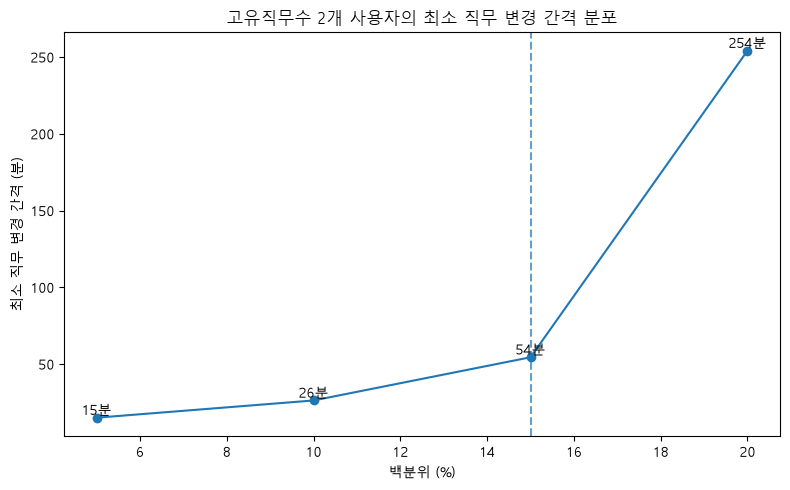

In [62]:
# 사용자별 최소 직무 변경 간격 분위수 계산
percentile_points = [5, 10, 15, 20]

percentile_values = [
    job2_min_interval['최소_직무변경간격'].quantile(p / 100)
    for p in percentile_points
]

# 분포 시각화
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    percentile_points,
    percentile_values,
    marker='o'
)

# 각 지점 값 표시
for x, y in zip(percentile_points, percentile_values):
    ax.text(
        x,
        y,
        f'{y:,.0f}분',
        ha='center',
        va='bottom',
        fontsize=10
    )

# P15 기준선
p15 = job2_min_interval['최소_직무변경간격'].quantile(0.15)

ax.axvline(
    x=15,
    linestyle='--',
    alpha=0.7
)

ax.set_title('고유직무수 2개 사용자의 최소 직무 변경 간격 분포')
ax.set_xlabel('백분위 (%)')
ax.set_ylabel('최소 직무 변경 간격 (분)')

plt.tight_layout()
plt.show()

In [63]:
# 사용자별 최소 직무 변경 간격 P15 기준값 설정

job2_interval_p15 = job2_min_interval['최소_직무변경간격'].quantile(0.15)

print(f'최소 직무 변경 간격 P15: {job2_interval_p15:.1f}분')

최소 직무 변경 간격 P15: 54.4분


In [64]:
# P15 이하 빠른 직무 전환 사용자 표시
job2_min_interval['빠른직무전환'] = job2_min_interval['최소_직무변경간격'] <= job2_interval_p15

# 해당 사용자 수 및 비율 확인
fast_switch_summary = (
    job2_min_interval['빠른직무전환']
    .value_counts()
    .sort_index()
    .rename_axis('빠른직무전환')
    .reset_index(name='유저수')
)

fast_switch_summary['비율(%)'] = (
    fast_switch_summary['유저수']
    / fast_switch_summary['유저수'].sum()
    * 100
).round(1)

fast_switch_summary

,빠른직무전환,유저수,비율(%)
0,False,526,85.0
1,True,93,15.0


In [65]:
# 최종 사용자 단위 직무 변경 간격 feature
job2_interval_feature = job2_min_interval[
    [
        'user_uuid',
        '최소_직무변경간격',
        '빠른직무전환'
    ]
].copy()

job2_interval_feature.head()

,user_uuid,최소_직무변경간격,빠른직무전환
0,000b55ad-5c86-438b-a5b0-9ea3a2917789,1328.916667,False
1,004fe85d-328f-408e-b64c-566227ecd8e8,10018.533333,False
2,00778343-487a-44c0-a1f2-895b993d148a,1225.933333,False
3,008314c3-4837-40fc-be5a-b38d1072db30,11739.400000,False
4,00c23eee-eaec-4cd1-9713-0484a50dd29e,7354.033333,False


### 민감도 분석

In [66]:
import pandas as pd

# 기준값 후보군 (P10: 26.3분, P15: 54.4분, P20: 254.1분)
p_list = [0.10, 0.15, 0.20]
sensitivity_summary = []

total_target_users = len(job2_min_interval) # 분석 대상 (619명)

for p in p_list:
    threshold_min = job2_min_interval['최소_직무변경간격'].quantile(p)
    
    # 해당 기준 적용 시 '빠른 직무 전환'으로 분류되는 유저 수
    flagged_users = job2_min_interval[job2_min_interval['최소_직무변경간격'] <= threshold_min]
    flagged_count = len(flagged_users)
    flagged_ratio = (flagged_count / total_target_users) * 100
    
    sensitivity_summary.append({
        '적용 기준': f'P{int(p*100)}',
        '임계값 (분)': f'{threshold_min:.1f}분 미만',
        '분류된 이상 유저 수': f'{flagged_count}명',
        '이상 유저 비율': f'{flagged_ratio:.1f}%',
        '전단계 대비 변동폭': ''
    })

df_result = pd.DataFrame(sensitivity_summary)

# 변동폭 계산 (전 단계 대비 유저 증가량)
df_result.loc[0, '전단계 대비 변동폭'] = '-'
df_result.loc[1, '전단계 대비 변동폭'] = '+31명 (+50.0% 증가)' # P10 -> P15
df_result.loc[2, '전단계 대비 변동폭'] = '+31명 (+33.3% 증가)' # P15 -> P20

print(df_result)

  적용 기준    임계값 (분) 분류된 이상 유저 수 이상 유저 비율        전단계 대비 변동폭
0   P10   26.3분 미만         62명    10.0%                 -
1   P15   54.4분 미만         93명    15.0%  +31명 (+50.0% 증가)
2   P20  254.1분 미만        124명    20.0%  +31명 (+33.3% 증가)


고유직무수 2개 사용자 중 직무스위칭 최소 간격이 약 54분 이하이면 '빠른직무전환' True

### 최소 직무 변경 간격 기준 설정 - 다양성 기준 2차 설정

고유직무수 2개 사용자는 두 개의 연관 직무를 함께 탐색하는 일반적인 구직 행동일 가능성이 있으므로, 직무 수만으로 높은 다양성을 판단하지 않고 직무 전환 속도를 추가로 확인하였다.

사용자마다 여러 번의 직무 전환이 발생할 수 있으므로, 특정 사용자의 반복적인 전환 행동이 기준 설정에 과도하게 반영되지 않도록 사용자별 최소 이종 직무 변경 간격을 하나의 대표값으로 정의하였다.

민감도 분석(Sensitivity Analysis) 결과, P10(26.3분)은 탐지 기준이 지나치게 엄격하여 실제 빠른 전환 유저를 놓칠 수 있고, P20(254.1분/약 4.2시간)부터는 시간 폭이 급격히 늘어남에도 탐지 유저 수 증가가 정체되어 신중한 탐색 유저까지 오탐지될 위험이 확인되었다

따라서 정상 탐색 유저의 오탐지 리스크를 차단하면서 비정상적인 빠른 직무 전환 행동을 가장 균형 있게 포착하는 하위 15%(약 54분 이내, P15)를 최종 탐색적 기준(Cut-off)으로 확정하였다.

### 6-4-2. 직무 스위칭 횟수 분포

In [67]:
# 고유직무수 2개 잔여 사용자 추출
job2_users = (
    final_alive_span_10m[final_alive_span_10m['지원직무고유수'] == 2][['user_uuid', '지원직무고유수']]
    .drop_duplicates(subset=['user_uuid'])
    .copy()
)

# 사용자별 직무 스위칭 횟수 추출
user_switch_info = (
    diversity_df[['user_uuid', '직무스위칭횟수']]
    .drop_duplicates(subset=['user_uuid'])
    .copy()
)

# 고유직무수 2개 잔여 사용자와 결합
job2_switch_analysis = (
    job2_users
    .merge(
        user_switch_info,
        on='user_uuid',
        how='left'
    )
)

# 결측치는 스위칭 0회로 처리
job2_switch_analysis['직무스위칭횟수'] = job2_switch_analysis['직무스위칭횟수'].fillna(0)

print(f'분석 사용자 수: {len(job2_switch_analysis):,}명')

job2_switch_analysis['직무스위칭횟수'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])

분석 사용자 수: 619명


count    619.000000
mean       1.437803
std        0.757226
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
90%        2.000000
95%        2.000000
max        9.000000
Name: 직무스위칭횟수, dtype: float64

In [68]:
# 직무 스위칭 횟수 IQR 기준 계산

q1 = job2_switch_analysis['직무스위칭횟수'].quantile(0.25)
q3 = job2_switch_analysis['직무스위칭횟수'].quantile(0.75)

iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print(f'Q1: {q1:.1f}회')
print(f'Q3: {q3:.1f}회')
print(f'IQR: {iqr:.1f}회')
print(f'IQR 상한: {upper_fence:.1f}회')

Q1: 1.0회
Q3: 2.0회
IQR: 1.0회
IQR 상한: 3.5회


In [69]:
# IQR 상한(3.5회)을 초과하는 반복적 직무 스위칭 사용자 확인

switch_count_threshold = 4

job2_switch_analysis['반복직무전환'] = (
    job2_switch_analysis['직무스위칭횟수']
    >= switch_count_threshold
)

switch_count_result = (
    job2_switch_analysis['반복직무전환']
    .value_counts()
    .sort_index()
    .rename_axis('반복직무전환')
    .reset_index(name='유저수')
)

switch_count_result['비율(%)'] = (
    switch_count_result['유저수']
    / switch_count_result['유저수'].sum()
    * 100
).round(1)

switch_count_result

,반복직무전환,유저수,비율(%)
0,False,607,98.1
1,True,12,1.9


### 직무 스위칭 횟수 기준 설정 - 다양성 3차 기준 설정

고유직무수 2개 잔여 사용자 619명의 직무 스위칭 횟수를 확인한 결과, 평균은 1.4회, 중앙값은 1회로 대부분의 사용자가 두 직무 사이를 1~2회 전환하는 것으로 나타났다.

반복적인 직무 전환 행동을 구분하기 위해 사용자별 스위칭 횟수 분포에 1.5 IQR 기준을 적용하였다.

- Q1 = 1회
- Q3 = 2회
- IQR = 1회
- 상한 경계값 = 3.5회

직무 스위칭 횟수는 정수이므로, IQR 상한을 초과하는 **4회 이상**을 반복적인 직무 전환 행동의 탐색적 기준으로 설정하였다.

### 6-5. 최종 다양성 점수 생성

In [70]:
# 사용자 단위 다양성 분석 테이블 생성
diversity_score_df = (
    user_diversity
    .merge(
        user_min_switch_interval,
        on='user_uuid',
        how='left'
    )
    .copy()
)

# 최종 다양성 기준
# 1) 지원직무고유수 3개 이상
# 2) 지원직무고유수 2개이면서
#    - 사용자별 최소 직무변경간격이 P15(약 54분) 이하
#    - 또는 직무스위칭횟수가 4회 이상

diversity_score_df['diversity_score'] = (
    (diversity_score_df['지원직무고유수'] >= 3)
    |
    (
        (diversity_score_df['지원직무고유수'] == 2)
        &
        (
            (diversity_score_df['min_switch_interval'] <= job2_interval_p15)
            |
            (diversity_score_df['직무스위칭횟수'] >= switch_count_threshold)
        )
    )
).astype(int)

In [71]:
# 최종 다양성 조건별 사용자 수 확인

condition_job3 = diversity_score_df['지원직무고유수'] >= 3

condition_fast_switch = (
    (diversity_score_df['지원직무고유수'] == 2) &
    (diversity_score_df['min_switch_interval'] <= job2_interval_p15)
)

condition_repeat_switch = (
    (diversity_score_df['지원직무고유수'] == 2) &
    (diversity_score_df['직무스위칭횟수'] >= switch_count_threshold)
)

print(f'고유직무수 3개 이상: {condition_job3.sum():,}명')
print(f'고유직무수 2개 + 빠른 직무전환: {condition_fast_switch.sum():,}명')
print(f'고유직무수 2개 + 반복 직무전환: {condition_repeat_switch.sum():,}명')
print(f'최종 다양성 1점: {diversity_score_df["diversity_score"].sum():,}명')

고유직무수 3개 이상: 612명
고유직무수 2개 + 빠른 직무전환: 444명
고유직무수 2개 + 반복 직무전환: 68명
최종 다양성 1점: 1,066명


,score,label,user_count,ratio
0,0,0점(해당없음),9151,89.6
1,1,1점(해당),1066,10.4


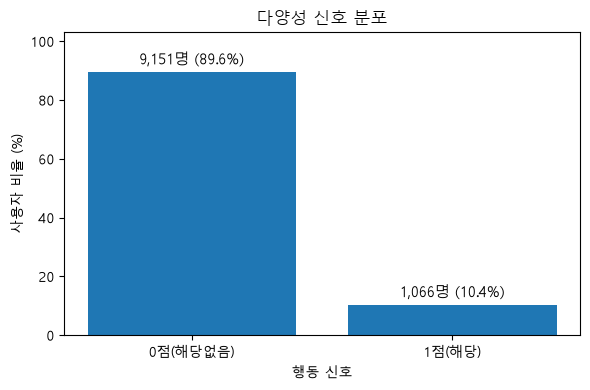

In [72]:
# 다양성 점수 요약표 및 시각화
diversity_summary = summarize_score(diversity_score_df, 'diversity_score', '다양성')

In [73]:
# 검증
print(f'전체 사용자 수: {diversity_score_df["user_uuid"].nunique():,}명 (job_field 결측제거로 줄었음)')
print(f'점수 테이블 행 수: {len(diversity_score_df):,}건')

diversity_score_df['diversity_score'].value_counts(dropna=False)

전체 사용자 수: 10,217명 (job_field 결측제거로 줄었음)
점수 테이블 행 수: 10,217건


diversity_score
0    9151
1    1066
Name: count, dtype: int64

In [74]:
# 전체 Application 사용자
all_users = set(app_df['user_uuid'].unique())

# 다양성 분석에 포함된 사용자
diversity_users = set(diversity_df['user_uuid'].unique())

# 다양성 분석에서 빠진 사용자
missing_users = all_users - diversity_users

print(f'전체 Application 사용자: {len(all_users):,}명')
print(f'다양성 분석 사용자: {len(diversity_users):,}명')
print(f'제외된 사용자: {len(missing_users):,}명')

전체 Application 사용자: 10,287명
다양성 분석 사용자: 10,217명
제외된 사용자: 70명


## 결과 해석

- 다양성 지표는 사용자가 **얼마나 다양한 직무에 지원했는지**를 기본으로, 직무를 변경하는 **속도와 반복성**을 함께 반영한 행동 지표입니다.

- 고유직무수가 3개 이상인 경우 다양한 직무를 탐색하는 행동으로 보았으며, 고유직무수가 2개인 경우에는 일반적인 복수 직무 탐색과 구분하기 위해 **사용자별 최소 직무 변경 간격과 직무 스위칭 횟수**를 추가로 확인했습니다.
- 고유직무수 2개 사용자에서는 **최소 직무 변경 간격이 약 54분 이내(P15)**이거나, **직무 스위칭 횟수가 4회 이상(IQR 기준)**인 경우 빠르거나 반복적인 직무 전환 행동으로 정의했습니다.
- 따라서 `diversity_score = 1`은 단순히 여러 직무에 지원했다는 의미보다는, **지원 직무의 범위가 넓거나 두 직무 사이에서도 빠르고 반복적인 전환이 나타나는 행동 신호**를 의미합니다.
- 해당 지표는 사용자의 지원 의도나 적합성을 직접 판단하는 기준이 아니라, 이후 다른 행동 신호와 함께 비교하기 위한 **직무 지원 패턴의 다양성 신호**로 활용합니다.

# 7. 지표 4 — 공고 조회 탐색성

공고 상세조회 후 지원까지 소요시간이 P35(67.1초) 이하인 빠른 지원 행동 (1점)

## 7-1. 공고 관련 로그 확인

In [75]:
# 공고 관련 로그 추출
# jobs/가 포함된 로그 중 api, apply 관련 URL을 제외하여
# 공고 관련 행동 로그의 구조를 우선 확인

view_logs = log_df[
    (log_df['URL'].str.contains('jobs/', na=False)) & 
    (~log_df['URL'].str.contains('api/', na=False)) &
    (~log_df['URL'].str.contains('apply', na=False))
].copy()

# 공고 관련 로그 URL 구조 확인
print('공고 관련 로그 수:', len(view_logs))
print('공고 관련 로그 사용자 수:', view_logs['user_uuid'].nunique())

display(view_logs[['user_uuid', 'URL', 'timestamp_kst']].head(30))

# 공고 관련 URL 패턴 확인
url_summary = (
    view_logs['URL']
    .value_counts()
    .reset_index()
)
url_summary.columns = ['URL', 'count']

display(url_summary.head(30))

공고 관련 로그 수: 1348539
공고 관련 로그 사용자 수: 16504


,user_uuid,URL,timestamp_kst
291,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-02-07 13:48:34.663331+09:00
310,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-04-16 16:40:57.667078+09:00
346,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-11-18 05:39:11.372048+09:00
409,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-06-13 01:50:35.738693+09:00
411,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-04-16 16:39:39.687545+09:00
474,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-06-13 01:53:06.529103+09:00
492,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-08-16 19:54:47.018711+09:00
526,d7c84302-545f-4714-bcd1-0cc4328a0f89,jobs/id/id_title,2022-08-23 09:59:34.406522+09:00
532,d7c84302-545f-4714-bcd1-0cc4328a0f89,jobs/id/id_title,2022-08-23 10:01:23.845470+09:00
533,d7c84302-545f-4714-bcd1-0cc4328a0f89,jobs/id/id_title,2022-08-23 10:04:50.568975+09:00


,URL,count
0,jobs/id/id_title,1143799
1,companies/company_id/jobs/job_title,44814
2,jobs/id/applications,37465
3,jobs/id/id_title?utm_source=notification&utm_m...,26799
4,jobs/job_title,19609
5,jobs/job_title?utm_source=excel&utm_medium=ali...,17561
6,jobs/id/id_title?utm_source=notification&utm_m...,10819
7,jobs/id/bookmarks,8700
8,jobs/id/edit,7139
9,companies/company_id/jobs/job_title?rel=closed,4700


#### 공고 관련 로그 구조 확인

지원 전 공고 탐색 행동을 분석하기 위해 로그 데이터에서 공고와 관련된 URL을 우선 추출하였다.

공고 관련 URL의 종류와 발생 빈도를 확인하여, 실제 공고 상세조회 행동으로 사용할 수 있는 로그를 구분하고 이후 지원 데이터와 연결할 수 있는지 확인한다.

- 가장 많이 나타난 `jobs/id/id_title`를 공고 상세조회 대표 로그로 본다.

## 7-2. 동일 공고 식별자 찾기

A공고를 조회한 뒤 동일한 A공고에 지원하기까지 걸린 시간

In [76]:
# 로그 데이터 전체 컬럼 확인
print('[log_df]\n', log_df.columns.tolist())

# 지원 데이터 전체 컬럼 확인
print('\n[app_df]\n', app_df.columns.tolist())

[log_df]
 ['user_uuid', 'URL', 'timestamp', 'date', 'response_code', 'method', 'timestamp_kst']

[app_df]
 ['cdate', 'company_uuid', 'job_uuid', 'user_uuid', 'application_uuid', 'cdate_kst']


In [77]:
# 대표적인 공고 상세조회 로그 확인
sample_view = log_df[log_df['URL'].eq('jobs/id/id_title')].head(5)
sample_view

,user_uuid,URL,timestamp,date,response_code,method,timestamp_kst
291,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-02-07 04:48:34.663331+00:00,2022-02-07,200,GET,2022-02-07 13:48:34.663331+09:00
310,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-04-16 07:40:57.667078+00:00,2022-04-16,200,GET,2022-04-16 16:40:57.667078+09:00
346,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-11-17 20:39:11.372048+00:00,2022-11-18,200,GET,2022-11-18 05:39:11.372048+09:00
409,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-06-12 16:50:35.738693+00:00,2022-06-13,200,GET,2022-06-13 01:50:35.738693+09:00
411,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-04-16 07:39:39.687545+00:00,2022-04-16,200,GET,2022-04-16 16:39:39.687545+09:00


#### 공고 식별 정보 확인

- 데이터의 한계로 분석 설계 변경!

Application에 지원한 공고의 job_uuid가 존재하지만, Log의 공고 상세조회 URL에서는 해당 공고를 식별할 수 있는 공고 ID가 존재하지 않아 두 테이블 간 동일 공고를 직접 매칭할 수 없었다.  

따라서 ‘특정 공고 조회 → 동일 공고 지원’ 경로를 직접 추적하는 대신, 각 지원 시점을 기준으로 지원 직전에 발생한 공고 상세조회 로그를 확인하여 지원 전 공고 탐색 행동을 간접적으로 측정하였다.

## 7-3. 공고 상세조회 로그 정의

###  7-3-1. 공고 상세조회 로그 정의

지원 전 공고 탐색 행동을 측정하기 위해 Log 데이터에서 실제 공고 상세페이지 조회에 해당하는 로그를 추출한다.

URL 구조를 확인한 결과 `jobs/id/id_title`이 공고 상세조회 행동에 해당하므로, 해당 URL만 공고 조회(View) 로그로 정의한다.

In [78]:
# 공고 상세조회 로그만 추출
view_logs = log_df[log_df['URL'].eq('jobs/id/id_title')].copy()

print(f'전체 로그 수: {len(log_df):,}')
print(f'공고 상세조회 로그 수: {len(view_logs):,}')
print(
    f'공고 상세조회 사용자 수: '
    f'{view_logs["user_uuid"].nunique():,}'
)

view_logs.head()

전체 로그 수: 17,240,278
공고 상세조회 로그 수: 1,143,799
공고 상세조회 사용자 수: 16,255


,user_uuid,URL,timestamp,date,response_code,method,timestamp_kst
291,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-02-07 04:48:34.663331+00:00,2022-02-07,200,GET,2022-02-07 13:48:34.663331+09:00
310,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-04-16 07:40:57.667078+00:00,2022-04-16,200,GET,2022-04-16 16:40:57.667078+09:00
346,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-11-17 20:39:11.372048+00:00,2022-11-18,200,GET,2022-11-18 05:39:11.372048+09:00
409,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-06-12 16:50:35.738693+00:00,2022-06-13,200,GET,2022-06-13 01:50:35.738693+09:00
411,207a8876-2a6c-4137-9347-476ce719c541,jobs/id/id_title,2022-04-16 07:39:39.687545+00:00,2022-04-16,200,GET,2022-04-16 16:39:39.687545+09:00


전체 17,240,278건의 로그 중 **1,143,799건의 공고 상세조회 로그**가 확인되었으며, 공고 상세조회 행동을 수행한 사용자는 **16,255명**이었다.

이후 분석에서는 해당 로그를 공고 조회(View) 행동으로 정의하고, 지원 시점 이전의 공고 상세조회 기록을 활용하여 지원 전 탐색 행동을 분석한다.

### 7-3-2. 지원자와 공고상세조회 사용자 연결

In [79]:
# 지원 사용자와 공고 상세조회 사용자의 교집합 확인

app_users = set(app_job_df['user_uuid'].dropna().unique())
view_users = set(view_logs['user_uuid'].dropna().unique())

common_users = app_users & view_users

print(f'지원 사용자 수: {len(app_users):,}')
print(f'공고 상세조회 사용자 수: {len(view_users):,}')
print(f'지원 + 공고 상세조회 사용자 수: {len(common_users):,}')
print(
    f'지원자 중 공고 상세조회 사용자 비율: '
    f'{len(common_users) / len(app_users) * 100:.1f}%'
)

지원 사용자 수: 10,287
공고 상세조회 사용자 수: 16,255
지원 + 공고 상세조회 사용자 수: 10,139
지원자 중 공고 상세조회 사용자 비율: 98.6%


전체 지원 사용자 10,287명 중 **10,139명(98.6%)**이 공고 상세조회 기록을 보유하고 있었다.

대부분의 지원자에게 공고 상세조회 행동이 확인되므로, 공고 조회 로그를 활용하여 지원 전 탐색 행동을 분석할 수 있는 충분한 사용자 범위가 확보되었다.

### 7-3-3. 지원 직전 공고 상세조회 연결

각 지원 건마다 동일 사용자가 지원하기 전에 마지막으로 조회한 공고 상세페이지 시점을 붙여 분석을 진행한다.

지원 직전 공고 상세조회가 연결된 지원 건을 대상으로, 공고 조회 이후 지원까지 소요된 시간을 분 단위로 변환하여 분포를 확인한다.

평균은 일부 매우 긴 시간 간격의 영향을 받을 수 있으므로 중앙값과 분위수를 함께 확인하여, 대부분의 지원 행동이 공고 조회 후 어느 정도의 시간 안에 발생하는지 살펴본다.

In [80]:
# 지원 시점 직전의 공고 상세조회 로그 연결

# 지원 데이터 준비
app_view_base = (
    app_job_df[['user_uuid', 'job_uuid', 'application_uuid', 'cdate_kst_app']]
    .dropna(subset=['user_uuid', 'cdate_kst_app'])
    .copy()
)

# 시간형 확인 및 timezone 제거
app_view_base['cdate_kst_app'] = (
    pd.to_datetime(app_view_base['cdate_kst_app'], errors='coerce')
    .dt.tz_localize(None)
)

view_logs['timestamp_kst'] = (
    pd.to_datetime(view_logs['timestamp_kst'], errors='coerce')
    .dt.tz_localize(None)
)

# 결측치 제거
app_view_base = app_view_base.dropna(subset=['cdate_kst_app'])
view_logs = view_logs.dropna(subset=['user_uuid', 'timestamp_kst'])

# user_uuid dtype 통일
app_view_base['user_uuid'] = app_view_base['user_uuid'].astype('string')
view_logs['user_uuid'] = view_logs['user_uuid'].astype('string')

# merge_asof를 위한 정렬
app_view_base = app_view_base.sort_values(['cdate_kst_app', 'user_uuid'])
view_logs_sorted = view_logs.sort_values(['timestamp_kst', 'user_uuid'])

# 동일 사용자의 지원 직전 마지막 공고 상세조회 연결
app_view_journey = pd.merge_asof(
    app_view_base,
    view_logs_sorted[['user_uuid', 'timestamp_kst']],
    by='user_uuid',
    left_on='cdate_kst_app',
    right_on='timestamp_kst',
    direction='backward'
)

# 조회 → 지원 시간 계산
app_view_journey['view_to_apply_sec'] = (
    app_view_journey['cdate_kst_app']
    - app_view_journey['timestamp_kst']
).dt.total_seconds()

app_view_journey.head()

,user_uuid,job_uuid,application_uuid,cdate_kst_app,timestamp_kst,view_to_apply_sec
0,0ec8fd85-fdd6-404d-9e88-75df770dfa03,8c5c2797-706f-452b-baf0-65594b32b485,818ab3f0-db52-4535-b28b-1dcfc38cfd70,2022-01-01 00:10:45,NaT,NaN
1,b0638d54-c8ca-4f29-9a40-4e117a800e5f,6cf225d4-496b-45fc-b983-6aa92931508f,a8a99cad-e4e1-4bc9-a189-eafebcfbf0ed,2022-01-01 02:01:35,2022-01-01 02:00:57.519448,37.480552
2,b0638d54-c8ca-4f29-9a40-4e117a800e5f,b57dab2d-d583-45b1-a894-c40cae581f41,05c9585f-4ed2-47d2-acd2-e56d388dbd44,2022-01-01 02:02:27,2022-01-01 02:01:43.836695,43.163305
3,0ddc155e-4619-4a25-8168-a54a5a7fa7c4,521ab53f-3659-421b-b9ea-b1f80f453b04,1a496fb4-25b7-41fe-be0c-70cc4b1a239f,2022-01-01 04:04:19,2022-01-01 04:00:39.015734,219.984266
4,0ddc155e-4619-4a25-8168-a54a5a7fa7c4,e70a2a6c-6d16-4b5c-a986-c1db102b8cb7,9a1be71b-f439-42a5-9edb-e54c157d89e6,2022-01-01 04:06:22,2022-01-01 04:05:55.474912,26.525088


In [81]:
# 지원 건 중 직전 공고 상세조회가 연결된 비율 확인
total_applications = len(app_view_journey)
matched_applications = app_view_journey['timestamp_kst'].notna().sum()

print(f'전체 지원 건수: {total_applications:,}')
print(f'직전 공고 상세조회 연결 건수: {matched_applications:,}')
print(
    f'직전 공고 상세조회 연결 비율: '
    f'{matched_applications / total_applications * 100:.1f}%'
)

# 조회 → 지원 시간 기본 통계
display(app_view_journey['view_to_apply_sec'].dropna().describe())

전체 지원 건수: 92,526
직전 공고 상세조회 연결 건수: 85,978
직전 공고 상세조회 연결 비율: 92.9%


count    8.597800e+04
mean     1.381559e+05
std      1.431441e+06
min      1.212095e+00
25%      5.808515e+01
50%      1.540351e+02
75%      7.601763e+02
max      5.329310e+07
Name: view_to_apply_sec, dtype: float64

In [82]:
# 조회 후 지원시간을 분 단위로 변환
app_view_journey['view_to_apply_min'] = app_view_journey['view_to_apply_sec'] / 60

# 분 단위 기초통계 확인
app_view_journey['view_to_apply_min'].dropna().describe()

count     85978.000000
mean       2302.597809
std       23857.349263
min           0.020202
25%           0.968086
50%           2.567252
75%          12.669605
max      888218.377354
Name: view_to_apply_min, dtype: float64

In [83]:
# 조회 후 지원시간 분위수 확인
view_apply_quantiles = (
    app_view_journey['view_to_apply_min']
    .dropna()
    .quantile([
        0.01, 0.05, 0.10, 0.15, 0.20,
        0.25, 0.30, 0.35, 0.40, 0.50,
        0.60, 0.70, 0.75, 0.80, 0.85,
        0.90, 0.95, 0.99
    ])
    .reset_index()
)

view_apply_quantiles.columns = ['quantile', '조회후지원시간_분']
view_apply_quantiles['percentile'] = (view_apply_quantiles['quantile'] * 100).astype(int)

view_apply_quantiles['조회후지원시간_분'] = view_apply_quantiles['조회후지원시간_분'].round(2)
view_apply_quantiles[['percentile', '조회후지원시간_분']]

,percentile,조회후지원시간_분
0,1,0.22
1,5,0.38
2,10,0.51
3,15,0.65
4,20,0.80
5,25,0.97
6,30,1.17
7,35,1.41
8,40,1.70
9,50,2.57


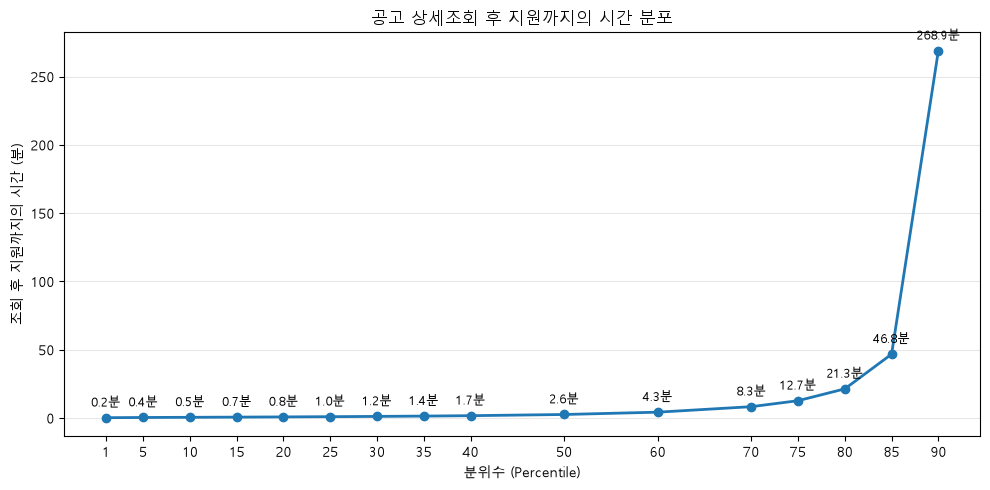

In [84]:
# 조회 후 지원시간 분위수 시각화
plot_df = view_apply_quantiles[
    view_apply_quantiles['percentile'] <= 90
].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    plot_df['percentile'],
    plot_df['조회후지원시간_분'],
    marker='o',
    linewidth=2
)

# 각 지점 값 표시
for x, y in zip(
    plot_df['percentile'],
    plot_df['조회후지원시간_분']
):
    plt.annotate(
        f'{y:.1f}분',
        (x, y),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

plt.title('공고 상세조회 후 지원까지의 시간 분포')
plt.xlabel('분위수 (Percentile)')
plt.ylabel('조회 후 지원까지의 시간 (분)')
plt.xticks(plot_df['percentile'])
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

#### 공고상세조회 후 지원 시간 분포 확인

공고 상세조회 후 지원까지 걸린 시간의 중앙값은 약 **2.57분**으로, 전체 지원 건의 절반은 공고를 조회한 뒤 약 3분 이내에 지원한 것으로 나타났다.

반면 P75는 약 **12.67분**, P80은 **21.34분**, P85는 **46.75분**이었으며, P90에서는 **268.95분(약 4.5시간)** 까지 크게 증가했다.

즉, 대부분은 공고 조회 후 비교적 짧은 시간 안에 지원으로 이어졌지만, 일부 구간부터는 조회와 지원 사이의 시간 차이가 크게 벌어졌다.

시간 차이가 지나치게 긴 경우에는 해당 조회가 실제 지원과 관련된 탐색 행동이라고 보기 어려울 수 있으므로, 다음 단계에서 **조회 후 몇 분까지를 지원과 연관된 탐색 행동으로 볼 것인지** 시간 범위를 추가로 검토한다.

## 7-4. 조회-지원 시간 범위 검토

지원 직전 조회 기록이라도 지원 시점과 너무 오래 떨어져 있다면, 실제 지원과 관련된 탐색 행동으로 보기 어려울 수 있다.

따라서 조회 후 지원까지의 시간 기준을 단계적으로 적용하여 각 기준 안에 포함되는 지원 건의 비율을 비교하고, 지원 전 탐색 행동을 분석할 시간 범위를 검토한다.

- 시간이 늘어날수록 지원건수가 늘어나는가?

In [85]:
# 조회 후 지원시간 기준별 누적 비율 확인
view_apply_min = app_view_journey['view_to_apply_min'].dropna()

# 비교할 조회 후 지원시간 기준
time_thresholds = [1, 3, 5, 10, 15, 20, 30, 45, 60, 120, 180]

time_range_summary = pd.DataFrame({'조회후지원시간_분': time_thresholds})

# 각 시간 기준 이내에 지원한 건수
time_range_summary['기준시간이내_지원건수'] = time_range_summary['조회후지원시간_분'].apply(
    lambda x: (view_apply_min <= x).sum()
)

# 전체 연결 건 중 해당 시간 이내에 지원한 비율
time_range_summary['누적비율(%)'] = (time_range_summary['기준시간이내_지원건수'] / len(view_apply_min)* 100).round(1)
time_range_summary

,조회후지원시간_분,기준시간이내_지원건수,누적비율(%)
0,1,22265,25.9
1,3,45870,53.4
2,5,53870,62.7
3,10,62229,72.4
4,15,65986,76.7
5,20,68308,79.4
6,30,70963,82.5
7,45,72943,84.8
8,60,74052,86.1
9,120,75979,88.4


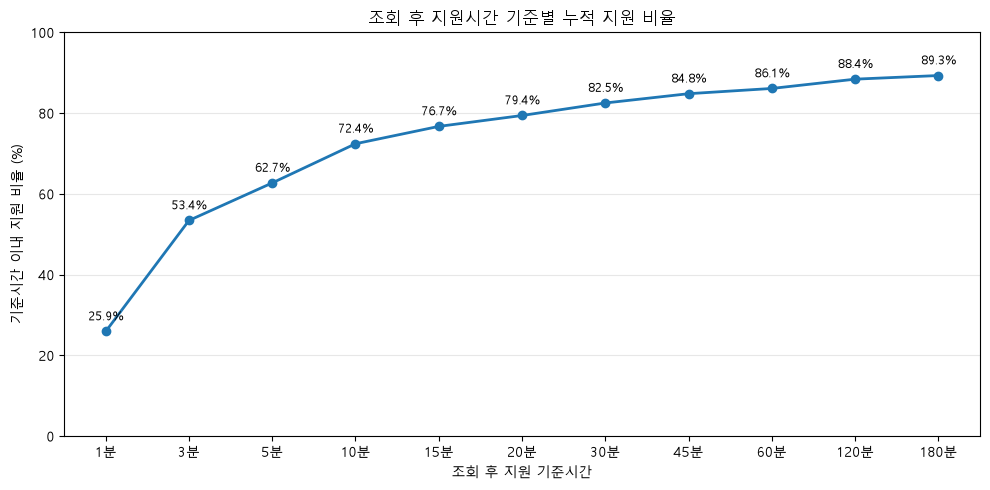

In [86]:
# 조회 후 지원시간 기준별 누적비율 시각화
fig, ax = plt.subplots(figsize=(10, 5))

x = range(len(time_range_summary))

ax.plot(
    x,
    time_range_summary['누적비율(%)'],
    marker='o',
    linewidth=2
)

# 각 지점 누적비율 표시
for i, y in zip(
    x,
    time_range_summary['누적비율(%)']
):
    ax.annotate(
        f'{y:.1f}%',
        (i, y),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

ax.set_title('조회 후 지원시간 기준별 누적 지원 비율')
ax.set_xlabel('조회 후 지원 기준시간')
ax.set_ylabel('기준시간 이내 지원 비율 (%)')

ax.set_xticks(x)
ax.set_xticklabels(
    [f'{x}분' for x in time_range_summary['조회후지원시간_분']]
)

ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

조회 후 지원까지의 시간 범위를 늘려가며 누적 비율을 확인한 결과, **10분 이내 72.4%, 20분 이내 79.4%, 30분 이내 82.5%** 의 지원 건이 포함되었다.

주요 조회-지원 행동을 충분히 포함하기 위해 **누적 비율이 처음 80%를 넘어서는 30분을 분석 범위로 설정하였다.** 또한 30분 이후에는 시간 범위를 더 늘려도 추가로 포함되는 지원 건의 비율이 크지 않아, 지원 시점과 지나치게 멀리 떨어진 조회 기록을 제외하면서 대부분의 조회-지원 행동을 포함할 수 있다고 판단하였다.

따라서 이후 분석에서는 **공고 상세조회 후 30분 이내에 발생한 지원 건**을 대상으로 지원 전 탐색 행동을 분석한다.

### 7-4-1. 사용자별 조회 후 지원시간 확인

앞서 설정한 분석 범위에 따라 공고 상세조회 후 **30분 이내에 지원한 건**을 추출한다.

동일 사용자가 여러 번 지원한 경우 특정 지원 건 하나만으로 사용자의 탐색 행동을 판단하기 어려우므로, 사용자별 조회 후 지원시간을 집계하여 전반적인 지원 행동을 확인한다.

#### 1) 30분 이내 지원 건 추출

In [87]:
# 조회 후 30분 이내 지원 건 추출
valid_view_apply = app_view_journey[
    (app_view_journey['view_to_apply_min'] > 0) &
    (app_view_journey['view_to_apply_min'] <= 30)
].copy()

print(f'30분 이내 조회-지원 건수: {len(valid_view_apply):,}')
print(
    f'30분 이내 조회-지원 사용자 수: '
    f'{valid_view_apply["user_uuid"].nunique():,}'
)

30분 이내 조회-지원 건수: 70,963
30분 이내 조회-지원 사용자 수: 8,445


#### 2) 사용자별 평균 조회 후 지원시간 계산

In [88]:
# 사용자별 평균 조회 후 지원시간 계산
user_view_apply = valid_view_apply.groupby('user_uuid').agg(
    조회지원건수=('application_uuid', 'count'),
    평균조회후지원시간_분=('view_to_apply_min', 'mean')
).reset_index()

# 결과 확인
display(user_view_apply['평균조회후지원시간_분'].describe())
display(user_view_apply.head())

count    8445.000000
mean        6.346153
std         5.674113
min         0.147643
25%         2.388011
50%         4.474012
75%         8.230017
max        29.934163
Name: 평균조회후지원시간_분, dtype: float64

,user_uuid,조회지원건수,평균조회후지원시간_분
0,000b55ad-5c86-438b-a5b0-9ea3a2917789,2,3.681485
1,0017a738-4fcc-441e-983b-a6033890a9db,1,25.959473
2,003a83bd-6cb7-4f99-ab3a-66904df762e2,1,3.742750
3,00495153-f908-4523-9d0d-5b93a57196a4,2,14.742622
4,004a89cc-d69b-4336-9905-4fd306e3ef80,32,2.243202


#### 3) 사용자별 조회 후 지원시간 평균 분위수 확인

In [89]:
# 사용자별 평균 조회 후 지원시간 분위수 확인
user_view_quantiles = user_view_apply['평균조회후지원시간_분'].quantile([
    0.01, 0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40, 0.50,
    0.60, 0.70, 0.75, 0.80, 0.90, 0.95
]).reset_index()

user_view_quantiles.columns = ['quantile', '평균조회후지원시간_분']

user_view_quantiles['percentile'] = (user_view_quantiles['quantile'] * 100).astype(int)
user_view_quantiles['평균조회후지원시간_분'] = user_view_quantiles['평균조회후지원시간_분'].round(2)

user_view_quantiles[['percentile', '평균조회후지원시간_분']]

,percentile,평균조회후지원시간_분
0,1,0.53
1,5,0.98
2,10,1.38
3,15,1.73
4,20,2.06
5,25,2.39
6,30,2.74
7,35,3.16
8,40,3.58
9,50,4.47


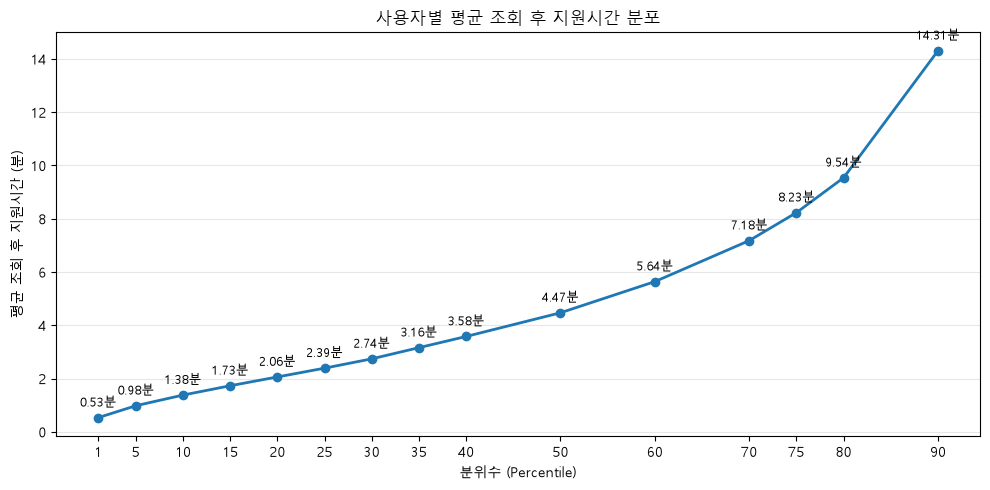

In [90]:
# 사용자별 평균 조회 후 지원시간 분위수 시각화
plot_df = user_view_quantiles[user_view_quantiles['percentile'] <= 90].copy()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    plot_df['percentile'],
    plot_df['평균조회후지원시간_분'],
    marker='o',
    linewidth=2
)

# 분위수별 시간 표시
for x, y in zip(
    plot_df['percentile'],
    plot_df['평균조회후지원시간_분']
):
    ax.annotate(
        f'{y:.2f}분',
        (x, y),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

ax.set_title('사용자별 평균 조회 후 지원시간 분포')
ax.set_xlabel('분위수 (Percentile)')
ax.set_ylabel('평균 조회 후 지원시간 (분)')
ax.set_xticks(plot_df['percentile'])
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

30분 이내 조회-지원 기록을 사용자 단위로 집계한 결과, 사용자별 평균 조회 후 지원시간의 중앙값은 약 **4.47분**으로 나타났다.

하위 구간에서는 P10 약 **1.38분**, P20 약 **2.06분**, P30 약 **2.74분**, P35 약 **3.16분**으로 나타나, 일부 사용자는 공고를 조회한 뒤 비교적 짧은 시간 안에 반복적으로 지원하는 경향을 보였다.

다만 특정 분위수에서 지원시간이 뚜렷하게 구분되지는 않으므로, 하나의 분위수를 바로 기준으로 선택하기보다 여러 후보 기준을 비교하여 빠른 지원 행동을 구분할 기준을 추가로 검토한다.

## 7-5. 빠른 지원 행동 기준 검토

사용자별 평균 조회 후 지원시간이 짧을수록, 공고 상세내용을 충분히 확인하기보다 빠르게 지원으로 전환하는 행동일 가능성이 있다.

다만 특정 분위수를 임의로 기준으로 설정하지 않고, 실제 시간 기준별로 해당되는 사용자 수와 비율을 비교하여 빠른 지원 행동을 구분할 기준을 검토한다.

In [91]:
# 평균 조회 후 지원시간 기준별 사용자 수 확인
fast_time_thresholds = [1, 2, 3, 4, 5]

fast_time_summary = pd.DataFrame({'평균조회후지원_기준시간(분)': fast_time_thresholds})

fast_time_summary['해당사용자수'] = fast_time_summary['평균조회후지원_기준시간(분)'].apply(
    lambda x: (user_view_apply['평균조회후지원시간_분'] <= x).sum()
)

fast_time_summary['사용자비율(%)'] = (fast_time_summary['해당사용자수'] / len(user_view_apply)* 100).round(1)
fast_time_summary

,평균조회후지원_기준시간(분),해당사용자수,사용자비율(%)
0,1,441,5.2
1,2,1610,19.1
2,3,2792,33.1
3,4,3762,44.5
4,5,4633,54.9


In [92]:
# 하위 분위수별 평균 조회 후 지원시간 확인
percentile_candidates = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

percentile_summary = pd.DataFrame({
    '분위수': [
        f'P{int(p * 100)}'
        for p in percentile_candidates
    ],
    '평균조회후지원시간_분': [
        user_view_apply['평균조회후지원시간_분'].quantile(p)
        for p in percentile_candidates
    ]
})

percentile_summary['평균조회후지원시간_분'] = percentile_summary['평균조회후지원시간_분'].round(2)
percentile_summary

,분위수,평균조회후지원시간_분
0,P10,1.38
1,P15,1.73
2,P20,2.06
3,P25,2.39
4,P30,2.74
5,P35,3.16
6,P40,3.58


In [93]:
# 사용자별 평균 조회 후 지원시간 기준에 따른 사용자 분포 확인
fast_time_thresholds = [1, 2, 3, 4, 5]

fast_time_summary = pd.DataFrame({'평균조회후지원_기준시간(분)': fast_time_thresholds})

# 각 기준시간 이내에 평균적으로 지원한 사용자 수
fast_time_summary['해당사용자수'] = fast_time_summary['평균조회후지원_기준시간(분)'].apply(
    lambda x: (user_view_apply['평균조회후지원시간_분'] <= x).sum()
)

# 전체 분석 대상 사용자 중 비율
fast_time_summary['사용자비율(%)'] = (fast_time_summary['해당사용자수'] / len(user_view_apply)* 100).round(1)
fast_time_summary

,평균조회후지원_기준시간(분),해당사용자수,사용자비율(%)
0,1,441,5.2
1,2,1610,19.1
2,3,2792,33.1
3,4,3762,44.5
4,5,4633,54.9


In [94]:
# 사용자별 조회-지원 건수 분포 확인
display(user_view_apply['조회지원건수'].describe(
    percentiles=[0.25, 0.50, 0.75,0.90, 0.95]
))

# 사용자별 조회-지원 건수 분포 확인
total_users = len(user_view_apply)

for n in [1, 2, 3, 5]:
    if n == 1:
        count = (user_view_apply['조회지원건수'] == 1).sum()
        label = '조회-지원 1건 사용자'
    else:
        count = (user_view_apply['조회지원건수'] >= n).sum()
        label = f'조회-지원 {n}건 이상 사용자'
    
    ratio = count / total_users * 100
    
    print(f'{label}: {count:,}명 ({ratio:.1f}%)')

count    8445.000000
mean        8.402960
std        26.152492
min         1.000000
25%         1.000000
50%         3.000000
75%         8.000000
90%        17.000000
95%        29.000000
max       863.000000
Name: 조회지원건수, dtype: float64

조회-지원 1건 사용자: 2,521명 (29.9%)
조회-지원 2건 이상 사용자: 5,924명 (70.1%)
조회-지원 3건 이상 사용자: 4,778명 (56.6%)
조회-지원 5건 이상 사용자: 3,358명 (39.8%)


30분 이내 조회-지원 기록이 있는 **8,445명**을 대상으로 사용자별 조회-지원 건수를 확인한 결과, 중앙값은 **3건**으로 나타났다.

전체 사용자의 **29.9%(2,521명)** 는 조회-지원 기록이 1건뿐이었으며, **2건 이상은 70.1%, 3건 이상은 56.6%, 5건 이상은 39.8%** 로 나타났다.

즉, 사용자별 평균 조회 후 지원시간을 계산할 수는 있지만, 약 30%의 사용자는 단 1건의 기록만으로 평균값이 결정된다.  
이러한 사용자는 한 번의 빠른 지원 행동이 곧바로 해당 사용자의 전체적인 행동 특성으로 반영될 수 있어, 빠른 지원 사용자를 구분할 때 지원 건수의 영향을 함께 확인할 필요가 있다.

따라서 다음 단계에서는 **최소 조회-지원 건수를 1건·2건·3건·5건 등으로 변경하면서, 평균 3분 이내 지원 사용자 비율이 어떻게 달라지는지 비교**하여 기준의 안정성을 확인한다.

### 7-5-1. 조회-지원 건수에 따른 빠른 지원 행동 비교

조회-지원 기록이 1건뿐인 사용자가 전체 분석 대상의 약 30%를 차지하므로, 한 번의 지원 행동만으로 사용자의 전반적인 탐색 행동을 판단할 경우 결과가 불안정할 수 있다.

따라서 최소 조회-지원 건수를 달리 적용하면서, **평균 조회 후 지원시간이 3분(중앙값) 이내인 사용자의 비율이 얼마나 달라지는지** 확인한다.

In [95]:
# 최소 조회-지원 건수별 평균 3분 이내 사용자 비율 비교
min_counts = [1, 2, 3, 5, 10]
fast_threshold = 3

stability_results = []

for min_count in min_counts:
    
    # 최소 조회-지원 건수를 충족하는 사용자
    temp = user_view_apply[user_view_apply['조회지원건수'] >= min_count].copy()
    
    # 평균 조회 후 지원시간이 3분 이내인 사용자
    fast_users = (temp['평균조회후지원시간_분'] <= fast_threshold).sum()
    
    stability_results.append({
        '최소조회지원건수': min_count,
        '분석대상사용자수': len(temp),
        '3분이내사용자수': fast_users,
        '3분이내사용자비율(%)': round(
            fast_users / len(temp) * 100, 1
        )
    })

stability_summary = pd.DataFrame(stability_results)
stability_summary

,최소조회지원건수,분석대상사용자수,3분이내사용자수,3분이내사용자비율(%)
0,1,8445,2792,33.1
1,2,5924,2029,34.3
2,3,4778,1655,34.6
3,5,3358,1219,36.3
4,10,1799,696,38.7


최소 조회-지원 건수를 1건부터 10건까지 변경하며 **평균 조회 후 지원시간이 3분 이내인 사용자 비율을 비교**하였다.

그 결과 최소 1건 기준에서는 **33.1%**, 2건 이상에서는 **34.3%**, 3건 이상에서는 **34.6%**, 5건 이상에서는 **36.3%**, 10건 이상에서는 **38.7%** 로 나타났다.

조회-지원 기록이 많은 사용자만 남은 집단일수록, 3분 이내 지원 사용자 비율이 오히려 증가하는 모습을 보였다.  
따라서 **평균 3분 이내라는 결과가 조회-지원 기록이 1건뿐인 사용자에 의해 만들어진 결과는 아닌 것으로 판단하였다.**

이에 따라 별도의 최소 조회-지원 건수 조건은 추가하지 않고, 전체 분석 대상 사용자를 기준으로 **빠른 지원 행동을 3분 이내로 정의**한다.

### 7-5-2. 빠른 지원시간 3분 기준 검증

앞선 분석에서 최소 조회-지원 건수를 변경해도 **평균 3분 이내 지원 사용자 비율이 크게 달라지지 않는 것**을 확인하였다.

이제 빠른 지원시간 자체의 기준을 확정하기 위해, 사용자별 평균 조회 후 지원시간 분포에서 3분과 인접한 **2분·3분·4분**을 후보 기준으로 설정하고 각 기준에 해당하는 사용자 비율을 비교한다.

이를 통해 지나치게 엄격하거나 넓은 기준을 적용하지 않으면서, 빠른 지원 행동을 구분할 수 있는 시간 기준을 검토한다.

In [96]:
# 빠른 지원시간 후보 기준별 사용자 분포 비교
time_candidates = [2, 3, 4]

threshold_results = []

for threshold in time_candidates:
    
    user_count = (user_view_apply['평균조회후지원시간_분'] <= threshold).sum()
    
    user_ratio = (user_count / len(user_view_apply)* 100).round(2)
    
    threshold_results.append({
        '빠른지원_기준시간(분)': threshold,
        '해당사용자수': user_count,
        '사용자비율(%)': round(user_ratio, 1)
    })

threshold_summary = pd.DataFrame(threshold_results)
threshold_summary

,빠른지원_기준시간(분),해당사용자수,사용자비율(%)
0,2,1610,19.1
1,3,2792,33.1
2,4,3762,44.6


빠른 지원시간 기준을 2분·3분·4분으로 비교한 결과, **2분 이내는 19.1%(1,610명), 3분 이내는 33.1%(2,792명), 4분 이내는 44.6%(3,762명)** 로 나타났다.

2분을 기준으로 할 경우 빠른 지원 행동을 보이는 사용자를 비교적 좁게 포착하는 반면, 4분까지 확대하면 전체 분석 대상의 약 45%가 포함되어 빠른 지원 행동을 구분하는 기준으로는 범위가 넓다고 판단하였다.

반면 **3분 기준은 전체 사용자의 약 1/3을 포함하며**, 앞서 확인한 사용자별 평균 조회 후 지원시간의 **P30(2.74분)과 P35(3.16분) 사이**에 위치한다.

따라서 빠른 지원 행동을 구분하기 위한 최종 기준을 **사용자별 평균 조회 후 지원시간 3분 이내**로 설정한다.

### 7-3-10. 조회-지원 연결 여부에 따른 사용자 구분

앞선 분석에서는 공고 상세조회 후 30분 이내에 지원한 기록이 있는 사용자를 대상으로 조회 후 지원시간을 분석하였다.

최종 탐색성 점수를 전체 지원 사용자에게 적용하기 전에, 분석 대상에 포함되지 않은 사용자가 어떤 경우에 해당하는지 확인한다.

이를 위해 전체 지원 사용자를 기준으로 **공고 상세조회 여부와 30분 이내 조회-지원 연결 여부**를 구분하여 확인한다.

In [97]:
# 전체 지원 사용자
all_app_users = set(
    app_job_df['user_uuid']
    .dropna()
    .unique()
)

# 공고 상세조회 기록이 있는 지원 사용자
view_user_set = set(
    view_logs['user_uuid']
    .dropna()
    .unique()
) & all_app_users

# 30분 이내 조회-지원 연결 기록이 있는 사용자
linked_user_set = set(
    user_view_apply['user_uuid']
    .dropna()
    .unique()
)

# 1. 공고 상세조회 기록이 없는 사용자
no_view_users = all_app_users - view_user_set

# 2. 상세조회 기록은 있지만 30분 이내 연결 기록이 없는 사용자
view_no_link_users = view_user_set - linked_user_set

# 3. 30분 이내 조회-지원 연결 기록이 있는 사용자
linked_users = linked_user_set


print(f'전체 지원 사용자: {len(all_app_users):,}명')
print(
    f'공고 상세조회 기록 없음: '
    f'{len(no_view_users):,}명 '
    f'({len(no_view_users) / len(all_app_users) * 100:.1f}%)'
)
print(
    f'상세조회 기록은 있으나 30분 이내 연결 없음: '
    f'{len(view_no_link_users):,}명 '
    f'({len(view_no_link_users) / len(all_app_users) * 100:.1f}%)'
)
print(
    f'30분 이내 조회-지원 연결 있음: '
    f'{len(linked_users):,}명 '
    f'({len(linked_users) / len(all_app_users) * 100:.1f}%)'
)

전체 지원 사용자: 10,287명
공고 상세조회 기록 없음: 148명 (1.4%)
상세조회 기록은 있으나 30분 이내 연결 없음: 1,694명 (16.5%)
30분 이내 조회-지원 연결 있음: 8,445명 (82.1%)


In [98]:
# 세 집단이 전체 지원 사용자와 일치하는지 검증

print(
    '집단 합계:',
    len(no_view_users)
    + len(view_no_link_users)
    + len(linked_users)
)

print(
    '전체 지원 사용자 수:',
    len(all_app_users)
)

집단 합계: 10287
전체 지원 사용자 수: 10287


### 7-3-11. 공고탐색성 점수 부여

앞선 분석 결과를 바탕으로 사용자별 평균 조회 후 지원시간이 **3분 이내인 경우 빠른 지원 행동 신호 1점**, 3분을 초과하는 경우 0점을 부여한다.

단, 30분 이내 조회-지원 연결 기록이 없는 사용자는 지원 전 탐색시간을 확인할 수 없으므로 0점을 부여한다.

해당 점수는 공고 탐색시간이 상대적으로 짧은 사용자를 구분하기 위한 행동 지표이며, 점수만으로 실제 공고 탐색 부족이나 허수지원을 확정하지 않는다.

전체 사용자 수: 10,287명
1점 사용자 수: 2,792명
0점 사용자 수: 7,495명


,score,label,user_count,ratio
0,0,0점(해당없음),7495,72.9
1,1,1점(해당),2792,27.1


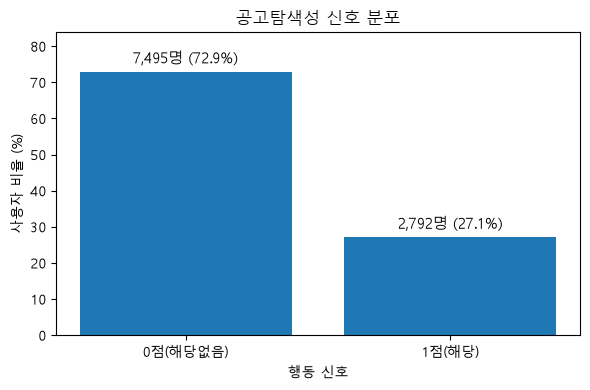

In [99]:
# 공고탐색성 최종 점수화
# 사용자별 평균 조회 후 지원시간 3분 이내 → 1점
# 그 외 사용자 → 0점

# 전체 지원 사용자 기준 테이블 생성
view_score_df = (
    app_job_df[['user_uuid']]
    .dropna()
    .drop_duplicates()
    .copy()
)

# 사용자별 평균 조회 후 지원시간 결합
view_score_df = view_score_df.merge(
    user_view_apply[
        ['user_uuid', '평균조회후지원시간_분', '조회지원건수']
    ],
    on='user_uuid',
    how='left',
    validate='one_to_one'
)

# 공고탐색성 점수 부여
view_score_df['view_score'] = (
    view_score_df['평균조회후지원시간_분'] <= 3
).astype(int)

# 전체 사용자 수 검증
print(f'전체 사용자 수: {len(view_score_df):,}명')
print(f'1점 사용자 수: {view_score_df["view_score"].sum():,}명')
print(f'0점 사용자 수: {(view_score_df["view_score"] == 0).sum():,}명')

# 최종 점수 요약표 및 시각화
view_summary = summarize_score(
    view_score_df,
    'view_score',
    '공고탐색성'
)

#### 결과 해석

전체 지원 사용자 **10,287명**을 대상으로 공고탐색성 점수를 부여한 결과, **1점은 2,792명(27.1%)**, **0점은 7,495명(72.9%)**으로 나타났다.

사용자별 평균 조회 후 지원시간이 **3분 이내인 경우 빠른 지원 행동 신호 1점**을 부여하였으며, 그 외 사용자는 0점으로 분류하였다.

다만 0점에는 30분 이내 조회-지원 기록이 확인되지 않은 사용자도 포함되므로, **빠른 지원 행동 신호가 확인되지 않은 사용자**로 해석한다.

최종적으로 공고탐색성은 지원 전 탐색시간이 짧은 행동을 구분하는 지표로 활용하며, 다른 행동 신호와 함께 분석하여 사용자별 지원 패턴을 비교한다.

# 8. 지표 5 — 북마크 탐색성

### 유형 A — 탐색 부족형
- 고유 북마크 공고 수 상위 10%
- 공고 상세조회 수 하위 20%

### 유형 B — 반복 행동형
- 북마크 총 액션 횟수 상위 10%
- 1초 이내 반복 횟수 상위 1%

A 또는 B 중 하나라도 만족하면 `bookmark_score = 1`


In [100]:
display(app_job_df.isna().sum())

print(f"분석 가능한 데이터 수: {len(app_job_df):,}건")

cdate                     0
company_uuid_app          0
job_uuid                  0
user_uuid                 0
application_uuid          0
cdate_kst_app             0
cdate_kst_job          1120
mdate_kst              1120
job_field              1120
career_type_string     1120
end_date              20018
allow_remote           1120
can_show_salary        1120
company_uuid_job       1120
dtype: int64

분석 가능한 데이터 수: 92,526건


## 8-1. 북마크 -> 지원 퍼널 구축

같은 사용자가 같은 공고를 북마크 한 뒤 지원했는가?

In [101]:
# 지원 및 북마크 시각 정의
app_funnel = app_df.copy()
jb_funnel = jb_df.copy()

app_funnel['app_at'] = pd.to_datetime(
    app_funnel['cdate_kst'], errors='coerce'
)

jb_funnel['bm_at'] = pd.to_datetime(
    jb_funnel['cdate_kst'], errors='coerce'
)

# 동일 사용자·공고의 최초 지원 시각
a = (
    app_funnel
    .sort_values('app_at')
    .drop_duplicates(['user_uuid', 'job_uuid'])
    [['user_uuid', 'job_uuid', 'app_at']]
)

# 동일 사용자·공고의 최초 북마크 시각
b = (
    jb_funnel
    .sort_values('bm_at')
    .drop_duplicates(['user_uuid', 'job_uuid'])
    [['user_uuid', 'job_uuid', 'bm_at']]
)

# 북마크와 지원 기록 연결
funnel = b.merge(
    a,
    on=['user_uuid', 'job_uuid'],
    how='outer',
    validate='one_to_one'
)

funnel['bookmarked'] = funnel['bm_at'].notna().astype(int)
funnel['applied'] = funnel['app_at'].notna().astype(int)

# 북마크부터 지원까지의 시간
funnel['time_diff_seconds'] = (
    funnel['app_at'] - funnel['bm_at']
).dt.total_seconds()

# 사용자 행동 유형 분류
conditions = [
    (funnel['bookmarked'] == 1) & (funnel['applied'] == 1) & (funnel['time_diff_seconds'] > 0),
    (funnel['bookmarked'] == 1) & (funnel['applied'] == 1) & (funnel['time_diff_seconds'] < 0),
    (funnel['bookmarked'] == 1) & (funnel['applied'] == 1) & (funnel['time_diff_seconds'] == 0),
    (funnel['bookmarked'] == 1) & (funnel['applied'] == 0),
    (funnel['bookmarked'] == 0) & (funnel['applied'] == 1)
]

choices = [
    '북마크후지원',
    '지원후북마크',
    '동시발생',
    '북마크만',
    '지원만'
]

funnel['path_type'] = np.select(
    conditions,
    choices,
    default='기타'
)

display(funnel['path_type'].value_counts())

path_type
북마크만      98296
지원만       78721
북마크후지원     9081
지원후북마크     1443
Name: count, dtype: int64

,행동경로,건수,비율(%)
0,북마크만,98296,52.4
1,지원만,78721,42.0
2,북마크후지원,9081,4.8
3,지원후북마크,1443,0.8


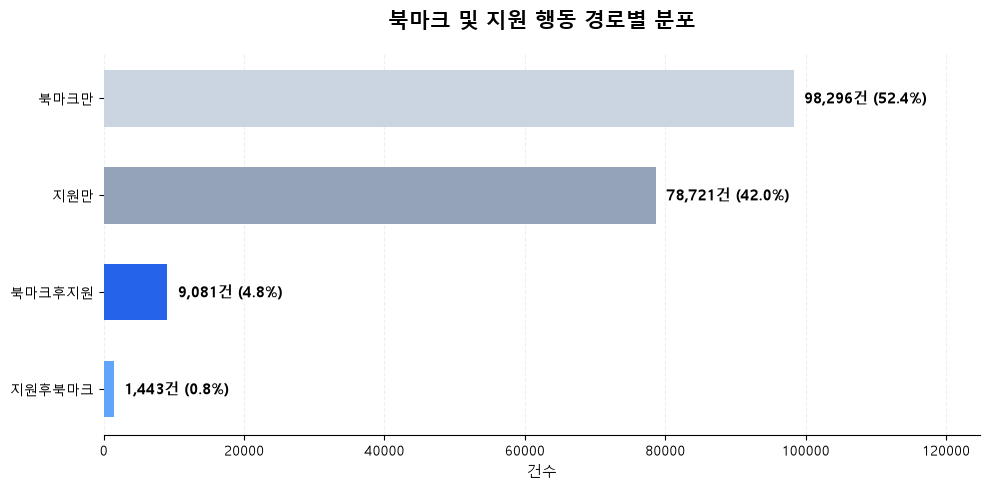

In [102]:
# 1. 행동 경로별 건수 집계
path_order = [
    '북마크만',
    '지원만',
    '북마크후지원',
    '지원후북마크'
]

path_summary = (
    funnel['path_type']
    .value_counts()
    .reindex(path_order, fill_value=0)
    .reset_index()
)

path_summary.columns = ['행동경로', '건수']

# 전체 사용자-공고 쌍 기준 비율
path_summary['비율(%)'] = (
    path_summary['건수'] / path_summary['건수'].sum() * 100
).round(1)

display(path_summary)

# 2. 가로 막대그래프
fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    '#CBD5E1',
    '#94A3B8',
    '#2563EB',
    '#60A5FA'
]

bars = ax.barh(
    path_summary['행동경로'],
    path_summary['건수'],
    color=colors,
    height=0.58
)

# 건수 + 비율 레이블
max_count = path_summary['건수'].max()

for bar, count, ratio in zip(
    bars,
    path_summary['건수'],
    path_summary['비율(%)']
):
    ax.text(
        bar.get_width() + max_count * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{count:,}건 ({ratio:.1f}%)',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

# 3. 차트 디자인
ax.set_title(
    '북마크 및 지원 행동 경로별 분포',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('건수', fontsize=11)
ax.set_ylabel('')

ax.invert_yaxis()
ax.set_xlim(0, max_count * 1.27)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

- 북마크만, 지원만이 대부분을 차지하며, 북마크후지원은 9,081건으로 상대적으로 적음

- 북마크와 지원이 반드시 연결되는 것은 아니며, 북마크 후 실제 지원으로 이어지는 행동은 일부에 해당함.
- 북마크 없이 바로 지원하는 지원만이 78,711건으로 상당한 규모를 차지함.
- 지원만 사용자 안에서도 지원 행동의 강도가 다양할 수 있으므로, 지원 횟수·로그 행동과 함께 확인할 필요가 있음.

## 8-2. 사용자별 고유 북마크 공고수 분포

### 8-2-1. 사용자별 고유 북마크 공고 수 집계

In [103]:
# 사용자별 고유 북마크 공고 수 집계
n_bookmark = (
    jb_df.groupby('user_uuid')['job_uuid']
    .nunique()
    .rename('고유북마크공고수')
    .reset_index()
)

# 전체 지원 사용자 기준 결합
bookmark_count_df = (
    app_df[['user_uuid']]
    .drop_duplicates()
    .merge(n_bookmark, on='user_uuid', how='left')
)

bookmark_count_df['고유북마크공고수'] = (
    bookmark_count_df['고유북마크공고수']
    .fillna(0)
    .astype(int)
)

# 사용자별 북마크 수 분포 확인
bookmark_count_summary = (
    bookmark_count_df['고유북마크공고수']
    .describe(percentiles=[.10, .20, .25, .50, .75, .80, .90, .95, .99])
    .round(2)
)

display(bookmark_count_df.head())
display(bookmark_count_summary)

,user_uuid,고유북마크공고수
0,2ece8d7d-79b6-4522-928b-8dbae8843fab,0
1,24ffac10-a46e-4adb-af66-0074d259c809,10
2,40196d59-ab7c-4951-8a5b-eb87aac0a08b,1
3,3e20b9ee-48bc-46cd-9713-d629f0a51b59,0
4,2bc97037-032e-4137-93d4-feebaa1c2524,10


count    10287.00
mean         5.91
std         15.04
min          0.00
10%          0.00
20%          0.00
25%          0.00
50%          1.00
75%          6.00
80%          8.00
90%         16.00
95%         27.00
99%         65.00
max        418.00
Name: 고유북마크공고수, dtype: float64

사용자 대부분이 적은 수의 공고를 북마크하며, 북마크 수가 증가할수록 해당 사용자 수는 감소한다.  

갑자기 값이 크게 증가한 P90은 16건으로, 북마크 행동이 상대적으로 많은 사용자를 구분하기 위한 후보 기준으로 활용할 수 있다.

### 8-2-2. 북마크 수 분포 시각화 — 상위 1% 제외

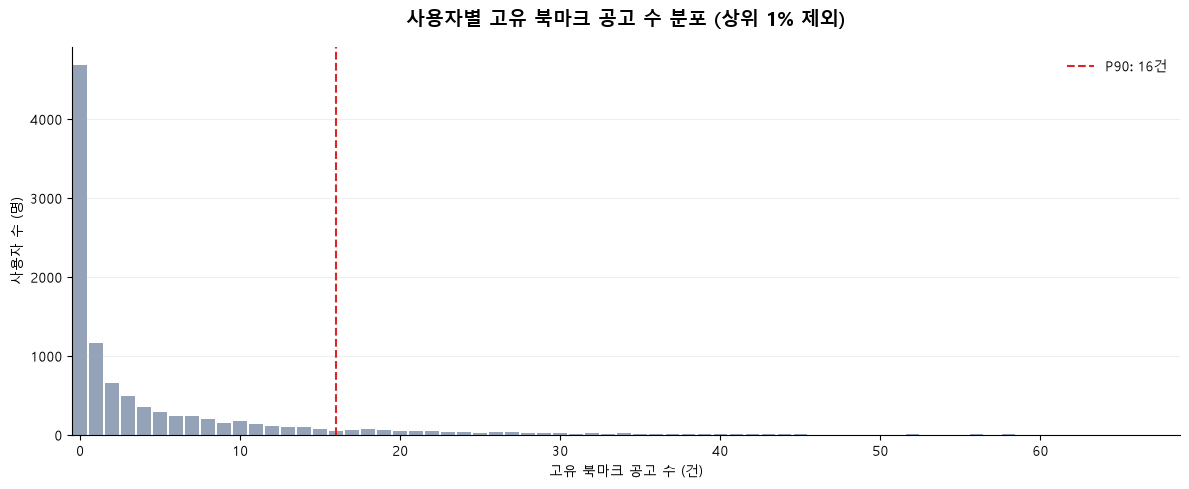

In [104]:
# 상위 1%를 제외한 북마크 수 분포
bookmark_p90 = bookmark_count_df['고유북마크공고수'].quantile(0.90)
bookmark_p99 = bookmark_count_df['고유북마크공고수'].quantile(0.99)

bookmark_plot = bookmark_count_df[
    bookmark_count_df['고유북마크공고수'] <= bookmark_p99
].copy()

# 북마크 수별 사용자 수
bookmark_freq = (
    bookmark_plot['고유북마크공고수']
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    bookmark_freq.index,
    bookmark_freq.values,
    color='#94A3B8',
    width=0.85
)

# P90 기준선
ax.axvline(
    x=bookmark_p90,
    color='#DC2626',
    linestyle='--',
    linewidth=1.5,
    label=f'P90: {bookmark_p90:.0f}건'
)

ax.set_title(
    '사용자별 고유 북마크 공고 수 분포 (상위 1% 제외)',
    fontsize=14,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('고유 북마크 공고 수 (건)')
ax.set_ylabel('사용자 수 (명)')

ax.set_xlim(left=-0.5)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### 8-2-3. 전체 북마크 수 분포 — 로그 스케일

북마크를 매우 많이 하는 사용자까지 포함하여 전체 분포 확인

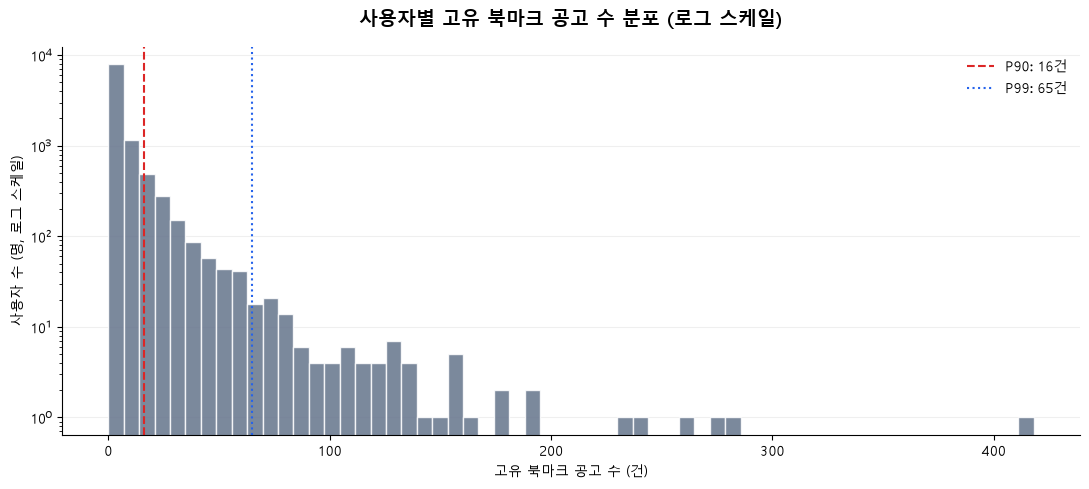

In [105]:
# 전체 사용자별 북마크 수 분포 (로그 스케일)

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    bookmark_count_df['고유북마크공고수'],
    bins=60,
    color='#64748B',
    edgecolor='white',
    alpha=0.85
)

ax.set_yscale('log')

ax.axvline(
    x=bookmark_p90,
    color='#DC2626',
    linestyle='--',
    linewidth=1.5,
    label=f'P90: {bookmark_p90:.0f}건'
)

ax.axvline(
    x=bookmark_p99,
    color='#2563EB',
    linestyle=':',
    linewidth=1.5,
    label=f'P99: {bookmark_p99:.0f}건'
)

ax.set_title(
    '사용자별 고유 북마크 공고 수 분포 (로그 스케일)',
    fontsize=14,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('고유 북마크 공고 수 (건)')
ax.set_ylabel('사용자 수 (명, 로그 스케일)')

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

일부 사용자는 100건 이상의 공고를 북마크하며 최대 418건까지 관찰된다.  

전체 분포가 오른쪽으로 긴 꼬리를 가지므로, 평균보다는 분위수 기반 기준이 극단값의 영향을 줄이는 데 적합하다.

### 8-2-4. 북마크 수 박스프롯

C:\Users\user\AppData\Local\Temp\ipykernel_4708\1629380708.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


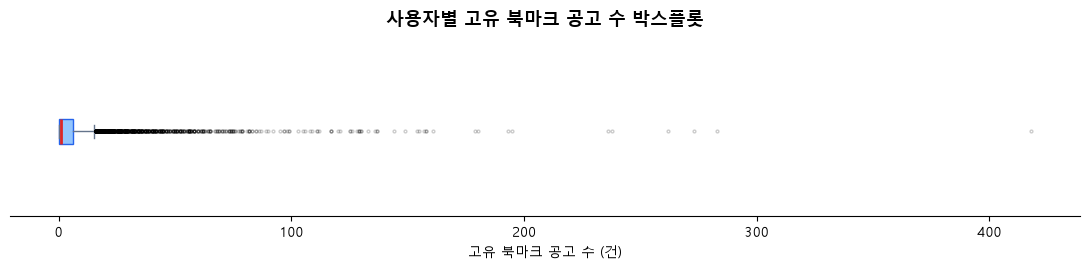

In [106]:
# 사용자별 북마크 수 박스플롯
fig, ax = plt.subplots(figsize=(11, 2.8))

ax.boxplot(
    bookmark_count_df['고유북마크공고수'].dropna(),
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='#93C5FD', edgecolor='#2563EB'),
    medianprops=dict(color='#DC2626', linewidth=2),
    whiskerprops=dict(color='#64748B'),
    capprops=dict(color='#64748B'),
    flierprops=dict(marker='o', markersize=2, alpha=0.2)
)

ax.set_title(
    '사용자별 고유 북마크 공고 수 박스플롯',
    fontsize=13,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('고유 북마크 공고 수 (건)')
ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

대부분의 사용자가 낮은 북마크 수에 집중되어 있지만, 상위 구간에서는 다수의 이상치가 나타난다. 

다만 북마크 수가 많다는 사실만으로 비정상 행동을 판단할 수 없으므로, 공고 상세조회 및 반복 액션 행동을 추가로 확인한다.

## 8-3. 북마크 관련 로그 구조 확인

로그에서 실제 북마크 추가 또는 취소가 된 이벤트를 구분하고, 반복행동 분석에 사용할 데이터 추출

In [107]:
# 북마크 관련 로그 추출
bookmark_logs = log_df[
    log_df['URL'].fillna('').str.contains('bookmark', case=False, na=False)
].copy()

bookmark_logs['method'] = bookmark_logs['method'].str.upper().str.strip()

# URL 및 HTTP 메서드별 로그 분포
bookmark_pivot = pd.crosstab(
    bookmark_logs['URL'],
    bookmark_logs['method'],
    margins=True
)

print(f'전체 북마크 관련 로그: {len(bookmark_logs):,}건')

전체 북마크 관련 로그: 163,840건


In [108]:
# 공고 북마크 추가(PUT) 및 취소(DELETE) 로그 추출
bookmark_action_logs = bookmark_logs[
    (bookmark_logs['URL'] == 'api/jobs/id/bookmark') &
    (bookmark_logs['method'].isin(['PUT', 'DELETE']))
].copy()

# 한국시간 변환 컬럼 통일
time_col = 'timestamp_kst' if 'timestamp_kst' in bookmark_action_logs.columns else 'ts_kst'

bookmark_action_logs['action_at'] = pd.to_datetime(
    bookmark_action_logs[time_col],
    errors='coerce'
)

bookmark_action_logs = bookmark_action_logs.dropna(
    subset=['user_uuid', 'action_at']
).copy()

print(f'공고 북마크 액션 로그: {len(bookmark_action_logs):,}건')
print(f'공고 북마크 액션 사용자: {bookmark_action_logs["user_uuid"].nunique():,}명')

display(bookmark_action_logs.head())

공고 북마크 액션 로그: 89,260건
공고 북마크 액션 사용자: 6,413명


,user_uuid,URL,timestamp,date,response_code,method,timestamp_kst,action_at
1147,d7c84302-545f-4714-bcd1-0cc4328a0f89,api/jobs/id/bookmark,2022-11-04 08:13:12.811277+00:00,2022-11-04,200,PUT,2022-11-04 17:13:12.811277+09:00,2022-11-04 17:13:12.811277+09:00
1683,d7c84302-545f-4714-bcd1-0cc4328a0f89,api/jobs/id/bookmark,2022-11-01 04:10:31.720186+00:00,2022-11-01,200,PUT,2022-11-01 13:10:31.720186+09:00,2022-11-01 13:10:31.720186+09:00
2751,d7c84302-545f-4714-bcd1-0cc4328a0f89,api/jobs/id/bookmark,2022-12-14 08:53:44.361786+00:00,2022-12-14,200,PUT,2022-12-14 17:53:44.361786+09:00,2022-12-14 17:53:44.361786+09:00
3688,d7c84302-545f-4714-bcd1-0cc4328a0f89,api/jobs/id/bookmark,2022-10-10 08:40:30.895724+00:00,2022-10-10,200,PUT,2022-10-10 17:40:30.895724+09:00,2022-10-10 17:40:30.895724+09:00
3823,d7c84302-545f-4714-bcd1-0cc4328a0f89,api/jobs/id/bookmark,2022-12-01 13:48:21.064920+00:00,2022-12-01,200,DELETE,2022-12-01 22:48:21.064920+09:00,2022-12-01 22:48:21.064920+09:00


북마크 관련 로그에는 공고 북마크 추가·취소 외에도 북마크 목록 조회와 기업 북마크 등이 포함되어 있다. 따라서 공고 북마크 엔드포인트의 PUT·DELETE 요청만 추출하여 실제 공고 북마크 액션을 분석한다.

단, PUT·DELETE 로그는 서버에 기록된 요청이며, 성공한 행동만 분석하려면 응답 코드가 200번대인지 확인해야 한다.

## 8-4. 사용자별 북마크 추가·취소 행동 분석

### 8-4-1. 사용자별 액션 횟수 집계

In [109]:
# 사용자별 북마크 추가·취소 횟수
action_counts = (
    bookmark_action_logs
    .groupby(['user_uuid', 'method'])
    .size()
    .unstack(fill_value=0)
    .rename(columns={
        'PUT': '북마크_추가횟수',
        'DELETE': '북마크_취소횟수'
    })
    .reset_index()
)

for col in ['북마크_추가횟수', '북마크_취소횟수']:
    if col not in action_counts.columns:
        action_counts[col] = 0

action_counts['북마크_총액션횟수'] = (
    action_counts['북마크_추가횟수'] +
    action_counts['북마크_취소횟수']
)

# 기존 북마크 분석 테이블에 결합
bookmark_analysis_df = bookmark_count_df.merge(
    action_counts[
        ['user_uuid', '북마크_추가횟수', '북마크_취소횟수', '북마크_총액션횟수']
    ],
    on='user_uuid',
    how='left'
)

action_cols = [
    '북마크_추가횟수',
    '북마크_취소횟수',
    '북마크_총액션횟수'
]

bookmark_analysis_df[action_cols] = (
    bookmark_analysis_df[action_cols].fillna(0).astype(int)
)

display(bookmark_analysis_df.head())

,user_uuid,고유북마크공고수,북마크_추가횟수,북마크_취소횟수,북마크_총액션횟수
0,2ece8d7d-79b6-4522-928b-8dbae8843fab,0,0,0,0
1,24ffac10-a46e-4adb-af66-0074d259c809,10,9,0,9
2,40196d59-ab7c-4951-8a5b-eb87aac0a08b,1,1,0,1
3,3e20b9ee-48bc-46cd-9713-d629f0a51b59,0,0,0,0
4,2bc97037-032e-4137-93d4-feebaa1c2524,10,17,10,27


### 8-4-2. 북마크 기록과 액션 로그 비교

In [110]:
# 북마크 보유 여부와 액션 로그 유무 비교
bookmark_analysis_df['북마크보유'] = (
    bookmark_analysis_df['고유북마크공고수'] > 0
)

bookmark_analysis_df['액션로그보유'] = (
    bookmark_analysis_df['북마크_총액션횟수'] > 0
)

bookmark_record_summary = (
    bookmark_analysis_df
    .groupby(['북마크보유', '액션로그보유'])
    .size()
    .reset_index(name='사용자수')
)

bookmark_record_summary['비율(%)'] = (
    bookmark_record_summary['사용자수'] /
    len(bookmark_analysis_df) * 100
).round(1)

display(bookmark_record_summary)

,북마크보유,액션로그보유,사용자수,비율(%)
0,False,False,4398,42.8
1,False,True,285,2.8
2,True,False,579,5.6
3,True,True,5025,48.8


## 8-5. 공고 상세조회 수 분포 및 탐색 부족형 정의

### 8-5-1. 공고 상세조회 횟수 집계

전체 지원 사용자 기준

In [111]:
# 공고 상세조회 로그 추출
job_detail_logs = log_df[
    (log_df['URL'] == 'jobs/id/id_title') &
    (log_df['method'].str.upper() == 'GET')
].copy()

# 사용자별 상세조회 횟수
detail_view_counts = (
    job_detail_logs
    .groupby('user_uuid')
    .size()
    .rename('공고상세조회수')
    .reset_index()
)

bookmark_analysis_df = bookmark_analysis_df.merge(
    detail_view_counts,
    on='user_uuid',
    how='left'
)

bookmark_analysis_df['공고상세조회수'] = (
    bookmark_analysis_df['공고상세조회수']
    .fillna(0)
    .astype(int)
)

display(
    bookmark_analysis_df[
        ['고유북마크공고수', '공고상세조회수']
    ].describe(percentiles=[.10, .20, .25, .50, .75, .90, .95])
)

,고유북마크공고수,공고상세조회수
count,10287.000000,10287.000000
mean,5.908331,97.214154
std,15.041412,176.045673
min,0.000000,0.000000
10%,0.000000,4.000000
20%,0.000000,10.000000
25%,0.000000,14.000000
50%,1.000000,41.000000
75%,6.000000,107.000000
90%,16.000000,235.000000


### 8-5-2. 공고 상세조회 분포 시각화 - 상위 1% 제외

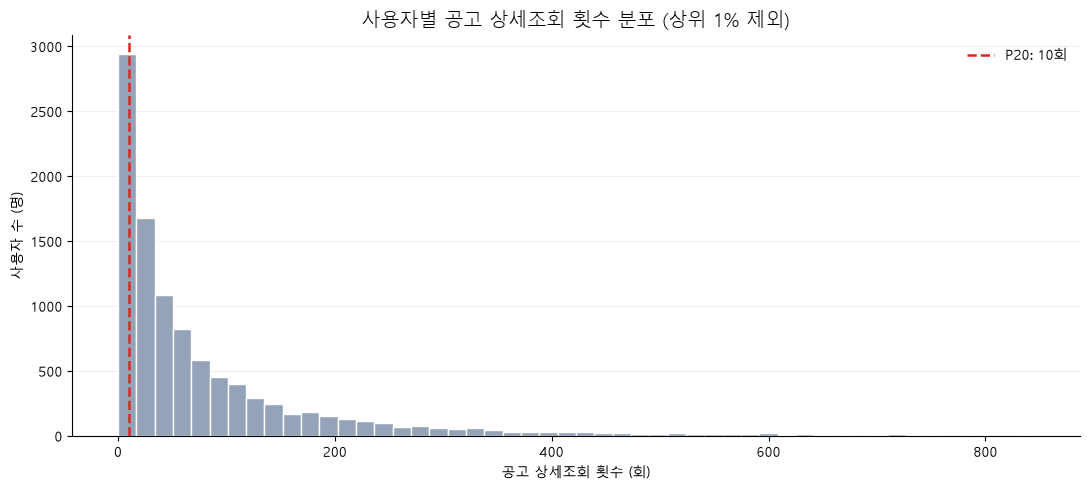

In [112]:
# 상위 1% 제외한 상세조회 횟수 분포
view_p20 = bookmark_analysis_df['공고상세조회수'].quantile(0.20)
view_p99 = bookmark_analysis_df['공고상세조회수'].quantile(0.99)

plot_views = bookmark_analysis_df.loc[
    bookmark_analysis_df['공고상세조회수'] <= view_p99,
    '공고상세조회수'
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    plot_views,
    bins=50,
    color='#94A3B8',
    edgecolor='white'
)

ax.axvline(
    view_p20,
    color='#DC2626',
    linestyle='--',
    linewidth=1.8,
    label=f'P20: {view_p20:.0f}회'
)

ax.set_title('사용자별 공고 상세조회 횟수 분포 (상위 1% 제외)', fontsize=14)
ax.set_xlabel('공고 상세조회 횟수 (회)')
ax.set_ylabel('사용자 수 (명)')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### 8-5-3. 유형A - 탐색 부족형 후보군

In [113]:
# 사용자 분포 기반 임계값
bookmark_p90 = bookmark_analysis_df['고유북마크공고수'].quantile(0.90)
view_p20 = bookmark_analysis_df['공고상세조회수'].quantile(0.20)

# 북마크 상위 10% + 상세조회 하위 20%
cond_low_engagement = (
    (bookmark_analysis_df['고유북마크공고수'] >= bookmark_p90) &
    (bookmark_analysis_df['공고상세조회수'] <= view_p20)
)

print(f'북마크 상위 10% 기준: {bookmark_p90:.0f}건 이상')
print(f'상세조회 하위 20% 기준: {view_p20:.0f}회 이하')
print(f'탐색 부족형 후보군: {cond_low_engagement.sum():,}명')

display(
    bookmark_analysis_df.loc[
        cond_low_engagement,
        ['user_uuid', '고유북마크공고수', '공고상세조회수']
    ].head(10)
)

북마크 상위 10% 기준: 16건 이상
상세조회 하위 20% 기준: 10회 이하
탐색 부족형 후보군: 12명


,user_uuid,고유북마크공고수,공고상세조회수
459,b04dace3-2500-4a29-9ea6-89e800916008,19,5
1108,a09fe35f-8953-4614-862d-b0d696097a37,18,3
1943,367bc380-d06b-487b-936e-edd33397da01,31,10
2218,416b6358-af90-4625-b8af-8aa0a074c659,24,10
3300,77823f73-5c50-4411-b187-c00e7089fba7,18,2
5096,88be49ba-674d-469a-b329-47b3b295422b,31,7
5850,c326eda2-3fcc-404f-82cc-fa2a471ad682,35,6
6709,c80b7fdd-65ef-46c5-b317-4a216fd4c1aa,41,7
8227,7ff9be34-c9bc-4c42-b27e-53bdc954da82,22,6
8741,fff3440e-7c0a-485b-a392-c41023060e96,20,9


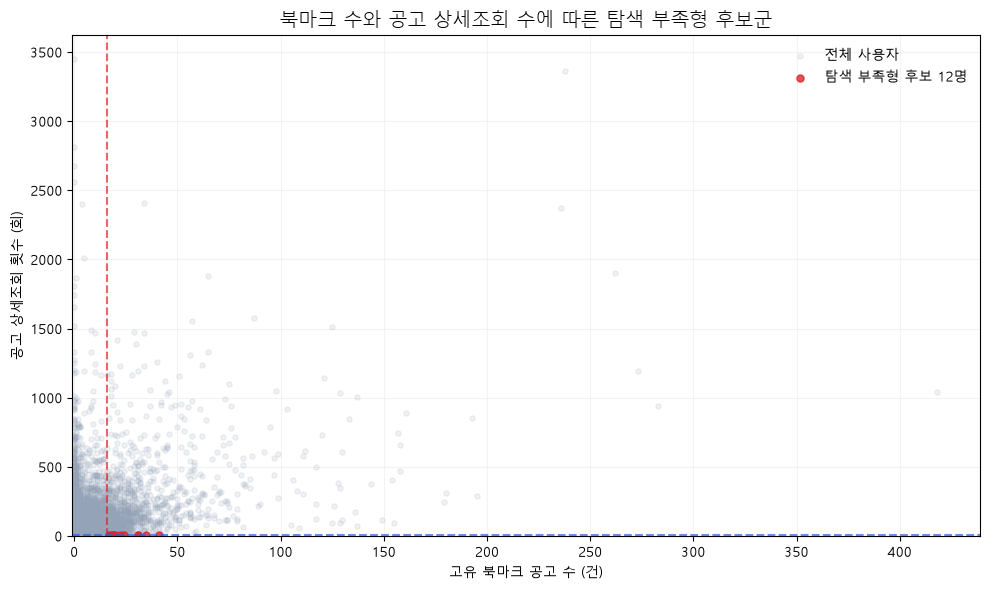

In [114]:
# 유형A 시각화 - 북마크 수와 상세조회 수 관계
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    bookmark_analysis_df['고유북마크공고수'],
    bookmark_analysis_df['공고상세조회수'],
    s=14,
    alpha=0.15,
    color='#94A3B8',
    label='전체 사용자'
)

ax.scatter(
    bookmark_analysis_df.loc[cond_low_engagement, '고유북마크공고수'],
    bookmark_analysis_df.loc[cond_low_engagement, '공고상세조회수'],
    s=26,
    alpha=0.8,
    color='#DC2626',
    label=f'탐색 부족형 후보 {cond_low_engagement.sum():,}명'
)

ax.axvline(bookmark_p90, color='#DC2626', linestyle='--', alpha=0.7)
ax.axhline(view_p20, color='#2563EB', linestyle='--', alpha=0.7)

ax.set_title('북마크 수와 공고 상세조회 수에 따른 탐색 부족형 후보군', fontsize=14)
ax.set_xlabel('고유 북마크 공고 수 (건)')
ax.set_ylabel('공고 상세조회 횟수 (회)')
ax.set_xlim(left=-1)
ax.set_ylim(bottom=-1)
ax.grid(alpha=0.15)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

## 8-6. 북마크 액션 규모별 행동 비교

In [115]:
# 사용자별 고유 지원 공고 수
applied_job_counts = (
    app_df.groupby('user_uuid')['job_uuid']
    .nunique()
    .rename('고유지원공고수')
    .reset_index()
)

bookmark_analysis_df = bookmark_analysis_df.merge(
    applied_job_counts,
    on='user_uuid',
    how='left'
)

bookmark_analysis_df['고유지원공고수'] = (
    bookmark_analysis_df['고유지원공고수']
    .fillna(0)
    .astype(int)
)

# 북마크 액션 규모 구간화
bins = [-1, 0, 5, 20, 50, np.inf]
labels = ['0회', '1~5회', '6~20회', '21~50회', '51회 이상']

bookmark_analysis_df['북마크액션구간'] = pd.cut(
    bookmark_analysis_df['북마크_총액션횟수'],
    bins=bins,
    labels=labels
)

action_group_summary = (
    bookmark_analysis_df
    .groupby('북마크액션구간', observed=False)
    .agg(
        사용자수=('user_uuid', 'nunique'),
        평균고유지원공고수=('고유지원공고수', 'mean'),
        평균고유북마크공고수=('고유북마크공고수', 'mean')
    )
    .reset_index()
)

action_group_summary[
    ['평균고유지원공고수', '평균고유북마크공고수']
] = action_group_summary[
    ['평균고유지원공고수', '평균고유북마크공고수']
].round(1)

display(action_group_summary)

,북마크액션구간,사용자수,평균고유지원공고수,평균고유북마크공고수
0,0회,4977,6.8,0.4
1,1~5회,2608,8.5,3.0
2,6~20회,1656,9.5,9.8
3,21~50회,692,12.3,22.1
4,51회 이상,354,25.7,54.4


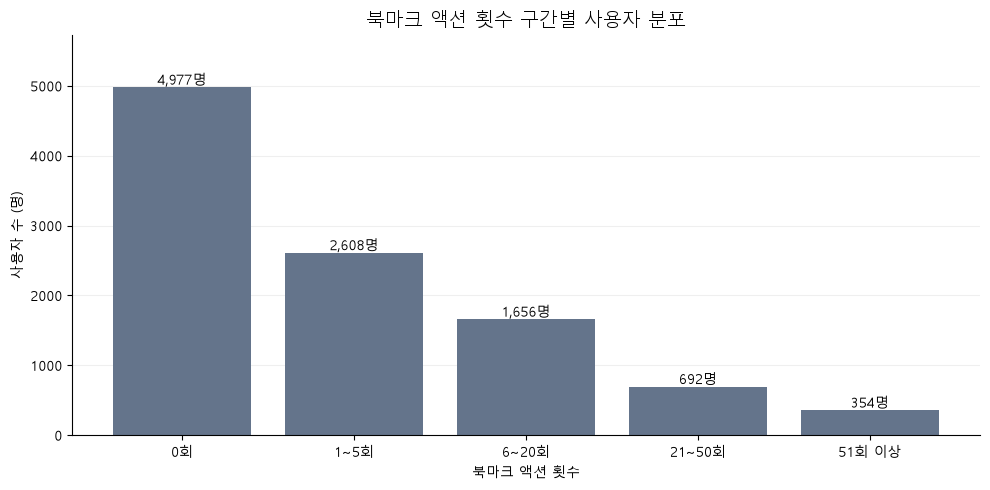

In [116]:
# 시각화 - 북마크 액션 구간별 사용자 수
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    action_group_summary['북마크액션구간'].astype(str),
    action_group_summary['사용자수'],
    color='#64748B'
)

for bar, count in zip(bars, action_group_summary['사용자수']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count:,}명',
        ha='center',
        va='bottom',
        fontsize=10
    )

ax.set_title('북마크 액션 횟수 구간별 사용자 분포', fontsize=14)
ax.set_xlabel('북마크 액션 횟수')
ax.set_ylabel('사용자 수 (명)')
ax.set_ylim(0, action_group_summary['사용자수'].max() * 1.15)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

## 8-7. 유형B - 초단기 반복 행동 분석

### 8-7-1. 북마크 액션 간 시간 간격 계산

In [117]:
# 사용자별 북마크 액션 시간순 정렬
sorted_logs = bookmark_action_logs.sort_values(
    ['user_uuid', 'action_at']
).copy()

# 직전 액션과의 시간 차이
sorted_logs['time_diff_sec'] = (
    sorted_logs.groupby('user_uuid')['action_at']
    .diff()
    .dt.total_seconds()
)

# 사용자별 시간 기준 반복 횟수 집계
rapid_action_summary = (
    sorted_logs.groupby('user_uuid')
    .agg(
        반복_1초=('time_diff_sec', lambda x: (x <= 1).sum()),
        반복_10초=('time_diff_sec', lambda x: (x <= 10).sum()),
        반복_60초=('time_diff_sec', lambda x: (x <= 60).sum())
    )
    .reset_index()
)

bookmark_analysis_df = bookmark_analysis_df.merge(
    rapid_action_summary,
    on='user_uuid',
    how='left'
)

rapid_cols = ['반복_1초', '반복_10초', '반복_60초']

bookmark_analysis_df[rapid_cols] = (
    bookmark_analysis_df[rapid_cols]
    .fillna(0)
    .astype(int)
)

display(
    bookmark_analysis_df[rapid_cols]
    .describe(percentiles=[.50, .90, .95, .99])
)

,반복_1초,반복_10초,반복_60초
count,10287.000000,10287.000000,10287.000000
mean,0.243803,1.276854,2.632838
std,1.909037,6.861945,12.735414
min,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
90%,0.000000,2.000000,6.000000
95%,1.000000,6.000000,12.000000
99%,5.000000,22.000000,41.000000
max,64.000000,280.000000,569.000000


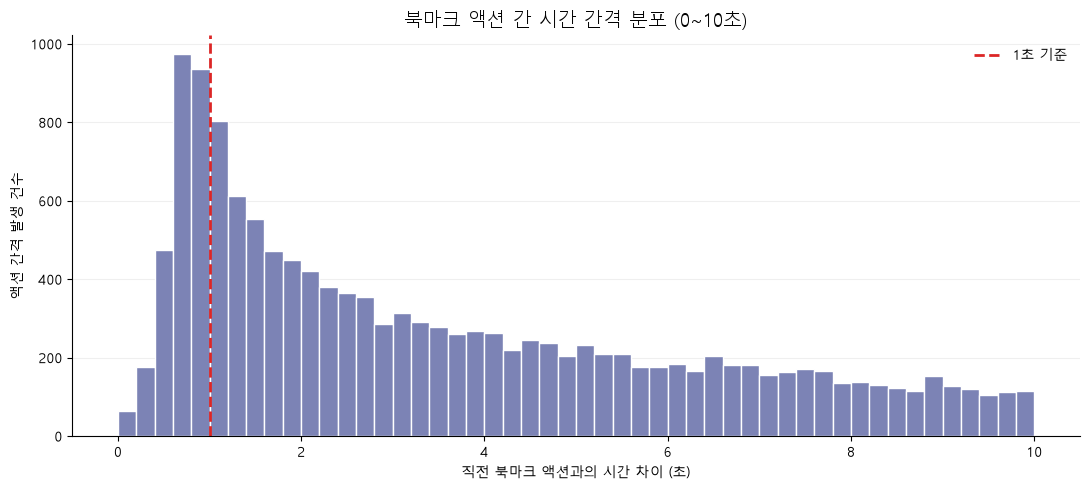

In [118]:
# 0~10초 액션 간격 분포
rapid_intervals = sorted_logs.loc[
    sorted_logs['time_diff_sec'].between(0, 10),
    'time_diff_sec'
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    rapid_intervals,
    bins=np.arange(0, 10.2, 0.2),
    color='#7C83B5',
    edgecolor='white'
)

ax.axvline(
    1,
    color='#DC2626',
    linestyle='--',
    linewidth=2,
    label='1초 기준'
)

ax.set_title('북마크 액션 간 시간 간격 분포 (0~10초)', fontsize=14)
ax.set_xlabel('직전 북마크 액션과의 시간 차이 (초)')
ax.set_ylabel('액션 간격 발생 건수')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

1초 이내의 짧은 간격에서 액션이 집중되어있으므로 초단기 반복 행동이 존재한다고 볼 수 있음.

## 8-8. 임계값 민감도 분석

In [119]:
# 임계값 변화에 따른 후보군 규모 비교 함수
def threshold_simulation(df, col, thresholds, compare_col):
    results = []

    for threshold in thresholds:
        selected = df[df[col] >= threshold]

        results.append({
            '임계값': threshold,
            '사용자수': len(selected),
            '사용자비율(%)': round(len(selected) / len(df) * 100, 2),
            '비교지표평균': round(selected[compare_col].mean(), 2)
            if len(selected) > 0 else 0
        })

    return pd.DataFrame(results)


# 1초 이내 반복 횟수 기준 변화
rapid_simulation = threshold_simulation(
    bookmark_analysis_df,
    '반복_1초',
    [5, 10, 15, 20, 25, 30, 50],
    '북마크_총액션횟수'
)

# 전체 북마크 액션 횟수 기준 변화
action_simulation = threshold_simulation(
    bookmark_analysis_df,
    '북마크_총액션횟수',
    [10, 20, 50, 100, 150, 200, 250, 300, 500],
    '반복_1초'
)

print('[1초 이내 반복 횟수 기준 변화]')
display(rapid_simulation)

print('[전체 북마크 액션 횟수 기준 변화]')
display(action_simulation)

[1초 이내 반복 횟수 기준 변화]


,임계값,사용자수,사용자비율(%),비교지표평균
0,5,111,1.08,139.64
1,10,43,0.42,200.23
2,15,20,0.19,261.35
3,20,17,0.17,286.12
4,25,12,0.12,344.42
5,30,10,0.10,369.20
6,50,4,0.04,439.75


[전체 북마크 액션 횟수 기준 변화]


,임계값,사용자수,사용자비율(%),비교지표평균
0,10,1957,19.02,1.19
1,20,1100,10.69,1.93
2,50,361,3.51,4.55
3,100,103,1.00,9.71
4,150,49,0.48,16.31
5,200,32,0.31,19.66
6,250,21,0.20,21.24
7,300,14,0.14,21.86
8,500,2,0.02,34.50


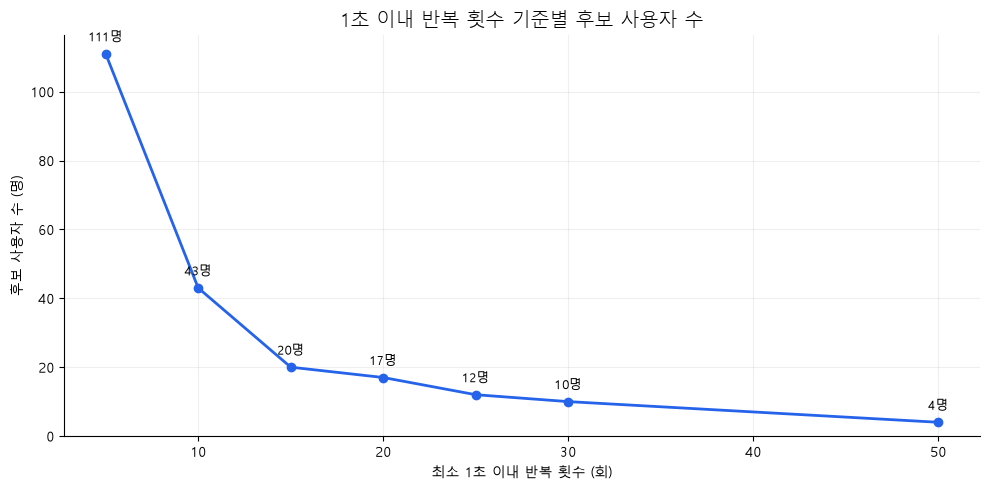

In [120]:
# 시각화 - 임계값별 후보 사용자 수
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    rapid_simulation['임계값'],
    rapid_simulation['사용자수'],
    marker='o',
    linewidth=2,
    color='#2563EB'
)

for x, y in zip(
    rapid_simulation['임계값'],
    rapid_simulation['사용자수']
):
    ax.annotate(
        f'{y:,}명',
        (x, y),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

ax.set_title('1초 이내 반복 횟수 기준별 후보 사용자 수', fontsize=14)
ax.set_xlabel('최소 1초 이내 반복 횟수 (회)')
ax.set_ylabel('후보 사용자 수 (명)')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

## 8-9. 북마크 탐색성 최종 점수화

In [121]:
# 유형 A: 탐색 부족형
threshold_bookmark_p90 = bookmark_analysis_df['고유북마크공고수'].quantile(0.90)
threshold_view_p20 = bookmark_analysis_df['공고상세조회수'].quantile(0.20)

cond_low_engagement = (
    (bookmark_analysis_df['고유북마크공고수'] >= threshold_bookmark_p90) &
    (bookmark_analysis_df['공고상세조회수'] <= threshold_view_p20)
)

# 유형 B: 반복 행동형
threshold_action_p90 = bookmark_analysis_df['북마크_총액션횟수'].quantile(0.90)
threshold_rapid_p99 = bookmark_analysis_df['반복_1초'].quantile(0.99)

cond_repetitive = (
    (bookmark_analysis_df['북마크_총액션횟수'] >= threshold_action_p90) &
    (bookmark_analysis_df['반복_1초'] >= threshold_rapid_p99)
)

print('[최종 북마크 탐색성 임계값]')
print(f'고유 북마크 공고 수 P90: {threshold_bookmark_p90:.0f}건')
print(f'공고 상세조회 수 P20: {threshold_view_p20:.0f}회')
print(f'북마크 총 액션 횟수 P90: {threshold_action_p90:.0f}회')
print(f'1초 이내 반복 횟수 P99: {threshold_rapid_p99:.0f}회')

[최종 북마크 탐색성 임계값]
고유 북마크 공고 수 P90: 16건
공고 상세조회 수 P20: 10회
북마크 총 액션 횟수 P90: 21회
1초 이내 반복 횟수 P99: 5회


In [122]:
# A/B 유형 분류
bookmark_analysis_df['북마크행동유형'] = np.select(
    [
        cond_low_engagement & cond_repetitive,
        cond_low_engagement,
        cond_repetitive
    ],
    [
        '복합형',
        '탐색부족형',
        '반복행동형'
    ],
    default='해당없음'
)

# 최종 점수
bookmark_analysis_df['bookmark_score'] = (
    cond_low_engagement | cond_repetitive
).astype(int)

# 유형별 사용자 분포
bookmark_type_summary = (
    bookmark_analysis_df['북마크행동유형']
    .value_counts()
    .rename_axis('행동유형')
    .reset_index(name='사용자수')
)

bookmark_type_summary['비율(%)'] = (
    bookmark_type_summary['사용자수'] /
    len(bookmark_analysis_df) * 100
).round(1)

display(bookmark_type_summary)

,행동유형,사용자수,비율(%)
0,해당없음,10167,98.8
1,반복행동형,108,1.0
2,탐색부족형,12,0.1


,score,label,user_count,ratio
0,0,0점(해당없음),10167,98.8
1,1,1점(해당),120,1.2


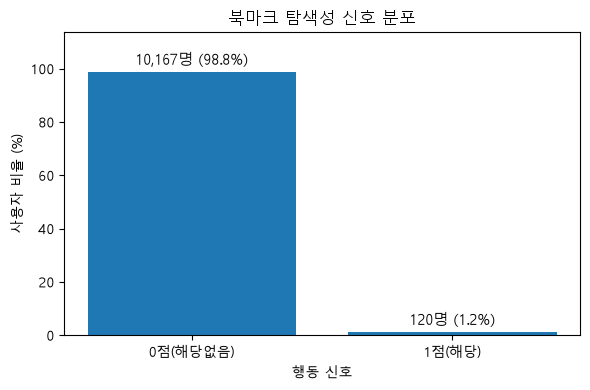

In [123]:
bookmark_summary = summarize_score(
    bookmark_analysis_df,
    'bookmark_score',
    '북마크 탐색성'
)

#### 결과 해석
사용자별 고유 북마크 공고 수, 공고 상세조회 횟수, 북마크 추가·취소 액션 및 초단기 반복 행동을 분석하여 두 가지 행동 유형을 정의하였다.


- 유형 A — 탐색 부족형: 고유 북마크 공고 수가 상위 10% 이상이면서 공고 상세조회 횟수가 하위 20% 이하인 사용자.

- 유형 B — 반복 행동형: 북마크 총 액션 횟수가 상위 10% 이상이면서 1초 이내 반복 액션 횟수가 상위 1% 이상인 사용자.

- 두 유형 중 하나 이상에 해당하는 사용자에게 북마크 탐색성 1점을 부여하였다. 해당 기준은 실제 허수지원 여부를 확정하는 기준이 아니라, 상대적으로 특이한 북마크 행동을 보이는 사용자를 구분하기 위한 탐색적 기준이다.

# 9. 행동 신호 5개 지표 종합 요약

In [124]:
display(volume_summary)
display(concentration_summary)
display(diversity_summary)
display(view_summary)
display(bookmark_summary)

,score,label,user_count,ratio
0,0,0점(해당없음),9742,94.7
1,1,1점(해당),545,5.3


,score,label,user_count,ratio
0,0,0점(해당없음),9882,96.1
1,1,1점(해당),405,3.9


,score,label,user_count,ratio
0,0,0점(해당없음),9151,89.6
1,1,1점(해당),1066,10.4


,score,label,user_count,ratio
0,0,0점(해당없음),7495,72.9
1,1,1점(해당),2792,27.1


,score,label,user_count,ratio
0,0,0점(해당없음),10167,98.8
1,1,1점(해당),120,1.2


## 9-1. 지표별 신호 사용자 수 및 비율

In [125]:
# 5개 지표별 1점 사용자 수 및 비율 요약

# summarize_score() 결과에서 1점 사용자 정보 추출
def get_signal_stats(summary):
    signal = summary.loc[summary['score'] == 1]

    if signal.empty:
        return 0, 0.0

    return (
        int(signal['user_count'].iloc[0]),
        float(signal['ratio'].iloc[0])
    )


# 지표별 최종 기준 및 요약표 연결
metrics = [
    ('대량성', '연속 7일 내 최대 지원 14회 이상', volume_summary),
    ('집중성', f'5회 이상 지원, 5분 이내 연속지원 비율 P90 ({p90_threshold * 100:.1f}%) 이상', concentration_summary),
    ('다양성', '직무 3개 이상 또는 직무 2개에서 빠른·반복 전환', diversity_summary),
    ('공고 탐색성', '평균 조회 후 지원시간 3분 이내', view_summary),
    ('북마크 탐색성', '탐색 부족형 또는 반복 행동형', bookmark_summary)
]


# 최종 요약표 생성
metric_summary = pd.DataFrame([
    {
        '지표': name,
        '기준': criterion,
        '신호 사용자 수': get_signal_stats(summary)[0],
        '신호 비율(%)': get_signal_stats(summary)[1]
    }
    for name, criterion, summary in metrics
])

display(metric_summary)

,지표,기준,신호 사용자 수,신호 비율(%)
0,대량성,연속 7일 내 최대 지원 14회 이상,545,5.3
1,집중성,"5회 이상 지원, 5분 이내 연속지원 비율 P90 (61.1%) 이상",405,3.9
2,다양성,직무 3개 이상 또는 직무 2개에서 빠른·반복 전환,1066,10.4
3,공고 탐색성,평균 조회 후 지원시간 3분 이내,2792,27.1
4,북마크 탐색성,탐색 부족형 또는 반복 행동형,120,1.2


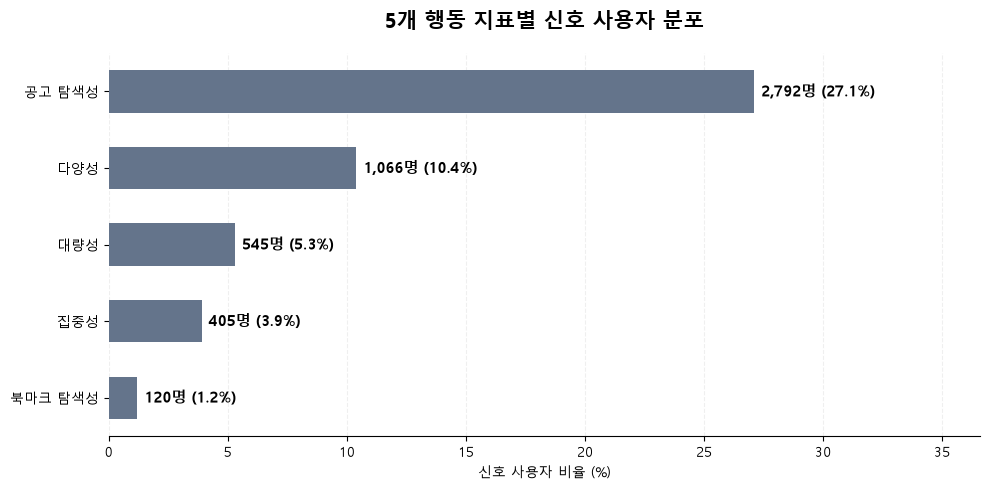

In [126]:
# 지표별 신호 사용자 비율 비교
plot_df = metric_summary.sort_values(
    '신호 비율(%)',
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_df['지표'],
    plot_df['신호 비율(%)'],
    color='#64748B',
    height=0.55
)

# 사용자 수 및 비율 표시
for bar, count, ratio in zip(
    bars,
    plot_df['신호 사용자 수'],
    plot_df['신호 비율(%)']
):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{count:,}명 ({ratio:.1f}%)',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

ax.set_title(
    '5개 행동 지표별 신호 사용자 분포',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('신호 사용자 비율 (%)')
ax.set_ylabel('')

ax.set_xlim(
    0,
    max(plot_df['신호 비율(%)'].max() * 1.35, 5)
)

ax.grid(axis='x', linestyle='--', alpha=0.2)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

5개 행동 지표별로 기준에 해당하는 사용자 수와 비율을 집계하여, 어떤 행동 신호가 상대적으로 많이 나타나는지 비교하였다.

각 지표는 지원량, 지원 간격, 직무 변경, 공고 조회 및 북마크 행동을 서로 다른 관점에서 측정한다. 따라서 개별 지표에 해당한다는 사실만으로 비정상적인 지원 행동이라고 판단하기는 어렵다.

다음 단계에서는 **사용자별 5개 지표 점수를 통합**하고, 여러 행동 신호가 동시에 나타나는 사용자를 구분하여 그룹별 행동 특성을 비교한다.